# 2026 年中国研究生数学建模竞赛 F 题 · 问题一（质量评价与领域配比）
## 问题一的技术路线与主要结论

本 notebook 对应题目要求的三项任务：基于 A1–A3 的全部质量信号建立样本、语料和领域评分；定义并消解指标冲突，用原始文本及扩展集检验；基于 A4–A15 建立 17 域配比与 13 个验证域交叉熵损失的关系，在 A6–A11 检验并讨论 A12–A15 外推结果。质量域与配方域的关联参考 A16。模型使用固定的训练与检验划分；固定检验集曾参与结构探索，相关比较属于回顾性检验。

### 技术路线

```text
A1：22 个指标 → 方向统一、截尾归一化 → 熵权–CRITIC → Q_lin
             → 分位冲突诊断、四维加权几何平均 → 最终样本质量 Q_res
A2/A3：冻结 A1 预处理与权重 → 非重叠余集检验 → 去重全量领域质量 Q_d
A16：七个质量域 Q_d → 按映射置信度收缩 → 17 个配方域质量 Q_i
A4/A5：对数线性等基线 → 结构化曲率 SCM → 稳定稀疏交互 SCI
       → 均值保持逐域残差 MPR-MTL → 凸包内风险推荐、质量份额增量检验
A6–A11：1M/60M/1B 固定检验；A12–A15：10B/70B 幂律外推表
```

质量评价以四维加权几何平均得到 $Q^{res}$，由七个质量域聚合出 $Q_d$，再依据 A16 将其中六个域映射为配方域质量 $Q_i$。配比预测以结构化曲率模型 SCM 为基础，训练侧筛选交互得到 SCI，并由训练内门控决定最终均值预测；MPR-MTL 给出逐验证域损失与风险梯度。质量调整份额 $p_i^{eff}\propto p_iQ_i^{\eta}$ 在 A4/A5 内部验证选得 $\eta=0$，故损失预测采用原配比份额，$Q_i$ 保留为独立的质量信息。

### 数据与路径

从 `F题/` 或 `F题/解题思路/` 启动，或将 `F_PROBLEM_ROOT` 设为 F 题根目录。代码自动定位 `real_attachments/A_data_value/`，质量信号缓存放在 `signals_cache/`，图表和表格保存到 `解题思路/问题一_最终整合结果/`。A1–A3 为质量信号，A4/A5 为 512 组 1M 配比训练数据；A6/A7、A8/A9、A10/A11 分别为 1M、60M、1B 检验数据，A12–A15 为幂律外推表。随机种子固定为 `RANDOM_STATE=42`。


In [60]:
# ============ 0. 环境配置（只需运行一次） ============
import os, json, lzma, math, time, warnings, itertools, csv
from pathlib import Path
from IPython.display import display
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from matplotlib.patches import Rectangle, Patch
from matplotlib.lines import Line2D
import seaborn as sns
from scipy import stats
from scipy.cluster import hierarchy
from scipy.spatial.distance import squareform
from scipy.optimize import minimize
from sklearn.linear_model import LinearRegression, Ridge, RidgeCV
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.preprocessing import PolynomialFeatures
from sklearn.model_selection import KFold

warnings.filterwarnings('ignore')
import logging
logging.getLogger('matplotlib').setLevel(logging.ERROR)          # 屏蔽 "does not have a glyph" 等字体日志
logging.getLogger('matplotlib.font_manager').setLevel(logging.ERROR)
pd.set_option('display.width', 180)
pd.set_option('display.max_columns', 40)
pd.set_option('display.float_format', lambda v: '%.4f' % v)

# ---- 中文字体（Windows 默认字体） ----
plt.rcParams['font.sans-serif'] = ['SimHei', 'Microsoft YaHei', 'Noto Sans CJK SC', 'Noto Sans CJK JP']
plt.rcParams['axes.unicode_minus'] = False
plt.rcParams['figure.dpi'] = 110
plt.rcParams['savefig.dpi'] = 300
plt.rcParams['savefig.bbox'] = 'tight'
plt.rcParams['axes.spines.top'] = False
plt.rcParams['axes.spines.right'] = False
plt.rcParams['axes.grid'] = True
plt.rcParams['grid.color'] = '#E4E4E4'
plt.rcParams['grid.linewidth'] = 0.6
plt.rcParams['axes.edgecolor'] = '#555555'
plt.rcParams['axes.titleweight'] = 'bold'
plt.rcParams['font.size'] = 10

# ---- 统一配色（深蓝 / 青绿 / 珊瑚 / 金 / 紫灰） ----
C_NAVY, C_TEAL, C_CORAL, C_GOLD, C_PLUM, C_GREY = '#1F3A5F', '#2A9D8F', '#E76F51', '#E9C46A', '#6D597A', '#9E9E9E'
PALETTE = [C_NAVY, C_TEAL, C_CORAL, C_GOLD, C_PLUM, '#8AB17D', '#264653', '#B56576']
CMAP_DIV = sns.diverging_palette(230, 20, as_cmap=True)          # 蓝 - 白 - 红
CMAP_SEQ = sns.light_palette(C_NAVY, as_cmap=True)
CMAP_TC  = mpl.colors.LinearSegmentedColormap.from_list('tc', [C_TEAL, C_GOLD, C_CORAL])
RANDOM_STATE = 42
RNG = np.random.default_rng(RANDOM_STATE)

# ---- 路径 ----
def find_data_root():
    override = os.environ.get('F_PROBLEM_ROOT')
    bases = ([Path(override).expanduser().resolve()] if override else [])
    cwd = Path.cwd().resolve()
    bases += [cwd, *cwd.parents]
    for base in bases:
        for data in (base / 'real_attachments' / 'A_data_value', base / 'A_data_value', base):
            if (data / 'regmix_tables').is_dir():
                root = data.parent.parent if data.parent.name in ('real_attachments', '解题思路') else data.parent
                return root, data
    raise FileNotFoundError('未找到 F题数据目录；请从 F题/解题思路/ 打开，或设置 F_PROBLEM_ROOT=F题目录')
BASE_DIR, DATA = find_data_root()
REG = DATA / 'regmix_tables'
CACHE = DATA / 'signals_cache'
OUT = BASE_DIR / '解题思路' / '问题一_最终整合结果'; FIG = OUT / 'figures'; TAB = OUT / 'tables'
for d in (FIG, TAB, CACHE):
    d.mkdir(parents=True, exist_ok=True)

def savefig(name):
    plt.savefig(FIG / name, dpi=300, bbox_inches='tight')

print('数据目录:', DATA)
print('输出目录:', OUT)

数据目录: D:\华为杯研究生建模资料\第二十三届中国研究生数学建模竞赛 - 中文题目\中文题目\F题\real_attachments\A_data_value
输出目录: D:\华为杯研究生建模资料\第二十三届中国研究生数学建模竞赛 - 中文题目\中文题目\F题\解题思路\问题一_最终整合结果


## 1. 数据质量评价

### 1.1 流式读取与列表型指标的压缩规则

A1 每行是一个 JSON 对象（27 字段：22 个质量指标 + `id, content, sub_path, _source_domain, _source_path`），A2/A3 为 24 字段（无 `content` 等）。A1 压缩后 ≈100 MB、解压后 ≈430 MB，其中绝大部分是 `content` 全文，因此采用 **`lzma.open` 逐行读取、边读边丢弃全文** 的方式，只保留建模需要的字段，内存占用与记录数成正比而与全文长度无关。

在真实文件中探查到 22 个指标里有 **14 个标量、8 个列表型**，8 个列表型字段的语义与压缩规则如下（压缩规则的选择原则：**保留原评分器的语义，可解释，且不引入人为阈值**）：

| 字段 | 列表结构 | 语义 | 压缩规则 |
|---|---|---|---|
| `fineweb_edu` | `[s]` | FineWeb-Edu 教育价值回归分（0–5） | 取唯一元素 $s$ |
| `fluency_en` | `[z_0, z_1]` | 英文流畅度二分类 logits | $p_1=\dfrac{e^{z_1}}{e^{z_0}+e^{z_1}}$，类别方向用数据校验（见 1.2） |
| `ad_en` | `[z_0, z_1]` | 广告二分类 logits | 同上，取 $p_1$ 后用数据判断哪一类是"广告" |
| `modernbert_cleanliness/readability/reasoning/professionalism` | `[z_0,\dots,z_5]` | ModernBERT 六级序数评分（0–5 级）logits | 期望等级 $E=\sum_{k=0}^{5} k\,\mathrm{softmax}(z)_k$，比 argmax 保留了类间不确定性 |
| `qurater` | `[q_1,q_2,q_3,q_4]` | QuRating 四维评分（writing style / required expertise / facts & trivia / educational value，同一 logit 尺度） | 四维均值 $\bar q=\frac14\sum_k q_k$（四个分量另存，供敏感性分析） |

对 softmax，记二分类 logits 为 $(z_0,z_1)$，则 $p_1 = 1/(1+e^{z_0-z_1})$；对六类序数评分，$\mathrm{softmax}(z)_k = e^{z_k}/\sum_j e^{z_j}$，期望等级 $E\in[0,5]$。

下面的读取函数与随附脚本 `preprocess_quality_signals.py` 完全一致：若 `signals_cache/` 中已有压缩缓存（约 25 MB）则直接读取，否则从原始 `.jsonl.xz` 流式生成缓存。**缓存不做任何抽样，记录数与原文件一一对应。**

In [61]:
# ============ 1.1 流式读取器（与 preprocess_quality_signals.py 相同的规则） ============
SCALAR_FIELDS = ['dsir_books', 'dsir_wiki', 'dsir_math',
                 'rps_doc_word_count', 'rps_doc_num_sentences', 'rps_doc_unigram_entropy',
                 'rps_doc_frac_unique_words', 'rps_doc_frac_no_alph_words',
                 'rps_doc_frac_chars_top_2gram', 'rps_doc_frac_chars_top_3gram',
                 'rps_lines_uppercase_letter_fraction', 'rps_lines_ending_with_terminal_punctution_mark',
                 'rps_lines_numerical_chars_fraction', 'rps_doc_mean_word_length']
MB_FIELDS = ['modernbert_cleanliness', 'modernbert_readability', 'modernbert_reasoning', 'modernbert_professionalism']
OUT_COLS = (['id', 'sub_path', 'domain'] + SCALAR_FIELDS +
            ['fineweb_edu', 'fluency_p1', 'ad_p1'] + MB_FIELDS +
            ['qurater_1', 'qurater_2', 'qurater_3', 'qurater_4',
             'n_chars', 'n_lines', 'n_url', 'frac_nonascii', 'snippet'])
NUM_COLS = [c for c in OUT_COLS if c not in ('id', 'sub_path', 'domain', 'snippet')]
CHUNK = 25000

def softmax(z):
    m = max(z); e = [math.exp(v - m) for v in z]; s = sum(e)
    return [v / s for v in e]

def to_float(v, fmt='%.6g'):
    if v is None: return ''
    if isinstance(v, (list, tuple)):
        if len(v) != 1: return ''
        v = v[0]
    try:
        f = float(v)
        return '' if f != f else fmt % f
    except Exception:
        return ''

def compress_record(obj, domain):
    row = {'id': obj.get('id', ''), 'sub_path': obj.get('sub_path', ''), 'domain': domain}
    for c in SCALAR_FIELDS:
        row[c] = to_float(obj.get(c))
    row['fineweb_edu'] = to_float(obj.get('fineweb_edu'))
    for src, dst in (('fluency_en', 'fluency_p1'), ('ad_en', 'ad_p1')):
        v = obj.get(src)
        row[dst] = ('%.6g' % softmax(v)[1]) if isinstance(v, (list, tuple)) and len(v) == 2 else to_float(v)
    for c in MB_FIELDS:
        v = obj.get(c)
        if isinstance(v, (list, tuple)) and len(v) >= 2:
            p = softmax(v); row[c] = '%.6g' % sum(k * pk for k, pk in enumerate(p))
        else:
            row[c] = to_float(v)
    v = obj.get('qurater')
    for k in range(4):
        row['qurater_%d' % (k + 1)] = to_float(v[k]) if isinstance(v, (list, tuple)) and k < len(v) else ''
    text = obj.get('content') or obj.get('text') or ''
    if text:
        n = len(text)
        row['n_chars'] = n; row['n_lines'] = text.count('\n') + 1
        row['n_url'] = text.count('http://') + text.count('https://') + text.count('www.')
        row['frac_nonascii'] = '%.4g' % (sum(1 for ch in text if ord(ch) > 127) / n)
        row['snippet'] = text[:200].replace('\r', ' ').replace('\n', ' ')
    else:
        row['n_chars'] = row['n_lines'] = row['n_url'] = row['frac_nonascii'] = row['snippet'] = ''
    return row

def norm_domain(s):
    s = str(s or 'unknown').lower().replace('redpajama', '').replace('_', '').replace('-', '').strip()
    return {'cc': 'commoncrawl', 'books': 'book', 'wiki': 'wikipedia'}.get(s, s)

def open_any(p):
    p = str(p)
    return lzma.open(p, 'rt', encoding='utf-8') if p.endswith('.xz') else open(p, 'r', encoding='utf-8')

def stream_to_cache(paths, prefix, fixed_domain=None):
    """逐行流式读取原始 jsonl(.xz)，按 CHUNK 行写入 xz 压缩的 CSV 分卷。"""
    for old in CACHE.glob(prefix + '_part*.csv.xz'):
        old.unlink()
    n, part, fo, w, t0 = 0, 0, None, None, time.time()
    for p in paths:
        print('  流式读取', p)
        with open_any(p) as f:
            for line in f:
                line = line.strip()
                if not line: continue
                try:
                    obj = json.loads(line)
                except Exception:
                    continue
                if fo is None or n % CHUNK == 0:
                    if fo is not None: fo.close()
                    part += 1
                    fo = lzma.open(CACHE / ('%s_part%02d.csv.xz' % (prefix, part)), 'wt', encoding='utf-8', newline='')
                    w = csv.DictWriter(fo, fieldnames=OUT_COLS); w.writeheader()
                dom = fixed_domain if fixed_domain else norm_domain(obj.get('_source_domain'))
                w.writerow(compress_record(obj, dom)); n += 1
                if n % 20000 == 0: print('    已处理 %d 条, %.0fs' % (n, time.time() - t0))
    if fo is not None: fo.close()
    print('  完成 %d 条 -> %d 个分卷, %.0fs' % (n, part, time.time() - t0))

def load_signals(prefix, raw_paths, fixed_domain=None):
    parts = sorted(CACHE.glob(prefix + '_part*.csv.xz'))
    if not parts:
        if not raw_paths:
            raise FileNotFoundError('既没有缓存也没有原始文件: ' + prefix)
        stream_to_cache(raw_paths, prefix, fixed_domain)
        parts = sorted(CACHE.glob(prefix + '_part*.csv.xz'))
    df = pd.concat([pd.read_csv(p) for p in parts], ignore_index=True)
    for c in NUM_COLS:
        df[c] = pd.to_numeric(df[c], errors='coerce')
    print('[%s] %d 个分卷 -> %d 条记录' % (prefix, len(parts), len(df)))
    return df

RAW_A1 = [p for p in [DATA / 'slimpajama_quality_signal_sample.jsonl.xz'] if p.exists()] or \
         [p for p in DATA.glob('slimpajama_quality_signal_sample.jsonl*/slimpajama_quality_signal_sample.jsonl') if p.is_file()]
RAW_A2 = sorted((DATA / 'slimpajama_quality_extended').glob('arxiv_*.jsonl.xz'))
RAW_A3 = sorted((DATA / 'slimpajama_quality_extended').glob('github_*.jsonl.xz'))
print('原始文件: A1', [p.name for p in RAW_A1], '| A2', [p.name for p in RAW_A2], '| A3', [p.name for p in RAW_A3])

原始文件: A1 ['slimpajama_quality_signal_sample.jsonl.xz'] | A2 ['arxiv_part-6777d8857c6e-000486.jsonl.xz'] | A3 ['github_part-6777d8857c6e-000275.jsonl.xz']


In [62]:
# ============ 1.1 读取 A1 / A2 / A3 全量记录 ============
t0 = time.time()
A1 = load_signals('A1_sample', RAW_A1)
A2 = load_signals('A2_arxiv', RAW_A2, fixed_domain='arxiv')
A3 = load_signals('A3_github', RAW_A3, fixed_domain='github')
A1['set'], A2['set'], A3['set'] = 'A1 抽样集', 'A2 扩展集(arxiv)', 'A3 扩展集(github)'
print('读取耗时 %.1fs' % (time.time() - t0))

print('\nA1 各域记录数:')
print(A1['domain'].value_counts().to_string())

# 缺失率（只看 22 个指标相关列）
miss = pd.DataFrame({'A1': A1[NUM_COLS[:25]].isna().mean(), 'A2': A2[NUM_COLS[:25]].isna().mean(), 'A3': A3[NUM_COLS[:25]].isna().mean()})
miss = miss[(miss > 0).any(axis=1)]
print('\n存在缺失的字段及缺失率（其余字段无缺失）:')
print((miss * 100).round(3).to_string() if len(miss) else '  无缺失')

[A1_sample] 3 个分卷 -> 51230 条记录
[A2_arxiv] 1 个分卷 -> 17523 条记录
[A3_github] 9 个分卷 -> 203752 条记录
读取耗时 3.1s

A1 各域记录数:
domain
c4               10000
github           10000
stackexchange    10000
wikipedia        10000
commoncrawl       9640
arxiv             1419
book               171

存在缺失的字段及缺失率（其余字段无缺失）:
                               A1     A2     A3
modernbert_reasoning       0.0250 0.0000 0.0000
modernbert_professionalism 0.0100 0.0000 0.0000


### 1.2 22 个指标的构造、方向判定与归一化

#### （1）指标构造中的三个必要处理

* **广告 / 流畅度分类器的类别方向**：二分类 logits 的类别顺序未在数据说明中给出，不能主观假设。本文用 **域间对照** 判定：网页抓取域（c4、commoncrawl）中广告显著多于学术域（arxiv、wikipedia），若 $p_1$ 在网页域上更低，则第 1 类是"非广告"，广告概率取 $P_{ad}=1-p_1$；同理，流畅度以 arxiv 与 github（代码）的对照判定。
* **DSIR 领域相似度按长度归一**：`dsir_*` 是 DSIR 重要性重采样中"目标域 / 原始域"的 **对数似然比在整篇文档上的累加值**，与文档长度近似成正比（A1 上与 $\lg$ 词数的 Spearman 相关为 $-0.89$），直接使用会把"长度"当成"质量"。因此取 **每词平均对数似然比** $\tilde d = d / n_{word}$ 作为样本级指标。
* **QuRating 四维均值**：四个分量在同一 logit 尺度，取均值作为 QuRating 综合分（分量另存）。

#### （2）指标类型与方向（题目要求统一为"越高越好"）

记原始指标为 $v_{ij}$（样本 $i$，指标 $j$），分三类处理：

* **正向型**（越大越好）：教育价值、流畅度、干净度、可读性、推理性、专业性、三个 DSIR 相似度、QuRating、一元词熵、独特词占比、行末标点占比，共 13 个；
* **负向型**（越小越好）：广告概率、非字母词占比、高频 2-gram / 3-gram 字符占比、大写字母占比、数字字符占比，共 6 个；
* **区间型**（落在合理区间最好）：词数、句子数、平均词长，共 3 个。词数与平均词长的合理区间取自 Gopher 规则（Rae et al., 2021 [2]：词数 50–100,000、平均词长 3–10 字符），句子数下限取 3、上限取 A1 的 95% 分位数。

#### （3）归一化公式

对正向 / 负向型指标先做 1%–99% 分位截尾（winsorize）再做 Min-Max 归一化。记 $v_j^{(1)}, v_j^{(99)}$ 为指标 $j$ 在 **A1 抽样集** 上的 1%、99% 分位数（A2/A3 沿用同一组阈值，保证三个数据集的评分尺度可比），则

$$x_{ij}=\frac{\min\big(\max(v_{ij},\,v_j^{(1)}),\,v_j^{(99)}\big)-v_j^{(1)}}{v_j^{(99)}-v_j^{(1)}}\in[0,1],\qquad
\text{负向型：}x_{ij}\leftarrow 1-x_{ij}.$$

区间型指标（词数、句子数）在对数尺度上定义：记 $t=\lg(1+v)$，区间端点 $t_{lo}=\lg(1+v_{lo})$、$t_{hi}=\lg(1+v_{hi})$，上截止点 $t_{max}$ 取 A1 的 99.9% 分位数，则

$$x=\begin{cases} t/t_{lo}, & t<t_{lo}\\ 1, & t_{lo}\le t\le t_{hi}\\ \max\!\big(0,\;1-\dfrac{t-t_{hi}}{t_{max}-t_{hi}}\big), & t>t_{hi}\end{cases}$$

平均词长用同样的分段函数但在线性尺度上计算。缺失值（占比 $<0.03\%$）用 A1 中位数填补。

In [63]:
# ============ 1.2 指标构造 ============
IND_POS = ['fineweb_edu', 'fluency_en', 'modernbert_cleanliness', 'modernbert_readability', 'modernbert_reasoning',
           'modernbert_professionalism', 'dsir_books', 'dsir_wiki', 'dsir_math', 'qurater',
           'rps_doc_unigram_entropy', 'rps_doc_frac_unique_words', 'rps_lines_ending_with_terminal_punctution_mark']
IND_NEG = ['ad_en', 'rps_doc_frac_no_alph_words', 'rps_doc_frac_chars_top_2gram', 'rps_doc_frac_chars_top_3gram',
           'rps_lines_uppercase_letter_fraction', 'rps_lines_numerical_chars_fraction']
IND_INT = ['rps_doc_word_count', 'rps_doc_num_sentences', 'rps_doc_mean_word_length']
INDICATORS = IND_POS + IND_NEG + IND_INT
assert len(INDICATORS) == 22
DIRECTION = {j: '+' for j in IND_POS}; DIRECTION.update({j: '-' for j in IND_NEG}); DIRECTION.update({j: '~' for j in IND_INT})

# 中文短名（用于图表）
SHORT = {'fineweb_edu': '教育价值', 'fluency_en': '流畅度', 'ad_en': '广告概率', 'modernbert_cleanliness': '干净度',
         'modernbert_readability': '可读性', 'modernbert_reasoning': '推理性', 'modernbert_professionalism': '专业性',
         'dsir_books': 'DSIR书籍', 'dsir_wiki': 'DSIR维基', 'dsir_math': 'DSIR数学', 'qurater': 'QuRating',
         'rps_doc_word_count': '词数', 'rps_doc_num_sentences': '句子数', 'rps_doc_unigram_entropy': '一元词熵',
         'rps_doc_frac_unique_words': '独特词占比', 'rps_doc_frac_no_alph_words': '非字母词占比',
         'rps_doc_frac_chars_top_2gram': '高频2gram占比', 'rps_doc_frac_chars_top_3gram': '高频3gram占比',
         'rps_lines_uppercase_letter_fraction': '大写字母占比',
         'rps_lines_ending_with_terminal_punctution_mark': '行末标点占比',
         'rps_lines_numerical_chars_fraction': '数字字符占比', 'rps_doc_mean_word_length': '平均词长'}
MODEL_BASED = ['fineweb_edu', 'fluency_en', 'ad_en'] + MB_FIELDS + ['dsir_books', 'dsir_wiki', 'dsir_math', 'qurater']
RULE_BASED = [j for j in INDICATORS if j not in MODEL_BASED]

# 四个评价维度（用于冲突分析与消解）
DIMS = {'D1 语义价值': ['fineweb_edu', 'qurater', 'modernbert_reasoning', 'modernbert_professionalism', 'dsir_books', 'dsir_wiki', 'dsir_math'],
        'D2 语言表达': ['fluency_en', 'modernbert_readability', 'rps_lines_ending_with_terminal_punctution_mark', 'rps_doc_mean_word_length'],
        'D3 信息结构': ['rps_doc_unigram_entropy', 'rps_doc_frac_unique_words', 'rps_doc_word_count', 'rps_doc_num_sentences'],
        'D4 干净度':   ['modernbert_cleanliness', 'ad_en', 'rps_doc_frac_no_alph_words', 'rps_doc_frac_chars_top_2gram',
                        'rps_doc_frac_chars_top_3gram', 'rps_lines_uppercase_letter_fraction', 'rps_lines_numerical_chars_fraction']}
DIM_OF = {j: d for d, js in DIMS.items() for j in js}
assert sorted(DIM_OF) == sorted(INDICATORS)
DIM_COLORS = dict(zip(DIMS, [C_NAVY, C_TEAL, C_GOLD, C_CORAL]))

# ---- 分类器方向的数据判定 ----
web = A1['domain'].isin(['c4', 'commoncrawl']); acad = A1['domain'].isin(['arxiv', 'wikipedia'])
AD_P1_IS_NONAD = A1.loc[web, 'ad_p1'].mean() < A1.loc[acad, 'ad_p1'].mean()
FL_P1_IS_FLUENT = A1.loc[A1['domain'] == 'arxiv', 'fluency_p1'].mean() > A1.loc[A1['domain'] == 'github', 'fluency_p1'].mean()
print('ad_p1 域均值: 网页域 %.3f vs 学术域 %.3f  =>  第1类为%s' % (A1.loc[web, 'ad_p1'].mean(), A1.loc[acad, 'ad_p1'].mean(), '"非广告"，取 P_ad = 1 - p1' if AD_P1_IS_NONAD else '"广告"，取 P_ad = p1'))
print('fluency_p1 域均值: arxiv %.3f vs github %.3f  =>  第1类为%s' % (A1.loc[A1['domain'] == 'arxiv', 'fluency_p1'].mean(), A1.loc[A1['domain'] == 'github', 'fluency_p1'].mean(), '"流畅"，取 p1' if FL_P1_IS_FLUENT else '"不流畅"，取 1 - p1'))

def build_indicators(df):
    R = pd.DataFrame(index=df.index)
    R['fineweb_edu'] = df['fineweb_edu']
    R['fluency_en'] = df['fluency_p1'] if FL_P1_IS_FLUENT else 1.0 - df['fluency_p1']
    R['ad_en'] = (1.0 - df['ad_p1']) if AD_P1_IS_NONAD else df['ad_p1']
    for c in MB_FIELDS:
        R[c] = df[c]
    R['qurater'] = df[['qurater_1', 'qurater_2', 'qurater_3', 'qurater_4']].mean(axis=1)
    wc = df['rps_doc_word_count'].clip(lower=1)
    for c in ('dsir_books', 'dsir_wiki', 'dsir_math'):
        R[c] = df[c] / wc
    for c in ['rps_doc_word_count', 'rps_doc_num_sentences', 'rps_doc_unigram_entropy', 'rps_doc_frac_unique_words',
              'rps_doc_frac_no_alph_words', 'rps_doc_frac_chars_top_2gram', 'rps_doc_frac_chars_top_3gram',
              'rps_lines_uppercase_letter_fraction', 'rps_lines_ending_with_terminal_punctution_mark',
              'rps_lines_numerical_chars_fraction', 'rps_doc_mean_word_length']:
        R[c] = df[c]
    return R[INDICATORS]

R1, R2, R3 = build_indicators(A1), build_indicators(A2), build_indicators(A3)
print('\nDSIR 原始值 / 每词值 与 lg(词数) 的 Spearman 相关（A1）: %.3f / %.3f' % (
    stats.spearmanr(A1['dsir_books'], np.log1p(A1['rps_doc_word_count']))[0],
    stats.spearmanr(R1['dsir_books'], np.log1p(A1['rps_doc_word_count']))[0]))

desc = pd.DataFrame({'类型': [DIRECTION[j] for j in INDICATORS], '维度': [DIM_OF[j] for j in INDICATORS],
                     '评分器': ['模型' if j in MODEL_BASED else '规则' for j in INDICATORS],
                     'A1均值': R1.mean(), 'A1中位数': R1.median(), 'A1_1%': R1.quantile(0.01), 'A1_99%': R1.quantile(0.99)}, index=INDICATORS)
desc.index = [SHORT[j] + ' (' + j + ')' for j in INDICATORS]
print('\n22 个指标的类型、维度与 A1 分布摘要（+ 正向 / - 负向 / ~ 区间型）:')
display(desc)

ad_p1 域均值: 网页域 0.820 vs 学术域 0.978  =>  第1类为"非广告"，取 P_ad = 1 - p1
fluency_p1 域均值: arxiv 0.973 vs github 0.547  =>  第1类为"流畅"，取 p1

DSIR 原始值 / 每词值 与 lg(词数) 的 Spearman 相关（A1）: -0.889 / 0.686

22 个指标的类型、维度与 A1 分布摘要（+ 正向 / - 负向 / ~ 区间型）:


,类型,维度,评分器,A1均值,A1中位数,A1_1%,A1_99%
教育价值 (fineweb_edu),+,D1 语义价值,模型,1.3056,1.2149,0.0345,3.2405
流畅度 (fluency_en),+,D2 语言表达,模型,0.7514,0.8982,0.0327,0.9992
干净度 (modernbert_cleanliness),+,D4 干净度,模型,3.6316,3.9993,1.0003,5.0000
可读性 (modernbert_readability),+,D2 语言表达,模型,3.7555,4.0541,1.0029,4.9921
推理性 (modernbert_reasoning),+,D1 语义价值,模型,1.7718,1.2473,0.0187,5.0000
专业性 (modernbert_professionalism),+,D1 语义价值,模型,2.8517,2.7646,1.0005,5.0000
DSIR书籍 (dsir_books),+,D1 语义价值,模型,-10.3333,-7.9024,-40.3660,-2.0093
DSIR维基 (dsir_wiki),+,D1 语义价值,模型,-10.4145,-8.0118,-40.4494,-2.1731
DSIR数学 (dsir_math),+,D1 语义价值,模型,-10.0740,-7.9123,-38.5904,-2.3352
QuRating (qurater),+,D1 语义价值,模型,0.1576,-0.0436,-4.0538,5.4497


归一化后取值范围检查: A1 [0.000, 1.000], A2 [0.000, 1.000], A3 [0.000, 1.000]
区间型参数: {'rps_doc_word_count': (50.0, 100000.0), 'rps_doc_num_sentences': (3.0, 219.0), 'rps_doc_mean_word_length': (3.0, 10.0)}


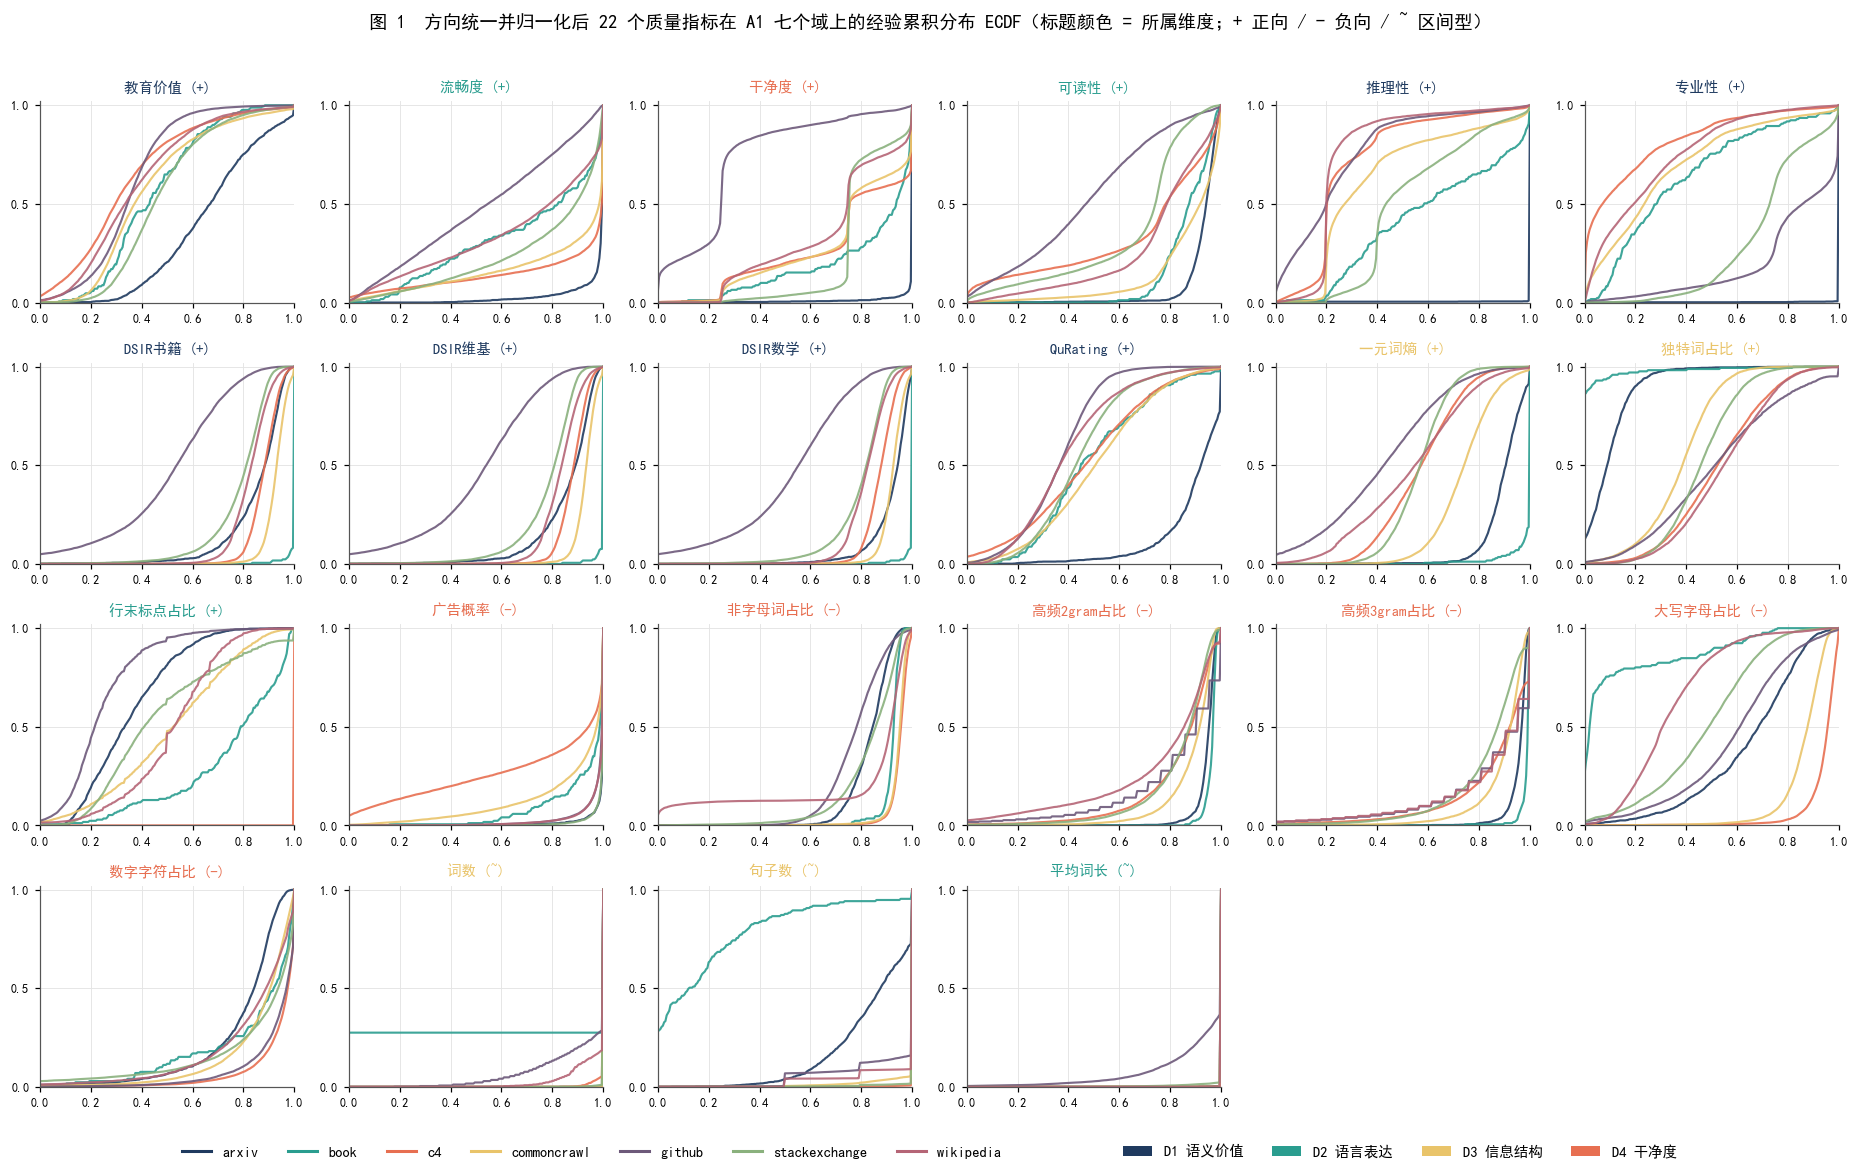

In [64]:
# ============ 1.2 方向统一 + 归一化（阈值一律取自 A1，三集共用） ============
BOUNDS = {j: (float(np.nanpercentile(R1[j], 1)), float(np.nanpercentile(R1[j], 99))) for j in IND_POS + IND_NEG}
INTERVAL = {'rps_doc_word_count': (50.0, 1e5, float(np.nanpercentile(R1['rps_doc_word_count'], 99.9)), True),
            'rps_doc_num_sentences': (3.0, float(np.nanpercentile(R1['rps_doc_num_sentences'], 95)), float(np.nanpercentile(R1['rps_doc_num_sentences'], 99.9)), True),
            'rps_doc_mean_word_length': (3.0, 10.0, float(np.nanpercentile(R1['rps_doc_mean_word_length'], 99.9)), False)}
MEDIAN = R1.median()

def interval_score(v, lo, hi, vmax, use_log):
    v = np.asarray(v, float)
    if use_log:
        t, tlo, thi, tmax = np.log10(1 + np.maximum(v, 0)), np.log10(1 + lo), np.log10(1 + hi), np.log10(1 + vmax)
    else:
        t, tlo, thi, tmax = v, lo, hi, vmax
    s = np.ones_like(t)
    below = t < tlo; s[below] = np.clip(t[below] / tlo, 0, 1)
    above = t > thi; s[above] = np.clip(1 - (t[above] - thi) / max(tmax - thi, 1e-9), 0, 1)
    return s

def normalize(R):
    X = pd.DataFrame(index=R.index)
    for j in INDICATORS:
        v = R[j].fillna(MEDIAN[j]).astype(float)
        if j in INTERVAL:
            lo, hi, vmax, lg = INTERVAL[j]; X[j] = interval_score(v, lo, hi, vmax, lg)
        else:
            lo, hi = BOUNDS[j]; x = ((v.clip(lo, hi) - lo) / (hi - lo)).values
            X[j] = 1 - x if j in IND_NEG else x
    return X

X1, X2, X3 = normalize(R1), normalize(R2), normalize(R3)
print('归一化后取值范围检查: A1 [%.3f, %.3f], A2 [%.3f, %.3f], A3 [%.3f, %.3f]' % (X1.values.min(), X1.values.max(), X2.values.min(), X2.values.max(), X3.values.min(), X3.values.max()))
print('区间型参数:', {k: (round(v[0], 1), round(v[1], 1)) for k, v in INTERVAL.items()})

# ---- 图 1：22 个归一化指标在 7 个域上的经验累积分布（A1） ----
DOMAINS = sorted(A1['domain'].unique())
DOM_PALETTE = ['#1F3A5F', '#2A9D8F', '#E76F51', '#E9C46A', '#6D597A', '#8AB17D', '#B56576']
DOM_COLORS = dict(zip(DOMAINS, DOM_PALETTE[:len(DOMAINS)]))
# 用 ECDF 而非核密度：归一化后很多指标在 0 或 1 处有点质量（截尾 / 区间型），ECDF 能如实显示这些跳跃且不受带宽影响
fig, axes = plt.subplots(4, 6, figsize=(17, 10.5))
grid = np.linspace(0, 1, 201)
for ax, j in zip(axes.ravel(), INDICATORS):
    for d in DOMAINS:
        v = np.sort(X1.loc[A1['domain'] == d, j].values)
        F = np.searchsorted(v, grid, side='right') / len(v)
        ax.plot(grid, F, color=DOM_COLORS[d], lw=1.4, alpha=0.9)
    ax.set_title('%s (%s)' % (SHORT[j], DIRECTION[j]), fontsize=9.5, color=DIM_COLORS[DIM_OF[j]])
    ax.set_xlim(0, 1); ax.set_ylim(0, 1.02); ax.set_yticks([0, 0.5, 1]); ax.tick_params(labelsize=8)
for ax in axes.ravel()[len(INDICATORS):]:
    ax.axis('off')
handles = [Line2D([0], [0], color=DOM_COLORS[d], lw=2, label=d) for d in DOMAINS]
handles += [Patch(facecolor='none', edgecolor='none', label='   ')] + [Patch(facecolor=DIM_COLORS[d], label=d) for d in DIMS]
fig.legend(handles=handles, loc='lower center', ncol=12, frameon=False, fontsize=9.5, bbox_to_anchor=(0.5, -0.01))
fig.suptitle('图 1  方向统一并归一化后 22 个质量指标在 A1 七个域上的经验累积分布 ECDF（标题颜色 = 所属维度；+ 正向 / - 负向 / ~ 区间型）', fontsize=12, y=0.995)
plt.tight_layout(rect=(0, 0.03, 1, 0.98))
savefig('fig01_indicator_distributions.png'); plt.show()

### 1.3 熵权–CRITIC 组合赋权与线性评分 $Q^{lin}$

22 个指标不能等权相加：有的指标信息量大（在样本间差异明显），有的与其他指标高度重复（如三个 DSIR 相似度的 Spearman 相关 ≈ 0.99）。本文采用两种 **客观赋权法** 并取几何组合，再按四个维度分组给出维度分。

**熵权法**：信息熵越小、指标越"有区分度"，权重越大。记 $n$ 为样本数，$x_{ij}\in[0,1]$ 为归一化指标，

$$p_{ij}=\frac{x_{ij}}{\sum_{i=1}^{n}x_{ij}},\qquad e_j=-\frac{1}{\ln n}\sum_{i=1}^{n}p_{ij}\ln p_{ij},\qquad w^{E}_j=\frac{1-e_j}{\sum_{k=1}^{22}(1-e_k)} .$$

**CRITIC 法**（Diakoulaki et al., 1995）：同时考虑指标的 **对比强度**（标准差 $\sigma_j$）与 **冲突性**（与其他指标相关系数 $r_{jk}$ 越低越独立）：

$$C_j=\sigma_j\sum_{k=1}^{22}\big(1-r_{jk}\big),\qquad w^{C}_j=\frac{C_j}{\sum_k C_k}.$$

CRITIC 的"冲突性"项天然会压低高度冗余指标（三个 DSIR）的权重，这正是后文冲突分析所需要的性质。

**组合权重**取二者的归一化几何平均，使一个指标必须同时"有区分度"且"不冗余"才能获得高权重：

$$w_j=\frac{\sqrt{w^E_j\,w^C_j}}{\sum_k\sqrt{w^E_k\,w^C_k}} .$$

**线性综合分与维度分**：样本 $i$ 的线性综合质量分为
$$Q^{lin}_i=\sum_{j=1}^{22} w_j\,x_{ij}\in[0,1],$$
把指标按 4 个维度 $d\in\{$语义价值, 语言表达, 信息结构, 干净度$\}$ 分组，维度权重 $W_d=\sum_{j\in d}w_j$，维度分 $S_{id}=\sum_{j\in d}w_j x_{ij}/W_d$，于是 $Q^{lin}_i=\sum_d W_d S_{id}$——线性综合分是维度分的加权算术平均，这一点是第 2 部分"冲突消解"的出发点。

权重只在 **A1 抽样集** 上估计（它覆盖 7 个域、是唯一的多域样本），A2/A3 直接套用同一组权重，保证域级 $Q$ 的可比性。

**评分衔接**：$Q^{lin}$ 是 22 个指标的线性综合分；第 2.3 节将四个维度的分数作加权几何聚合，得到用于领域质量评价的 $Q^{res}$。权重只由 A1 估计，随后固定应用于 A2/A3。

组合权重（按维度分组，从大到小）:


,维度,方向,熵权,CRITIC,组合权重
专业性 (modernbert_professionalism),D1 语义价值,+,0.1791,0.0952,0.1371
推理性 (modernbert_reasoning),D1 语义价值,+,0.1207,0.0512,0.0826
教育价值 (fineweb_edu),D1 语义价值,+,0.0674,0.0418,0.0558
QuRating (qurater),D1 语义价值,+,0.0602,0.0393,0.0511
DSIR书籍 (dsir_books),D1 语义价值,+,0.0200,0.0332,0.0270
DSIR维基 (dsir_wiki),D1 语义价值,+,0.0199,0.0333,0.0270
DSIR数学 (dsir_math),D1 语义价值,+,0.0190,0.0321,0.0259
行末标点占比 (rps_lines_ending_with_terminal_punctution_mark),D2 语言表达,+,0.0887,0.0667,0.0808
流畅度 (fluency_en),D2 语言表达,+,0.0599,0.0619,0.0639
可读性 (modernbert_readability),D2 语言表达,+,0.0566,0.0530,0.0575


维度权重 W_d:
维度
D1 语义价值   0.4065
D2 语言表达   0.2084
D3 信息结构   0.1145
D4 干净度    0.2706


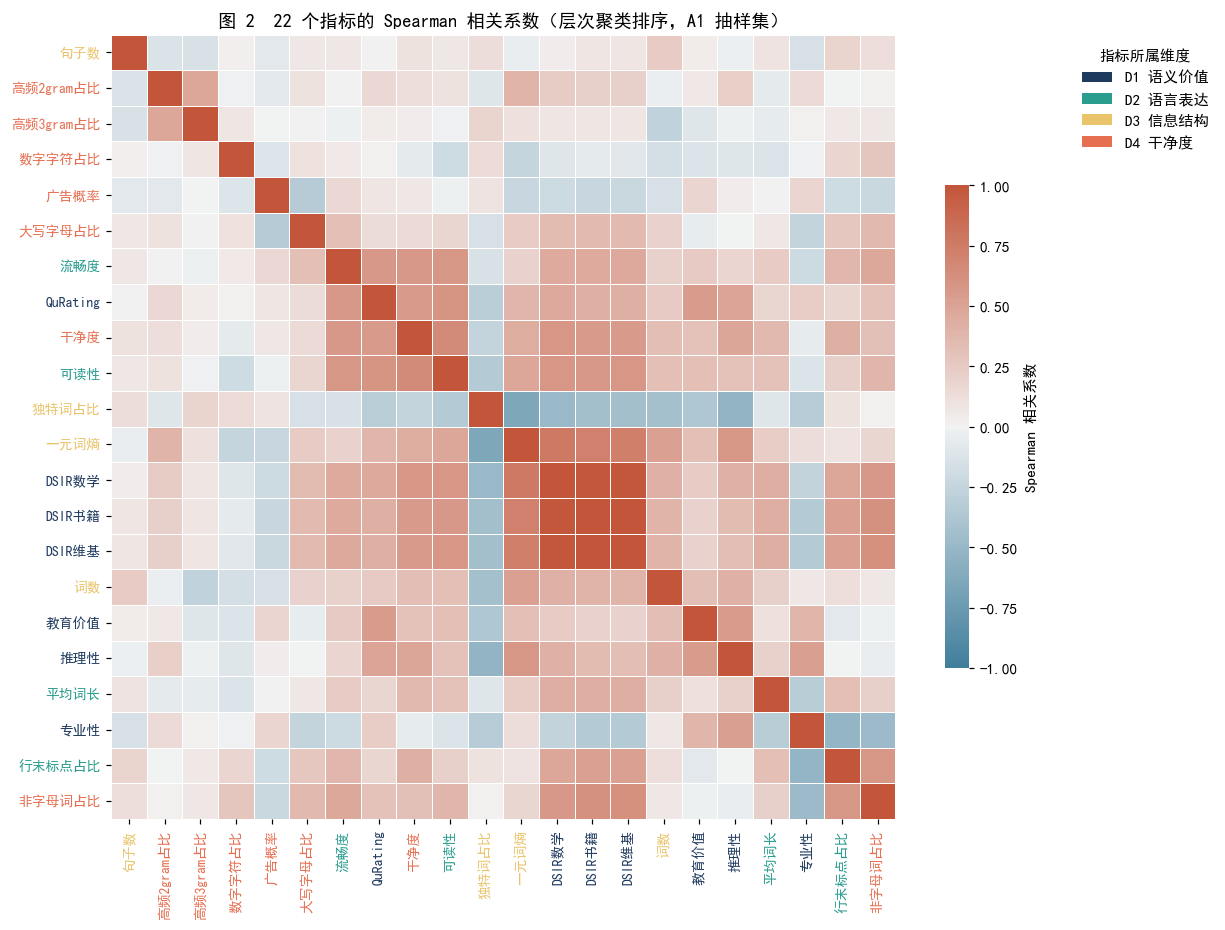

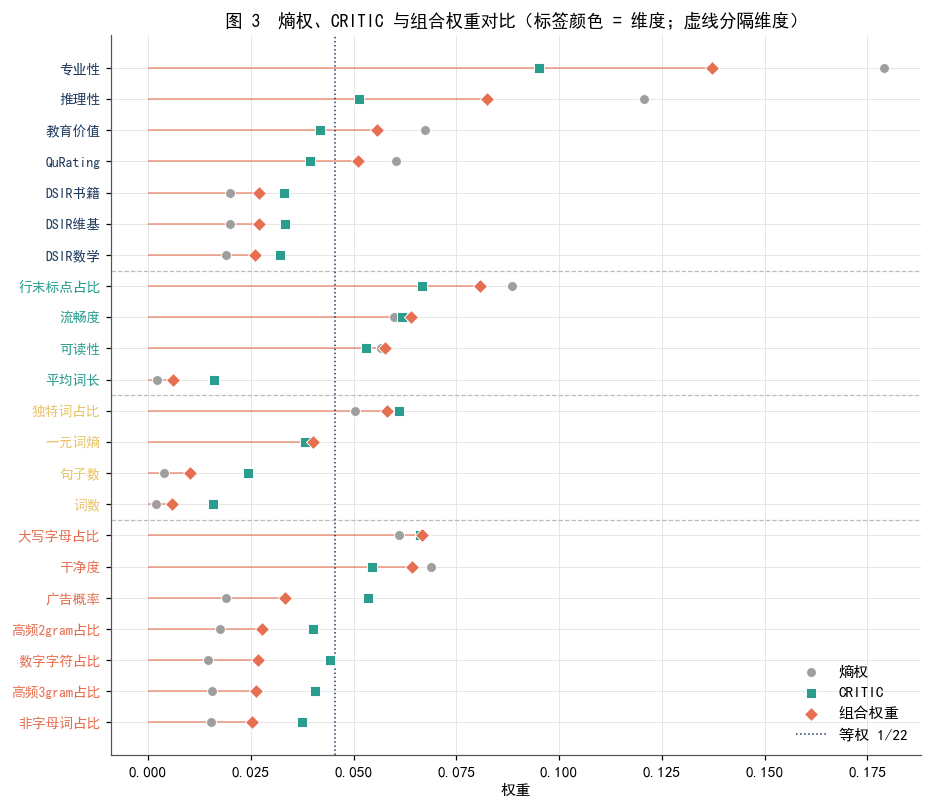

In [65]:
# ============ 1.3 熵权 + CRITIC 组合赋权（在 A1 上估计） ============
def entropy_weight(X):
    X = np.asarray(X, float) + 1e-12; n = X.shape[0]
    P = X / X.sum(axis=0)
    e = -(P * np.log(P)).sum(axis=0) / np.log(n)
    d = 1 - e
    return d / d.sum()

def critic_weight(X):
    X = np.asarray(X, float)
    sd = X.std(axis=0, ddof=1)
    Rm = np.corrcoef(X, rowvar=False)
    C = sd * (1 - Rm).sum(axis=1)
    return C / C.sum()

wE = entropy_weight(X1.values); wC = critic_weight(X1.values)
wG = np.sqrt(wE * wC); wG = wG / wG.sum()
W = pd.DataFrame({'维度': [DIM_OF[j] for j in INDICATORS], '方向': [DIRECTION[j] for j in INDICATORS],
                  '熵权': wE, 'CRITIC': wC, '组合权重': wG}, index=INDICATORS)
W_DIM = W.groupby('维度')['组合权重'].sum()
print('组合权重（按维度分组，从大到小）:')
display(W.sort_values(['维度', '组合权重'], ascending=[True, False]).rename(index=lambda j: SHORT[j] + ' (' + j + ')'))
print('维度权重 W_d:'); print(W_DIM.round(4).to_string())
W.to_csv(TAB / 'indicator_weights.csv', encoding='utf-8-sig')

# ---- 图 2：指标 Spearman 相关的层次聚类热力图（支撑维度划分与冲突成因） ----
RHO = X1.rank().corr()                      # 秩相关 = Spearman
dist = squareform(1 - RHO.abs().values, checks=False)
order = hierarchy.leaves_list(hierarchy.linkage(dist, method='average'))
lab = [SHORT[j] for j in RHO.columns]
fig, ax = plt.subplots(figsize=(11.5, 9.5))
sns.heatmap(RHO.iloc[order, order], cmap=CMAP_DIV, vmin=-1, vmax=1, square=True, ax=ax,
            xticklabels=[lab[i] for i in order], yticklabels=[lab[i] for i in order],
            cbar_kws={'shrink': 0.6, 'label': 'Spearman 相关系数'}, linewidths=0.4, linecolor='white')
ax.grid(False)
for tl in ax.get_xticklabels() + ax.get_yticklabels():
    j = INDICATORS[lab.index(tl.get_text())]
    tl.set_color(DIM_COLORS[DIM_OF[j]]); tl.set_fontsize(9)
plt.setp(ax.get_xticklabels(), rotation=90)
ax.legend(handles=[Patch(facecolor=DIM_COLORS[d], label=d) for d in DIMS], loc='upper left', bbox_to_anchor=(1.22, 1.0), frameon=False, title='指标所属维度')
ax.set_title('图 2  22 个指标的 Spearman 相关系数（层次聚类排序，A1 抽样集）', fontsize=12)
savefig('fig02_corr_cluster_heatmap.png'); plt.show()

# ---- 图 3：三种权重的对比（棒棒糖图，按维度分组） ----
Wp = W.copy(); Wp['name'] = [SHORT[j] for j in Wp.index]
Wp = Wp.sort_values(['维度', '组合权重'], ascending=[False, True])
fig, ax = plt.subplots(figsize=(9.5, 8.5))
y = np.arange(len(Wp))
for k, (col, c, m) in enumerate([('熵权', C_GREY, 'o'), ('CRITIC', C_TEAL, 's'), ('组合权重', C_CORAL, 'D')]):
    ax.scatter(Wp[col], y, color=c, marker=m, s=42, label=col, zorder=3, edgecolor='white', linewidth=0.6)
ax.hlines(y, 0, Wp['组合权重'], color=C_CORAL, lw=1.2, alpha=0.6, zorder=2)
ax.set_yticks(y); ax.set_yticklabels(Wp['name'], fontsize=9)
for tl, d in zip(ax.get_yticklabels(), Wp['维度']):
    tl.set_color(DIM_COLORS[d])
prev = None
for i, d in enumerate(Wp['维度']):
    if prev is not None and d != prev: ax.axhline(i - 0.5, color='#BBBBBB', lw=0.8, ls='--')
    prev = d
ax.axvline(1 / 22, color=C_NAVY, lw=1, ls=':', label='等权 1/22')
ax.set_xlabel('权重'); ax.set_title('图 3  熵权、CRITIC 与组合权重对比（标签颜色 = 维度；虚线分隔维度）', fontsize=11.5)
ax.legend(loc='lower right', frameon=False)
savefig('fig03_weights_lollipop.png'); plt.show()

### 1.4 由样本向语料、领域聚合

* **样本级** $Q_i$：上式直接给出。
* **语料级**：一个域的语料是其全部文档的 token 总和，训练时每篇文档对损失的贡献与其 token 数成比例，因此语料级质量应是 **按词数加权的样本均值**（记 $n_i$ 为文档 $i$ 的词数）：
$$Q^{corpus}_D=\frac{\sum_{i\in D} n_i Q_i}{\sum_{i\in D} n_i}.$$
* **领域级**：为了和"文档层面的质量"对照，同时报告 **简单均值** $Q^{doc}_D=\frac{1}{|D|}\sum_{i\in D}Q_i$ 及其 Bootstrap 95% 置信区间（$B=300$ 次有放回重抽样，取 2.5%、97.5% 分位数）。两者的差异反映"长文档是否更优质"。

题目要求"全量质量信号"：arxiv 与 github 两个域，A1 中只是抽样（1,419 与 10,000 条），A2/A3 给出全量（17,523 与 203,752 条）。下面分别给出 **A1 抽样估计** 与 **扩展集全量估计**。A1 的 arxiv/github 记录包含在 A2/A3 中；分布对照采用与 A1 ID 不重叠的扩展集余集，KS 统计量和 Wasserstein 距离用于描述偏差。全量域级聚合按 ID 去重。

域级线性综合分 Q_lin（A1 抽样集 vs 扩展集）:


,数据集,域,n,Q_lin_doc均值,CI95低,CI95高,Q_lin_语料(词数加权),Q_lin_中位数
0,A1 抽样集,arxiv,1419,0.8116,0.8102,0.8131,0.8101,0.8158
1,A1 抽样集,book,171,0.6271,0.6170,0.6399,0.6398,0.6243
2,A1 抽样集,c4,10000,0.6410,0.6392,0.6428,0.6840,0.6441
3,A1 抽样集,commoncrawl,9640,0.6440,0.6420,0.6457,0.6699,0.6417
4,A1 抽样集,github,10000,0.5355,0.5340,0.5369,0.5804,0.5420
5,A1 抽样集,stackexchange,10000,0.6540,0.6526,0.6553,0.6770,0.6532
6,A1 抽样集,wikipedia,10000,0.5486,0.5471,0.5506,0.6264,0.5431
7,A2 扩展集,arxiv,17523,0.8110,0.8105,0.8115,0.8096,0.8154
8,A3 扩展集,github,203752,0.5345,0.5342,0.5349,0.5782,0.5396



抽样集 vs 扩展集的样本级 Q_lin 分布差异:


,域,A1样本数,扩展集非重叠样本数,KS统计量,KS_p,Wasserstein距离,指标均值剖面Spearman
0,arxiv,1419,16104,0.0193,0.7163,0.0009,0.9977
1,github,10000,193752,0.0144,0.0391,0.0013,0.9989


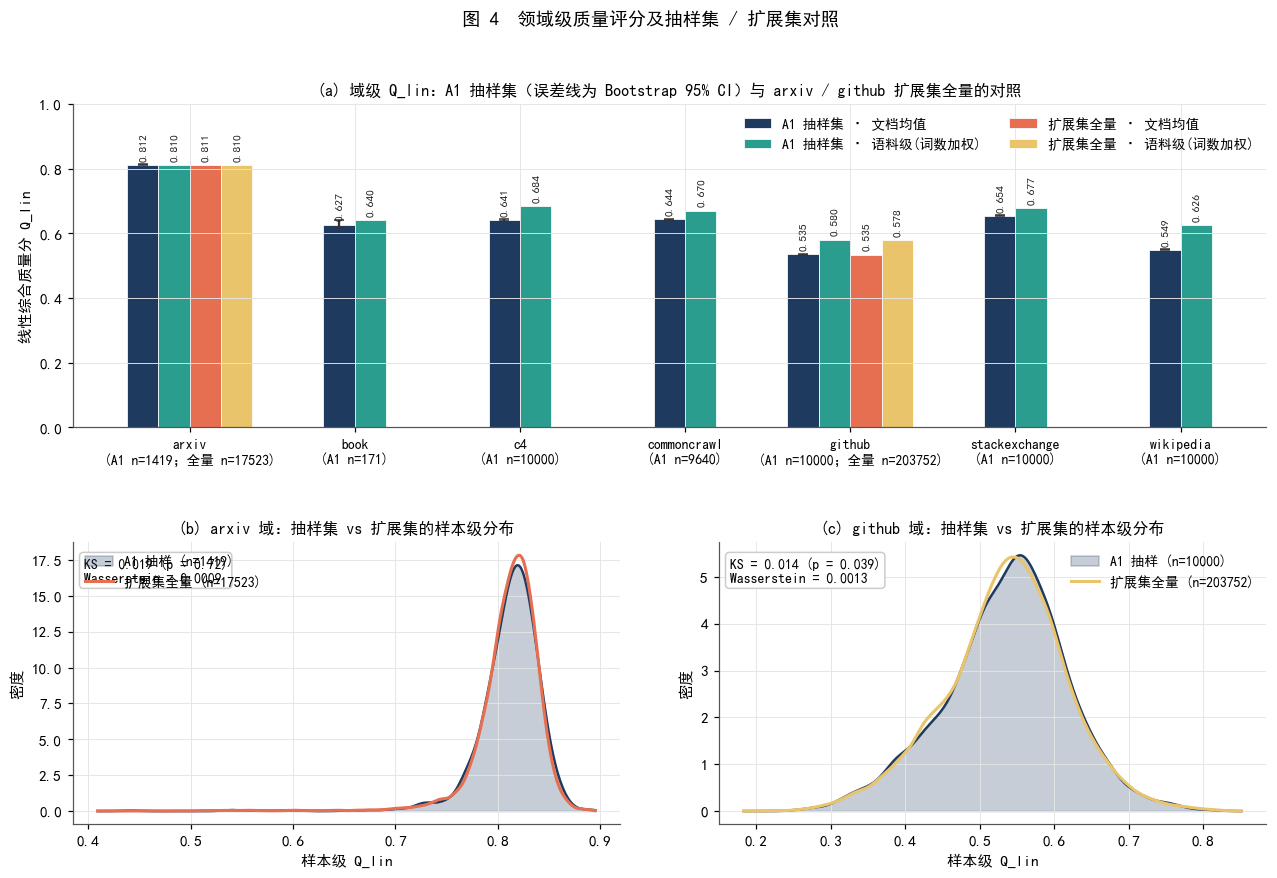

In [66]:
# ============ 1.4 线性综合分与域级聚合 ============
def dim_scores(X):
    S = pd.DataFrame(index=X.index)
    for d, js in DIMS.items():
        S[d] = (X[js].values * W.loc[js, '组合权重'].values).sum(axis=1) / W_DIM[d]
    return S

S1, S2, S3 = dim_scores(X1), dim_scores(X2), dim_scores(X3)
for A, X in ((A1, X1), (A2, X2), (A3, X3)):
    A['Q_lin'] = (X.values * wG).sum(axis=1)

def boot_ci(v, w=None, B=300, seed=0):
    v = np.asarray(v, float); n = len(v); rng = np.random.default_rng(seed)
    w = None if w is None else np.asarray(w, float)
    est = np.empty(B)
    for b in range(B):
        idx = rng.integers(0, n, n)
        est[b] = np.average(v[idx]) if w is None else np.average(v[idx], weights=w[idx])
    return np.percentile(est, [2.5, 97.5])

def domain_table(frames, col):
    rows = []
    for name, A in frames:
        for d, g in A.groupby('domain'):
            lo, hi = boot_ci(g[col].values)
            rows.append({'数据集': name, '域': d, 'n': len(g), col + '_doc均值': g[col].mean(), 'CI95低': lo, 'CI95高': hi,
                         col + '_语料(词数加权)': np.average(g[col], weights=g['rps_doc_word_count'].clip(lower=1)),
                         col + '_中位数': g[col].median()})
    return pd.DataFrame(rows)

DT_lin = domain_table([('A1 抽样集', A1), ('A2 扩展集', A2), ('A3 扩展集', A3)], 'Q_lin')
print('域级线性综合分 Q_lin（A1 抽样集 vs 扩展集）:')
display(DT_lin)

# 抽样集 vs 扩展集的分布差异
cmp_rows = []
for d, ext, Xe in (('arxiv', A2, X2), ('github', A3, X3)):
    a_ids = set(A1.loc[A1['domain'] == d, 'id'])
    a = A1.loc[A1['domain'] == d, 'Q_lin'].values
    b = ext.loc[~ext['id'].isin(a_ids), 'Q_lin'].values
    ks = stats.ks_2samp(a, b)
    prof = stats.spearmanr(X1.loc[A1['domain'] == d].mean(), Xe.mean())[0]
    cmp_rows.append({'域': d, 'A1样本数': len(a), '扩展集非重叠样本数': len(b), 'KS统计量': ks.statistic, 'KS_p': ks.pvalue,
                     'Wasserstein距离': stats.wasserstein_distance(a, b), '指标均值剖面Spearman': prof})
print('\n抽样集 vs 扩展集的样本级 Q_lin 分布差异:')
display(pd.DataFrame(cmp_rows))

# ---- 图 4：域级 Q 对照 + 抽样/扩展分布叠加 ----
fig = plt.figure(figsize=(14, 8.5))
gs = gridspec.GridSpec(2, 2, height_ratios=[1.15, 1], hspace=0.38, wspace=0.18)
ax = fig.add_subplot(gs[0, :])
a1 = DT_lin[DT_lin['数据集'] == 'A1 抽样集'].set_index('域').loc[DOMAINS]
ext_tab = {'arxiv': DT_lin[DT_lin['数据集'] == 'A2 扩展集'].iloc[0], 'github': DT_lin[DT_lin['数据集'] == 'A3 扩展集'].iloc[0]}
wbar = 0.19; xpos = np.arange(len(DOMAINS)) * 1.0
series = [('A1 抽样集 · 文档均值', C_NAVY, 'Q_lin_doc均值', False), ('A1 抽样集 · 语料级(词数加权)', C_TEAL, 'Q_lin_语料(词数加权)', False),
          ('扩展集全量 · 文档均值', C_CORAL, 'Q_lin_doc均值', True), ('扩展集全量 · 语料级(词数加权)', C_GOLD, 'Q_lin_语料(词数加权)', True)]
for i, d in enumerate(DOMAINS):
    ser = series if d in ext_tab else series[:2]
    offs = (np.arange(len(ser)) - (len(ser) - 1) / 2) * wbar
    for (lab_, c, col, is_ext), off in zip(ser, offs):
        src = ext_tab[d] if is_ext else a1.loc[d]
        err = None if (is_ext or col != 'Q_lin_doc均值') else [[src['Q_lin_doc均值'] - src['CI95低']], [src['CI95高'] - src['Q_lin_doc均值']]]
        ax.bar(xpos[i] + off, src[col], wbar, color=c, label=lab_ if i == 0 or (is_ext and d == 'arxiv') else None, yerr=err, capsize=3, ecolor='#333333', edgecolor='white', linewidth=0.5)
        ax.text(xpos[i] + off, src[col] + 0.012, '%.3f' % src[col], ha='center', va='bottom', fontsize=7.5, rotation=90, color='#222222')
ax.set_xticks(xpos); ax.set_xticklabels(['%s\n(A1 n=%d%s)' % (d, a1.loc[d, 'n'], ('；全量 n=%d' % ext_tab[d]['n']) if d in ext_tab else '') for d in DOMAINS], fontsize=9)
ax.set_ylim(0, 1.0); ax.set_ylabel('线性综合质量分 Q_lin')
ax.set_title('(a) 域级 Q_lin：A1 抽样集（误差线为 Bootstrap 95% CI）与 arxiv / github 扩展集全量的对照', fontsize=10.5)
ax.legend(loc='upper right', ncol=2, frameon=False, fontsize=9)
for k, (d, ext, c) in enumerate((('arxiv', A2, C_CORAL), ('github', A3, C_GOLD))):
    ax = fig.add_subplot(gs[1, k])
    a = A1.loc[A1['domain'] == d, 'Q_lin'].values; b = ext['Q_lin'].values
    xs = np.linspace(min(a.min(), b.min()), max(a.max(), b.max()), 300)
    ax.fill_between(xs, stats.gaussian_kde(a)(xs), color=C_NAVY, alpha=0.25, label='A1 抽样 (n=%d)' % len(a))
    ax.plot(xs, stats.gaussian_kde(a)(xs), color=C_NAVY, lw=1.6)
    ax.plot(xs, stats.gaussian_kde(b if len(b) <= 30000 else RNG.choice(b, 30000, replace=False))(xs), color=c, lw=2.0, label='扩展集全量 (n=%d)' % len(b))
    r = cmp_rows[k]
    ax.text(0.02, 0.95, 'KS = %.3f (p = %.2g)\nWasserstein = %.4f' % (r['KS统计量'], r['KS_p'], r['Wasserstein距离']), transform=ax.transAxes, va='top', fontsize=9, bbox=dict(boxstyle='round', fc='white', ec='#CCCCCC'))
    ax.set_xlabel('样本级 Q_lin'); ax.set_ylabel('密度'); ax.set_title('(%s) %s 域：抽样集 vs 扩展集的样本级分布' % ('bc'[k], d), fontsize=10.5)
    ax.legend(frameon=False, fontsize=9)
fig.suptitle('图 4  领域级质量评分及抽样集 / 扩展集对照', fontsize=12, y=0.98)
savefig('fig04_domain_Q_compare.png'); plt.show()

## 2. 质量冲突消解

### 2.1 冲突的定义

"冲突"指 **不同指标对同一文本给出显著不一致的评价**。方向统一后，所有指标都是"越高越好"，因此不一致可以精确定义为"一个指标判为高、另一个判为低"。

**指标对层面**。以 A1 上各指标的 25%、75% 分位数 $q_j^{25},q_j^{75}$ 为界，定义高 / 低指示变量
$$H_{ij}=\mathbb 1\big[x_{ij}\ge q_j^{75}\big],\qquad L_{ij}=\mathbb 1\big[x_{ij}\le q_j^{25}\big].$$
指标对 $(j,k)$ 的 **冲突率** 为"一高一低"的样本占比
$$c_{jk}=\frac1n\sum_{i=1}^{n}\big(H_{ij}L_{ik}+L_{ij}H_{ik}\big).$$
若两指标相互独立，冲突率的期望为 $e_{jk}=\pi^H_j\pi^L_k+\pi^L_j\pi^H_k$（$\pi^H_j,\pi^L_j$ 为高、低的边际比例，理想情形 $e_{jk}=2\times0.25\times0.25=0.125$）。定义 **冲突倍率** $\rho_{jk}=c_{jk}/e_{jk}$：$\rho_{jk}\approx0$ 表示两指标高度一致，$\rho_{jk}\approx1$ 表示无关，$\rho_{jk}>1$ 表示 **系统性冲突**（负相关）。显著性用二项检验的正态近似
$$z_{jk}=\frac{c_{jk}-e_{jk}}{\sqrt{e_{jk}(1-e_{jk})/n}},$$
"显著冲突对"定义为 $\rho_{jk}>1$ 且 $z_{jk}>3$。

**样本层面**。指标很多、两两比较过于零碎，因此把冲突提升到 4 个维度：样本 $i$ 的 **冲突强度** 定义为维度分的极差
$$CI_i=\max_d S_{id}-\min_d S_{id}\in[0,1],$$
$CI_i\ge\tau$（取 $\tau=0.5$，即某两个维度的评价相差超过量表的一半）的样本记为 **冲突样本**。后文对 $\tau$ 做敏感性分析。

指标对总数 231，其中显著冲突对 63 个（rho>1 且 z>3），一致对（rho<0.5）57 个

冲突倍率最高的 15 个指标对:


,指标j,指标k,冲突率c,独立期望e,冲突倍率rho,z,Spearman,跨维度,跨评分器类型
0,一元词熵,独特词占比,0.3014,0.1263,2.3873,119.3709,-0.6480,False,False
1,推理性,独特词占比,0.2677,0.1263,2.1193,96.3209,-0.5293,True,True
2,专业性,行末标点占比,0.2641,0.1266,2.0862,93.5953,-0.5192,True,True
3,DSIR数学,独特词占比,0.2435,0.1263,1.9289,79.9234,-0.4993,True,True
4,DSIR书籍,独特词占比,0.2254,0.1263,1.7854,67.5794,-0.4448,True,True
5,专业性,非字母词占比,0.2226,0.1250,1.7808,66.8035,-0.4835,True,True
6,DSIR维基,独特词占比,0.2242,0.1263,1.7755,66.7281,-0.4428,True,True
7,教育价值,独特词占比,0.2193,0.1263,1.7366,63.3760,-0.3750,True,True
8,专业性,独特词占比,0.2144,0.1263,1.6978,60.0373,-0.3243,True,True
9,广告概率,大写字母占比,0.2065,0.1251,1.6510,55.7094,-0.3293,False,True


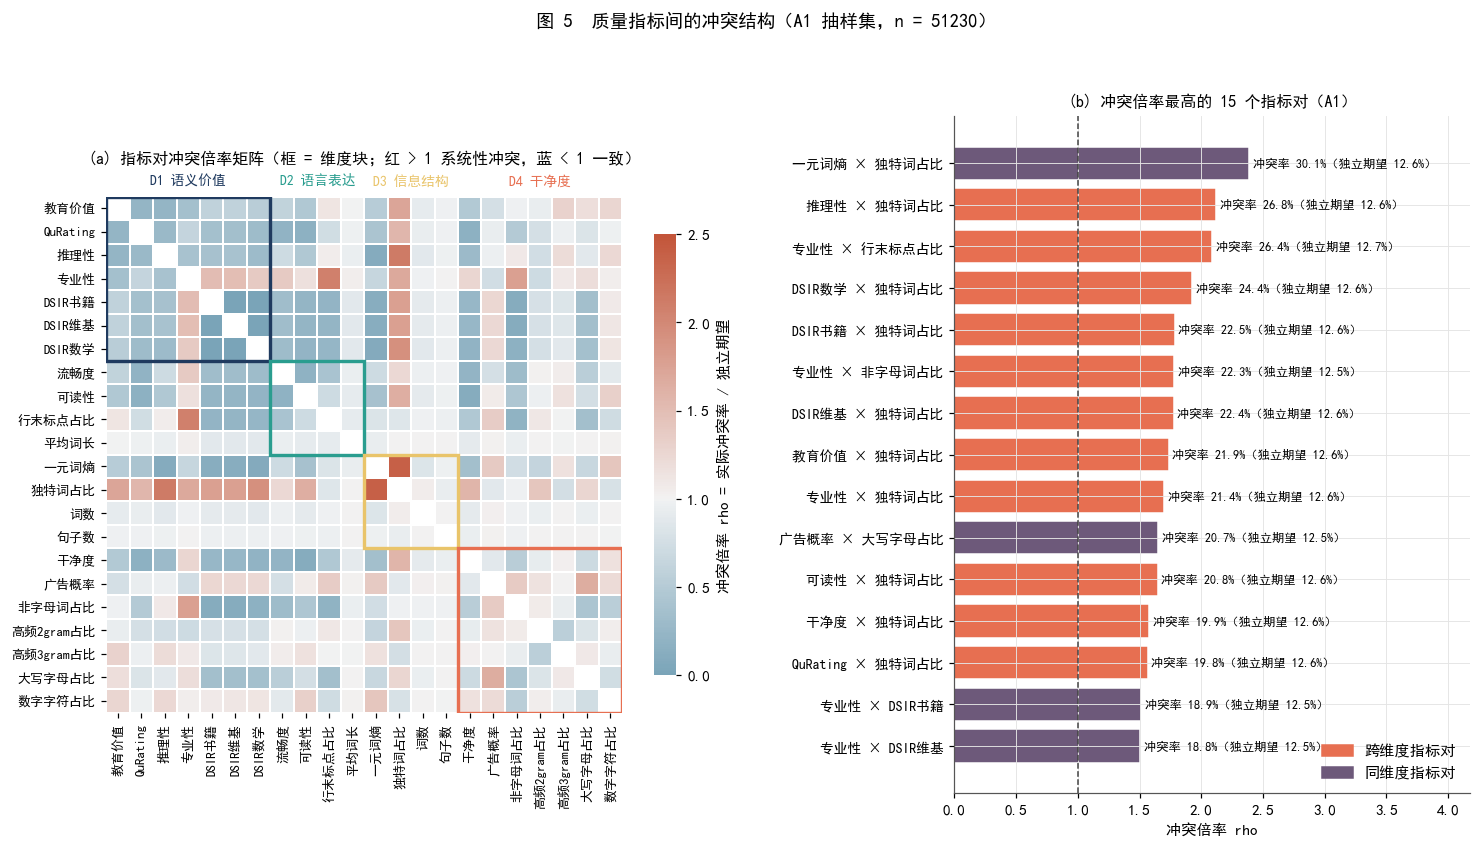

In [67]:
# ============ 2.1 冲突矩阵（阈值一律取自 A1） ============
Q_LO, Q_HI = 0.25, 0.75
THR_LO, THR_HI = X1.quantile(Q_LO), X1.quantile(Q_HI)

def conflict_matrix(X, thr_lo=None, thr_hi=None):
    thr_lo = THR_LO if thr_lo is None else thr_lo; thr_hi = THR_HI if thr_hi is None else thr_hi
    H = (X.values >= thr_hi.values).astype(float); L = (X.values <= thr_lo.values).astype(float); n = len(X)
    cnt = H.T @ L; C = (cnt + cnt.T) / n
    pH, pL = H.mean(axis=0), L.mean(axis=0)
    E = np.outer(pH, pL) + np.outer(pL, pH)
    with np.errstate(divide='ignore', invalid='ignore'):
        ratio = np.where(E > 0, C / E, np.nan)
        z = (C - E) / np.sqrt(np.maximum(E * (1 - E), 1e-12) / n)
    for M in (C, E, ratio, z):
        np.fill_diagonal(M, np.nan)
    cols = list(X.columns)
    return (pd.DataFrame(C, cols, cols), pd.DataFrame(E, cols, cols), pd.DataFrame(ratio, cols, cols), pd.DataFrame(z, cols, cols))

C1, E1, RATIO1, Z1 = conflict_matrix(X1)
pairs = []
for a, b in itertools.combinations(INDICATORS, 2):
    pairs.append({'指标j': SHORT[a], '指标k': SHORT[b], 'j': a, 'k': b, '冲突率c': C1.loc[a, b], '独立期望e': E1.loc[a, b],
                  '冲突倍率rho': RATIO1.loc[a, b], 'z': Z1.loc[a, b], 'Spearman': RHO.loc[a, b],
                  '跨维度': DIM_OF[a] != DIM_OF[b], '跨评分器类型': (a in MODEL_BASED) != (b in MODEL_BASED)})
PAIRS = pd.DataFrame(pairs).sort_values('冲突倍率rho', ascending=False).reset_index(drop=True)
PAIRS['显著冲突'] = (PAIRS['冲突倍率rho'] > 1) & (PAIRS['z'] > 3)
print('指标对总数 %d，其中显著冲突对 %d 个（rho>1 且 z>3），一致对（rho<0.5）%d 个' % (len(PAIRS), PAIRS['显著冲突'].sum(), (PAIRS['冲突倍率rho'] < 0.5).sum()))
print('\n冲突倍率最高的 15 个指标对:')
display(PAIRS.head(15)[['指标j', '指标k', '冲突率c', '独立期望e', '冲突倍率rho', 'z', 'Spearman', '跨维度', '跨评分器类型']])
PAIRS.to_csv(TAB / 'conflict_pairs_A1.csv', index=False, encoding='utf-8-sig')

# ---- 图 5：冲突倍率矩阵 + Top 冲突对 ----
ordD = [j for d in DIMS for j in DIMS[d]]
fig = plt.figure(figsize=(16, 8))
gs = gridspec.GridSpec(1, 2, width_ratios=[1.25, 1], wspace=0.35)
ax = fig.add_subplot(gs[0])
M = RATIO1.loc[ordD, ordD]
sns.heatmap(M, cmap=CMAP_DIV, center=1, vmin=0, vmax=2.5, square=True, ax=ax, xticklabels=[SHORT[j] for j in ordD], yticklabels=[SHORT[j] for j in ordD],
            cbar_kws={'shrink': 0.65, 'label': '冲突倍率 rho = 实际冲突率 / 独立期望'}, linewidths=0.3, linecolor='white')
ax.grid(False)
pos = 0
for d in DIMS:
    k = len(DIMS[d]); ax.add_patch(Rectangle((pos, pos), k, k, fill=False, edgecolor=DIM_COLORS[d], lw=2.2)); ax.text(pos + k / 2, -0.4, d, ha='center', va='bottom', fontsize=9, color=DIM_COLORS[d], fontweight='bold'); pos += k
plt.setp(ax.get_xticklabels(), rotation=90, fontsize=8.5); plt.setp(ax.get_yticklabels(), fontsize=8.5)
ax.set_title('(a) 指标对冲突倍率矩阵（框 = 维度块；红 > 1 系统性冲突，蓝 < 1 一致）', fontsize=10.5, pad=22)
ax = fig.add_subplot(gs[1])
top = PAIRS.head(15).iloc[::-1]
cols = [C_CORAL if x else C_PLUM for x in top['跨维度']]
ax.barh(np.arange(len(top)), top['冲突倍率rho'], color=cols, edgecolor='white')
ax.axvline(1, color='#444444', ls='--', lw=1)
for i, (c, e, r) in enumerate(zip(top['冲突率c'], top['独立期望e'], top['冲突倍率rho'])):
    ax.text(r + 0.03, i, '冲突率 %.1f%%（独立期望 %.1f%%）' % (100 * c, 100 * e), va='center', fontsize=8)
ax.set_yticks(np.arange(len(top))); ax.set_yticklabels([a + ' × ' + b for a, b in zip(top['指标j'], top['指标k'])], fontsize=9)
ax.set_xlim(0, top['冲突倍率rho'].max() * 1.75); ax.set_xlabel('冲突倍率 rho')
ax.legend(handles=[Patch(color=C_CORAL, label='跨维度指标对'), Patch(color=C_PLUM, label='同维度指标对')], frameon=False, loc='lower right')
ax.set_title('(b) 冲突倍率最高的 15 个指标对（A1）', fontsize=10.5)
fig.suptitle('图 5  质量指标间的冲突结构（A1 抽样集，n = %d）' % len(X1), fontsize=12, y=1.0)
savefig('fig05_conflict_matrix.png'); plt.show()

### 2.2 冲突成因分析

冲突不是噪声，而是有结构的。本文从四个角度检验其来源，每个角度对应一个可计算的统计量：

1. **指标语义异质（跨维度）**：不同维度衡量文本的不同侧面（"教育价值高"与"含广告"可以同时成立）。检验：跨维度指标对的平均冲突倍率是否显著高于同维度指标对。
2. **评分器类型差异（模型 vs 规则）**：11 个模型评分器（FineWeb-Edu、QuRating、ModernBERT 等）学习的是"人类眼中的质量"，11 个规则统计量（RedPajama `rps_*`）刻画的是表层形态。检验：跨类型指标对 vs 同类型指标对的冲突倍率。
3. **领域特性**：代码（github）流畅度低、大写与数字占比高但干净度高；论文（arxiv）专业性极高但独特词占比低。检验：各域冲突样本占比与平均冲突强度。
4. **长度效应**：规则型统计量在短文本上极不稳定（几个词就能把"独特词占比"推到 100%）。检验：冲突强度随词数十分位的变化及二者的 Spearman 相关。

A1 冲突样本（CI >= 0.50）占比: 19.77%，平均冲突强度 0.377

(1) 跨维度指标对 vs 同维度指标对的冲突倍率:
        mean  median  count
跨维度                        
False 0.7640  0.7750     54
True  0.8630  0.9500    177
    单侧 Mann-Whitney p(跨 > 同) = 4.87e-02

(2) 跨评分器类型 vs 同类型:
         mean  median  count
跨评分器类型                      
False  0.7460  0.8250    110
True   0.9260  0.9540    121
    单侧 Mann-Whitney p(跨 > 同) = 2.46e-03

(3) 各域的冲突样本占比与主要冲突模式:


,n,冲突样本占比,平均冲突强度,强度中位数,最常见冲突模式
domain,,,,,
c4,10000,0.6325,0.5374,0.5513,D2高/D1低
commoncrawl,9640,0.2383,0.4182,0.4154,D4高/D1低
book,171,0.2222,0.4270,0.4430,D2高/D3低
arxiv,1419,0.1184,0.4338,0.4358,D1高/D3低
github,10000,0.0692,0.3030,0.2900,D4高/D2低
wikipedia,10000,0.0428,0.3503,0.3532,D2高/D1低
stackexchange,10000,0.0179,0.2702,0.2604,D4高/D2低



(4) 冲突强度与 lg(词数) 的 Spearman 相关: 0.064


,词数中位数,平均冲突强度,冲突样本占比
wc_decile,,,
1,30.0000,0.3735,0.1757
2,67.0000,0.4044,0.2850
3,109.0000,0.3762,0.2461
4,157.0000,0.3556,0.2032
5,217.0000,0.3563,0.1942
6,293.0000,0.3638,0.2020
7,400.0000,0.3766,0.2079
8,564.0000,0.3811,0.1847
9,901.0000,0.3820,0.1485


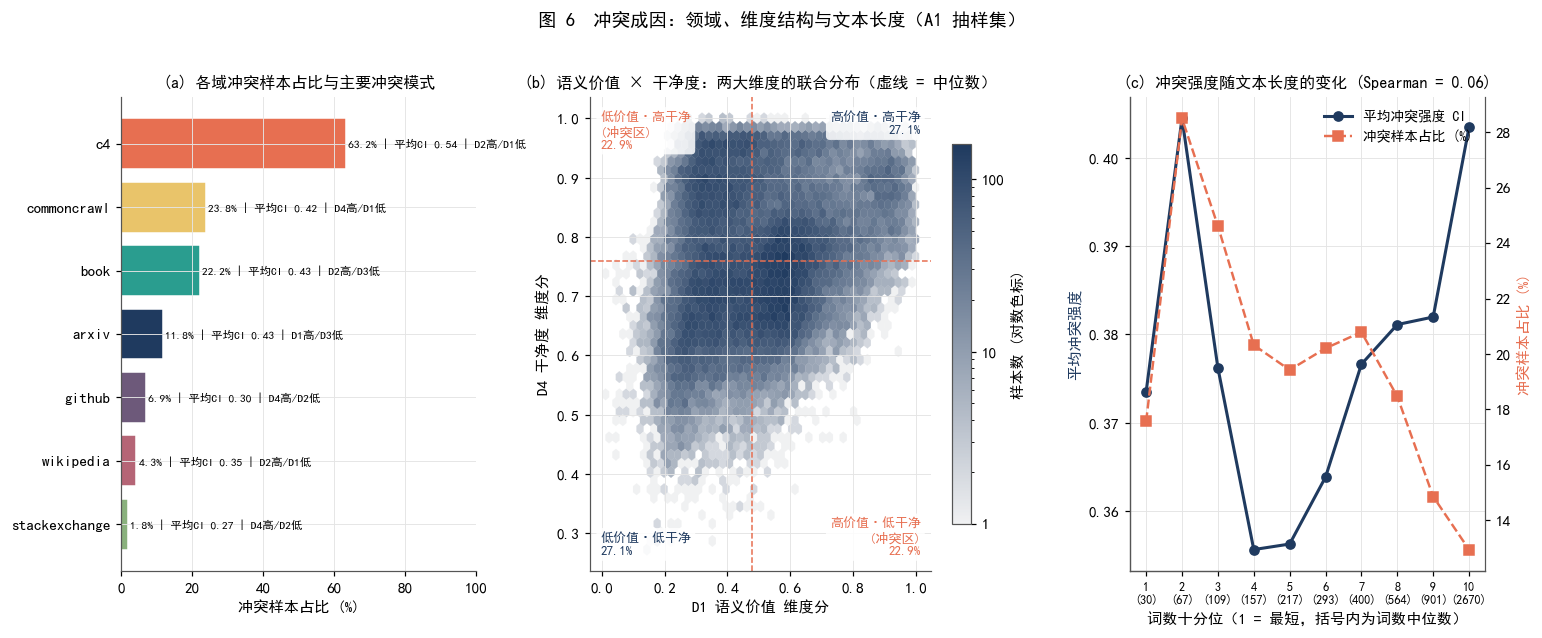

In [68]:
# ============ 2.2 冲突成因：四个角度的统计检验 ============
A1['CI'] = S1.max(axis=1) - S1.min(axis=1)
A1['CI_maxdim'] = S1.idxmax(axis=1); A1['CI_mindim'] = S1.idxmin(axis=1)
TAU = 0.5
A1['is_conflict'] = A1['CI'] >= TAU
print('A1 冲突样本（CI >= %.2f）占比: %.2f%%，平均冲突强度 %.3f' % (TAU, 100 * A1['is_conflict'].mean(), A1['CI'].mean()))

# (1) 跨维度 vs 同维度  (2) 跨评分器类型 vs 同类型  —— Mann-Whitney U 检验
def mwu(a, b):
    return stats.mannwhitneyu(a, b, alternative='greater').pvalue
g1 = PAIRS.groupby('跨维度')['冲突倍率rho'].agg(['mean', 'median', 'count']); g2 = PAIRS.groupby('跨评分器类型')['冲突倍率rho'].agg(['mean', 'median', 'count'])
print('\n(1) 跨维度指标对 vs 同维度指标对的冲突倍率:'); print(g1.round(3).to_string())
print('    单侧 Mann-Whitney p(跨 > 同) = %.2e' % mwu(PAIRS.loc[PAIRS['跨维度'], '冲突倍率rho'], PAIRS.loc[~PAIRS['跨维度'], '冲突倍率rho']))
print('\n(2) 跨评分器类型 vs 同类型:'); print(g2.round(3).to_string())
print('    单侧 Mann-Whitney p(跨 > 同) = %.2e' % mwu(PAIRS.loc[PAIRS['跨评分器类型'], '冲突倍率rho'], PAIRS.loc[~PAIRS['跨评分器类型'], '冲突倍率rho']))

# (3) 领域
dom_conf = A1.groupby('domain').agg(n=('CI', 'size'), 冲突样本占比=('is_conflict', 'mean'), 平均冲突强度=('CI', 'mean'), 强度中位数=('CI', 'median')).sort_values('冲突样本占比', ascending=False)
pattern = A1[A1['is_conflict']].groupby('domain').apply(lambda g: (g['CI_maxdim'].str[:2] + '高/' + g['CI_mindim'].str[:2] + '低').value_counts().index[0])
dom_conf['最常见冲突模式'] = pattern
print('\n(3) 各域的冲突样本占比与主要冲突模式:'); display(dom_conf)

# (4) 长度
A1['wc_decile'] = pd.qcut(A1['rps_doc_word_count'].rank(method='first'), 10, labels=False) + 1
len_conf = A1.groupby('wc_decile').agg(词数中位数=('rps_doc_word_count', 'median'), 平均冲突强度=('CI', 'mean'), 冲突样本占比=('is_conflict', 'mean'))
rho_len = stats.spearmanr(A1['CI'], np.log1p(A1['rps_doc_word_count']))[0]
print('\n(4) 冲突强度与 lg(词数) 的 Spearman 相关: %.3f' % rho_len); display(len_conf)

# ---- 图 6：成因分析三联图 ----
fig = plt.figure(figsize=(16, 5.6))
gs = gridspec.GridSpec(1, 3, width_ratios=[1, 1.2, 1], wspace=0.3)
ax = fig.add_subplot(gs[0])
dc = dom_conf.sort_values('冲突样本占比')
ax.barh(dc.index, 100 * dc['冲突样本占比'], color=[DOM_COLORS[d] for d in dc.index], edgecolor='white')
for i, (d, r) in enumerate(dc.iterrows()):
    ax.text(100 * r['冲突样本占比'] + 0.6, i, '%.1f%% | 平均CI %.2f | %s' % (100 * r['冲突样本占比'], r['平均冲突强度'], r['最常见冲突模式']), va='center', fontsize=7.5)
ax.set_xlim(0, 100); ax.set_xlabel('冲突样本占比 (%)'); ax.set_title('(a) 各域冲突样本占比与主要冲突模式', fontsize=10.5)
ax = fig.add_subplot(gs[1])
hb = ax.hexbin(S1['D1 语义价值'], S1['D4 干净度'], gridsize=45, cmap=CMAP_SEQ, mincnt=1, linewidths=0.2, bins='log')
mx, my = S1['D1 语义价值'].median(), S1['D4 干净度'].median()
ax.axvline(mx, color=C_CORAL, ls='--', lw=1); ax.axhline(my, color=C_CORAL, ls='--', lw=1)
quad = {'高价值·低干净\n(冲突区)': ((S1['D1 语义价值'] > mx) & (S1['D4 干净度'] < my), (0.97, 0.03), 'right', 'bottom'),
        '高价值·高干净': ((S1['D1 语义价值'] > mx) & (S1['D4 干净度'] > my), (0.97, 0.97), 'right', 'top'),
        '低价值·低干净': ((S1['D1 语义价值'] < mx) & (S1['D4 干净度'] < my), (0.03, 0.03), 'left', 'bottom'),
        '低价值·高干净\n(冲突区)': ((S1['D1 语义价值'] < mx) & (S1['D4 干净度'] > my), (0.03, 0.97), 'left', 'top')}
for name, (mask, (tx, ty), ha, va) in quad.items():
    ax.text(tx, ty, '%s\n%.1f%%' % (name, 100 * mask.mean()), transform=ax.transAxes, ha=ha, va=va, fontsize=8.5, color=C_CORAL if '冲突' in name else C_NAVY, fontweight='bold', bbox=dict(boxstyle='round', fc='white', ec='none', alpha=0.85))
cb = plt.colorbar(hb, ax=ax, shrink=0.8, format=mpl.ticker.FuncFormatter(lambda v, _: '%g' % v)); cb.set_label('样本数 (对数色标)')
ax.set_xlabel('D1 语义价值 维度分'); ax.set_ylabel('D4 干净度 维度分'); ax.set_title('(b) 语义价值 × 干净度：两大维度的联合分布（虚线 = 中位数）', fontsize=10.5)
ax = fig.add_subplot(gs[2])
ax.plot(len_conf.index, len_conf['平均冲突强度'], marker='o', color=C_NAVY, lw=2, label='平均冲突强度 CI')
ax.set_xlabel('词数十分位（1 = 最短，括号内为词数中位数）'); ax.set_ylabel('平均冲突强度', color=C_NAVY)
ax.set_xticks(len_conf.index); ax.set_xticklabels(['%d\n(%d)' % (i, m) for i, m in zip(len_conf.index, len_conf['词数中位数'])], fontsize=8)
ax2 = ax.twinx(); ax2.grid(False)
ax2.plot(len_conf.index, 100 * len_conf['冲突样本占比'], marker='s', color=C_CORAL, lw=1.6, ls='--', label='冲突样本占比 (%)')
ax2.set_ylabel('冲突样本占比 (%)', color=C_CORAL); ax2.spines['right'].set_visible(True)
h1, l1 = ax.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels(); ax.legend(h1 + h2, l1 + l2, frameon=False, loc='upper right', fontsize=9)
ax.set_title('(c) 冲突强度随文本长度的变化 (Spearman = %.2f)' % rho_len, fontsize=10.5)
fig.suptitle('图 6  冲突成因：领域、维度结构与文本长度（A1 抽样集）', fontsize=12, y=1.02)
savefig('fig06_conflict_causes.png'); plt.show()

### 2.3 几何平均冲突消解与最终质量分 $Q^{res}$

线性综合分 $Q^{lin}=\sum_d W_d S_d$ 是 **完全可补偿** 的：干净度极差可以被语义价值抵消，一篇夹杂大量广告的科普文和一篇干净的科普文可能得到同样的分数——这正是冲突样本评分失真的根源。消解冲突的核心是引入 **部分不可补偿性**。

本文采用 **加权幂平均族**（generalized weighted power mean）作为综合模型：
$$M_p(S_i)=\Big(\sum_{d} W_d\,S_{id}^{\,p}\Big)^{1/p},\qquad p\in\mathbb R,$$
其中 $W_d$ 为 1.3 节的维度权重（$\sum_d W_d=1$），$S_{id}$ 为维度分。该族的性质：
* $p=1$：退化为算术平均，即 $Q^{lin}$，完全可补偿；
* $p\to0$：极限为 **加权几何平均** $\prod_d S_{id}^{W_d}$；
* $p\to-\infty$：极限为 $\min_d S_{id}$，完全不可补偿（一票否决）；
* 由幂平均不等式，$p$ 越小，$M_p$ 越小，且 **维度分越不均衡（冲突越强）惩罚越重**；各维度相等时 $M_p$ 与 $p$ 无关。

本文取 **$p=0$（加权几何平均）** 作为冲突消解后的综合分：
$$Q^{res}_i=\prod_{d} \big(\max(S_{id},\varepsilon)\big)^{W_d},\qquad \varepsilon=0.01 .$$
选择依据：(i) 几何平均的边际贡献 $\partial Q^{res}/\partial S_d = W_d\,Q^{res}/S_d$，即 **得分越低的维度边际权重越大**，模型自动把注意力放到"短板"上，这正是冲突消解应有的行为；(ii) 任一维度趋于 0 时综合分趋于 0，具备"软否决"能力但不像 $\min$ 那样丢弃其他维度的信息；(iii) 它是联合国人类发展指数 2010 年改版为减少可补偿性所采用的同一形式，有成熟先例。$p$ 的取值在下方做敏感性分析。

**消解规则可以概括为**：
1. 计算 4 个维度分 $S_{id}$；
2. 若 $CI_i<\tau$（无冲突），$Q^{res}_i\approx Q^{lin}_i$（两者差异很小）；
3. 若 $CI_i\ge\tau$（冲突样本），$Q^{res}_i$ 向短板维度收缩，收缩幅度随 $CI_i$ 单调增加。

下面用真实数据验证这三条规则确实成立，并检验 $p$ 与 $\tau$ 的敏感性。

**与配比任务衔接**：以 $Q^{res}$ 聚合七个质量域的质量分 $Q_d$；第 3.4 节依据 A16 的跨体系映射计算配方域质量 $Q_i$，并检验其对配比损失预测的增量。

Q_lin 与 Q_res 的 Spearman 相关: 0.9737
规则 2/3 检验：消解后综合分相对线性分的变化


,n,Q_lin均值,Q_res均值,平均下调,平均CI
非冲突样本,41103,0.6107,0.5938,-0.0169,0.3250
冲突样本,10127,0.6080,0.5472,-0.0608,0.5896


冲突强度与下调幅度的 Spearman 相关: 0.935（规则 3：下调随 CI 单调增加）

幂指数 p 的敏感性:


,p,与Q_lin的Spearman,均值,冲突样本平均下调,非冲突样本平均下调,前10%集合与Q_lin的Jaccard
0,1.0000,1.0000,0.6101,0.0000,-0.0000,1.0000
1,0.5000,0.9931,0.5975,-0.0299,-0.0084,0.9750
2,0.0000,0.9737,0.5846,-0.0608,-0.0169,0.9580
3,-0.5000,0.9476,0.5718,-0.0910,-0.0254,0.9411
4,-1.0000,0.9211,0.5597,-0.1187,-0.0337,0.9264
5,-2.0000,0.8783,0.5385,-0.1633,-0.0491,0.8907


阈值 tau 的敏感性:


,tau,冲突样本占比,冲突样本平均下调
0,0.4000,0.4134,-0.0451
1,0.5000,0.1977,-0.0608
2,0.6000,0.0800,-0.0769


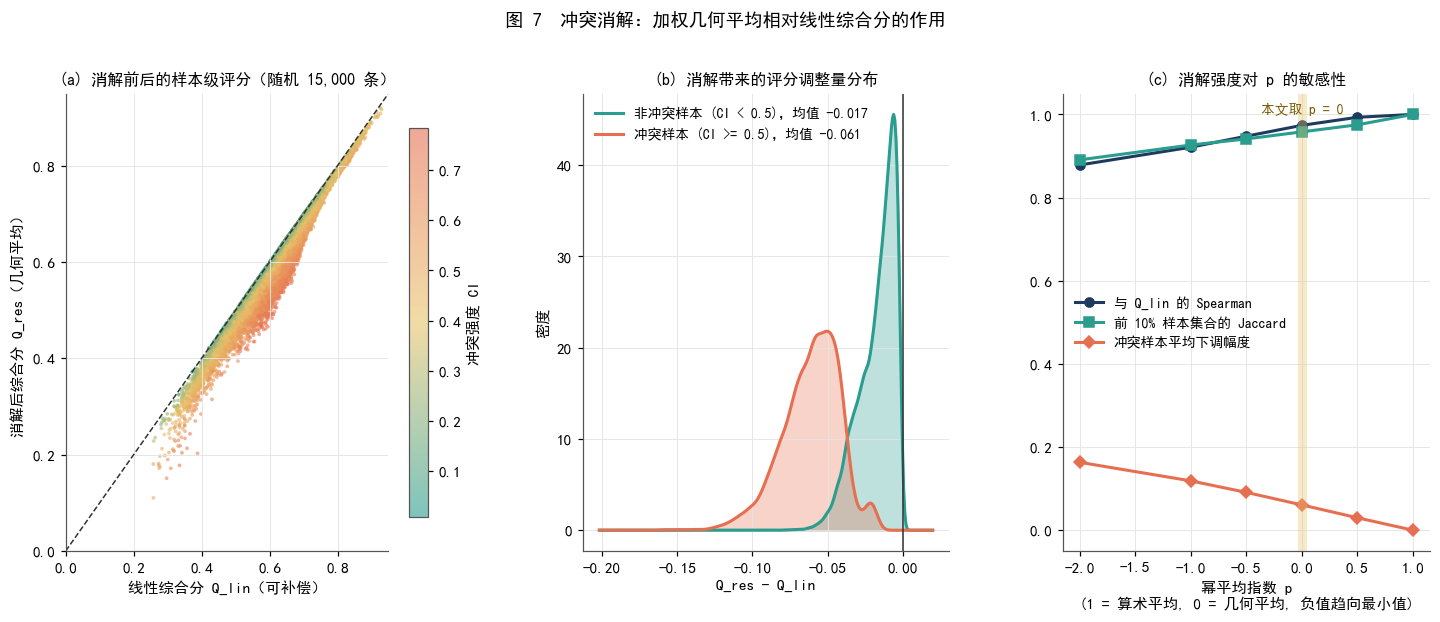

In [69]:
# ============ 2.3 幂平均消解 ============
EPS = 0.01
W_DIM_VEC = W_DIM[list(DIMS)].values

def power_mean(S, p, Wd=W_DIM_VEC):
    Sv = np.clip(np.asarray(S, float), EPS, 1.0); Wd = np.asarray(Wd, float) / np.sum(Wd)
    if abs(p) < 1e-9:
        return np.exp((Wd * np.log(Sv)).sum(axis=1))
    return ((Wd * Sv ** p).sum(axis=1)) ** (1.0 / p)

for A, S in ((A1, S1), (A2, S2), (A3, S3)):
    A['Q_res'] = power_mean(S[list(DIMS)].values, 0.0)
    A['CI'] = S.max(axis=1) - S.min(axis=1)
    A['is_conflict'] = A['CI'] >= TAU
A1['dQ'] = A1['Q_res'] - A1['Q_lin']

print('Q_lin 与 Q_res 的 Spearman 相关: %.4f' % stats.spearmanr(A1['Q_lin'], A1['Q_res'])[0])
chk = A1.groupby('is_conflict').agg(n=('dQ', 'size'), Q_lin均值=('Q_lin', 'mean'), Q_res均值=('Q_res', 'mean'), 平均下调=('dQ', 'mean'), 平均CI=('CI', 'mean'))
chk.index = ['非冲突样本', '冲突样本']
print('规则 2/3 检验：消解后综合分相对线性分的变化'); display(chk)
print('冲突强度与下调幅度的 Spearman 相关: %.3f（规则 3：下调随 CI 单调增加）' % stats.spearmanr(A1['CI'], -A1['dQ'])[0])

# 敏感性：p 与 tau
sens = []
for p in [1.0, 0.5, 0.0, -0.5, -1.0, -2.0]:
    q = power_mean(S1[list(DIMS)].values, p)
    sens.append({'p': p, '与Q_lin的Spearman': stats.spearmanr(A1['Q_lin'], q)[0], '均值': q.mean(),
                 '冲突样本平均下调': (q - A1['Q_lin'])[A1['is_conflict']].mean(), '非冲突样本平均下调': (q - A1['Q_lin'])[~A1['is_conflict']].mean(),
                 '前10%集合与Q_lin的Jaccard': len(set(np.argsort(-q)[:len(q) // 10]) & set(np.argsort(-A1['Q_lin'].values)[:len(q) // 10])) / (len(q) // 10)})
SENS = pd.DataFrame(sens); print('\n幂指数 p 的敏感性:'); display(SENS)
tau_sens = pd.DataFrame({'tau': [0.4, 0.5, 0.6], '冲突样本占比': [(A1['CI'] >= t).mean() for t in (0.4, 0.5, 0.6)],
                         '冲突样本平均下调': [A1.loc[A1['CI'] >= t, 'dQ'].mean() for t in (0.4, 0.5, 0.6)]})
print('阈值 tau 的敏感性:'); display(tau_sens)

# ---- 图 7 ----
fig = plt.figure(figsize=(16, 5.4))
gs = gridspec.GridSpec(1, 3, width_ratios=[1.1, 1, 1], wspace=0.3)
ax = fig.add_subplot(gs[0])
idx = RNG.choice(len(A1), 15000, replace=False)
sc = ax.scatter(A1['Q_lin'].values[idx], A1['Q_res'].values[idx], c=A1['CI'].values[idx], cmap=CMAP_TC, s=6, alpha=0.6, linewidths=0)
lim = (0, max(A1['Q_lin'].max(), A1['Q_res'].max()) + 0.02); ax.plot(lim, lim, color='#333333', lw=1, ls='--'); ax.set_xlim(lim); ax.set_ylim(lim)
cb = plt.colorbar(sc, ax=ax, shrink=0.85); cb.set_label('冲突强度 CI')
ax.set_xlabel('线性综合分 Q_lin（可补偿）'); ax.set_ylabel('消解后综合分 Q_res（几何平均）'); ax.set_title('(a) 消解前后的样本级评分（随机 15,000 条）', fontsize=10.5)
ax = fig.add_subplot(gs[1])
xs = np.linspace(A1['dQ'].min(), 0.02, 300)
for mask, c, lab_ in ((~A1['is_conflict'], C_TEAL, '非冲突样本 (CI < %.1f)' % TAU), (A1['is_conflict'], C_CORAL, '冲突样本 (CI >= %.1f)' % TAU)):
    v = A1.loc[mask, 'dQ'].values; ax.fill_between(xs, stats.gaussian_kde(v)(xs), color=c, alpha=0.3); ax.plot(xs, stats.gaussian_kde(v)(xs), color=c, lw=2, label='%s，均值 %.3f' % (lab_, v.mean()))
ax.axvline(0, color='#333333', lw=1); ax.set_xlabel('Q_res - Q_lin'); ax.set_ylabel('密度'); ax.legend(frameon=False, fontsize=9); ax.set_title('(b) 消解带来的评分调整量分布', fontsize=10.5)
ax = fig.add_subplot(gs[2])
ax.plot(SENS['p'], SENS['与Q_lin的Spearman'], marker='o', color=C_NAVY, lw=2, label='与 Q_lin 的 Spearman')
ax.plot(SENS['p'], SENS['前10%集合与Q_lin的Jaccard'], marker='s', color=C_TEAL, lw=2, label='前 10% 样本集合的 Jaccard')
ax.plot(SENS['p'], -SENS['冲突样本平均下调'], marker='D', color=C_CORAL, lw=2, label='冲突样本平均下调幅度')
ax.axvline(0, color=C_GOLD, lw=6, alpha=0.35); ax.text(0, ax.get_ylim()[1] * 0.98 if ax.get_ylim()[1] > 0 else 0.9, '本文取 p = 0', ha='center', va='top', fontsize=9, color='#7A5C00')
ax.set_xlabel('幂平均指数 p\n(1 = 算术平均, 0 = 几何平均, 负值趋向最小值)'); ax.legend(frameon=False, fontsize=9); ax.set_title('(c) 消解强度对 p 的敏感性', fontsize=10.5)
fig.suptitle('图 7  冲突消解：加权几何平均相对线性综合分的作用', fontsize=12, y=1.02)
savefig('fig07_resolution.png'); plt.show()

### 2.4 用原始文本内容检验评分可靠性

A1 读取原始 `content` 时保存了每条文本的前 200 字符，并计算未进入 22 项质量指标的 URL 密度、非 ASCII 字符占比和营销词命中率。下面展示 $Q^{res}$ 最高、最低及冲突最强样本的文本片段，再按质量分五分位比较内容侧统计量。这些检验用于观察评分是否具有合理的文本对应关系，不把内容统计量作为人工质量真值。

本次运行中，最低质量五分位的非 ASCII 占比为 5.88%、营销词命中率为 0.93%；最高五分位分别为 0.41% 和 0.43%，与评分方向一致。URL 密度在最低、最高五分位分别为每千字符 0.333、0.091，但中间分位并非单调，样本级 Spearman 为 0.051。因此，原始内容检验提供了部分支持，不能概括为所有独立统计量都随评分单调改善。


Q_res 最高的样本
[c4] Q_lin=0.926  Q_res=0.919  CI=0.35  |  维度分: D1=0.93  D2=1.00  D3=0.65  D4=0.98
    Cellular space is compartmentalized into numerous organelles that concentrate specific sets of molecules at distinct locations. In addition to membrane-bound organelles, cells cont

[c4] Q_lin=0.928  Q_res=0.919  CI=0.38  |  维度分: D1=0.95  D2=0.99  D3=0.61  D4=0.97
    The use of antibiotics in the treatment of bacterial diseases has led to the emergence of antibiotic-resistant "superbugs". For preventing this emergence of resistant bacteria, alt

[c4] Q_lin=0.930  Q_res=0.916  CI=0.44  |  维度分: D1=0.99  D2=0.99  D3=0.55  D4=0.95
    "Inductive inference" redirects here. For the technique in mathematical proof, see Mathematical induction. Inductive reasoning (as opposed to deductive reasoning or abductive reaso

Q_res 最低的样本
[github] Q_lin=0.281  Q_res=0.079  CI=0.73  |  维度分: D1=0.01  D2=0.06  D3=0.56  D4=0.74
    <footer>底部</footer>

[github] Q_lin=0.258  Q_res=0.110  CI=0.51  |  维度分: D1=0.

,URL密度,非ASCII占比,营销词命中率,n
Q_quint,,,,
Q1(最低),0.3334,0.0588,0.0093,10246
Q2,0.1548,0.0312,0.0081,10246
Q3,0.1771,0.0165,0.0070,10246
Q4,0.1850,0.0091,0.0074,10246
Q5(最高),0.0914,0.0041,0.0043,10246


Spearman(Q_res, url_density) = 0.051
Spearman(Q_res, frac_nonascii) = -0.140


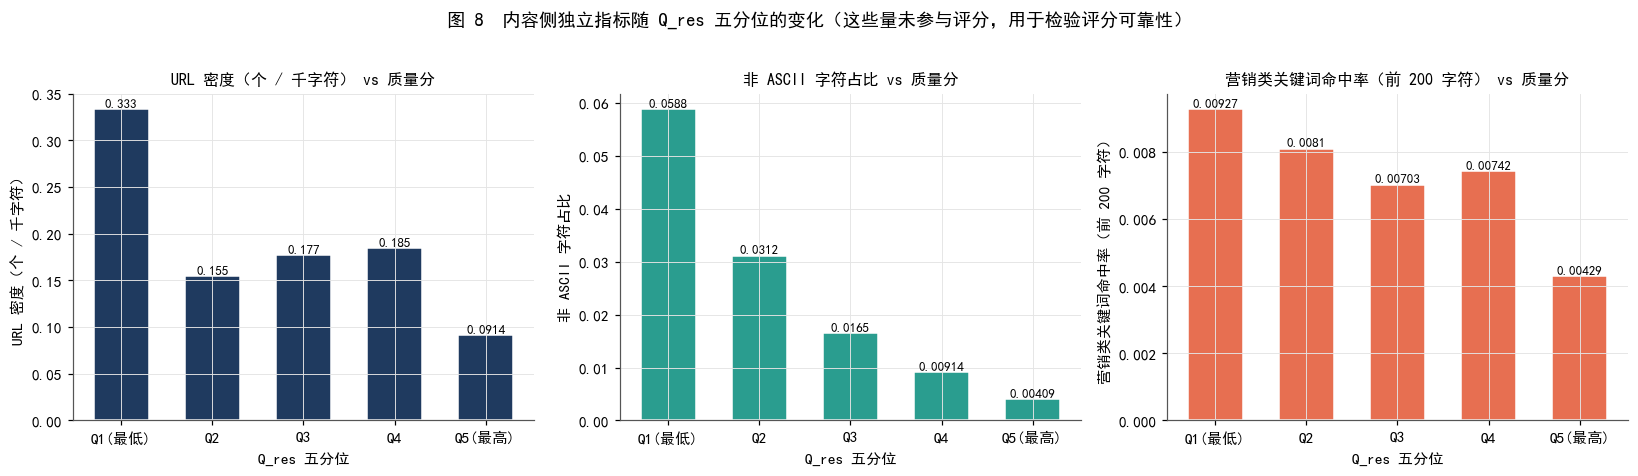

In [70]:
# ============ 2.4 内容检验 ============
def show(df, title, k=3):
    print('=' * 110); print(title); print('=' * 110)
    for _, r in df.head(k).iterrows():
        print('[%s] Q_lin=%.3f  Q_res=%.3f  CI=%.2f  |  维度分: ' % (r['domain'], r['Q_lin'], r['Q_res'], r['CI']) +
              '  '.join('%s=%.2f' % (d[:2], S1.loc[r.name, d]) for d in DIMS))
        print('    ' + str(r['snippet'])[:180]); print()
show(A1.sort_values('Q_res', ascending=False), 'Q_res 最高的样本')
show(A1.sort_values('Q_res'), 'Q_res 最低的样本')
show(A1.sort_values('CI', ascending=False), '冲突强度最高的样本（可看到"某维度极高 + 某维度极低"）')

A1['url_density'] = 1000 * A1['n_url'] / A1['n_chars'].clip(lower=1)
KW = ['click here', 'subscribe', 'buy now', 'free shipping', 'sign up', 'discount', 'cookie', 'log in', 'add to cart', 'best price', 'coupon', 'newsletter']
snip = A1['snippet'].fillna('').str.lower()
A1['kw_hit'] = np.column_stack([snip.str.contains(k, regex=False) for k in KW]).any(axis=1)
A1['Q_quint'] = pd.qcut(A1['Q_res'].rank(method='first'), 5, labels=['Q1(最低)', 'Q2', 'Q3', 'Q4', 'Q5(最高)'])
qc = A1.groupby('Q_quint').agg(URL密度=('url_density', 'mean'), 非ASCII占比=('frac_nonascii', 'mean'), 营销词命中率=('kw_hit', 'mean'), n=('kw_hit', 'size'))
print('\n按 Q_res 五分位的内容侧独立指标（未参与评分）:'); display(qc)
for col in ['url_density', 'frac_nonascii']:
    print('Spearman(Q_res, %s) = %.3f' % (col, stats.spearmanr(A1['Q_res'], A1[col].fillna(0))[0]))

fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
for ax, (col, lab_, c) in zip(axes, (('URL密度', 'URL 密度（个 / 千字符）', C_NAVY), ('非ASCII占比', '非 ASCII 字符占比', C_TEAL), ('营销词命中率', '营销类关键词命中率（前 200 字符）', C_CORAL))):
    ax.bar(qc.index.astype(str), qc[col], color=c, edgecolor='white', width=0.6)
    for i, v in enumerate(qc[col]):
        ax.text(i, v, '%.3g' % v, ha='center', va='bottom', fontsize=8.5)
    ax.set_ylabel(lab_); ax.set_xlabel('Q_res 五分位'); ax.set_title(lab_ + ' vs 质量分', fontsize=10.5)
fig.suptitle('图 8  内容侧独立指标随 Q_res 五分位的变化（这些量未参与评分，用于检验评分可靠性）', fontsize=12, y=1.02)
plt.tight_layout(); savefig('fig08_content_check.png'); plt.show()

### 2.5 在扩展集上检验冲突结论

题目要求冲突分析覆盖抽样集，并在扩展集上检验主要结论是否同样成立。扩展集只有 arxiv 与 github 两个域，因此正确的对照组是 **A1 中的 arxiv 子集 vs A2 非重叠余集**、**A1 中的 github 子集 vs A3 非重叠余集**（而不是 A1 全体），所有阈值沿用 A1 全体的分位数。检验三个层次：
1. **冲突结构**：两组冲突倍率矩阵上三角元素的 Spearman 相关、Top-20 冲突对的 Jaccard 重合度；
2. **冲突水平**：冲突样本占比与平均冲突强度；
3. **消解效果**：$Q^{res}$ 对冲突样本的平均下调幅度、$Q^{res}$ 与 $Q^{lin}$ 的秩相关。

扩展集包含 A1 的同 ID 样本，因此复现检验使用与 A1 ID 不重叠的余集；A2/A3 全量仍用于域级质量聚合（合并时按 ID 去重）。本次运行中，arxiv、github 的冲突倍率矩阵与扩展余集的 Spearman 分别为 0.980、0.999；冲突样本占比分别由 11.84% 对应到 11.98%、由 6.92% 对应到 6.80%。第 7 节直接复用本节的 $Q^{res}$，不再次拟合质量模型。

抽样集子集 vs 扩展集：冲突结论的一致性（冲突矩阵按域内分位阈值计算）


,0,1
域,arxiv,github
A1子集n,1419,10000
扩展集非重叠n,16104,193752
冲突矩阵Spearman,0.9798,0.9985
Top20冲突对Jaccard,0.9048,0.9048
冲突样本占比_A1,0.1184,0.0692
冲突样本占比_扩展,0.1198,0.0680
平均CI_A1,0.4338,0.3030
平均CI_扩展,0.4347,0.3027
冲突样本下调_A1,-0.0218,-0.0672


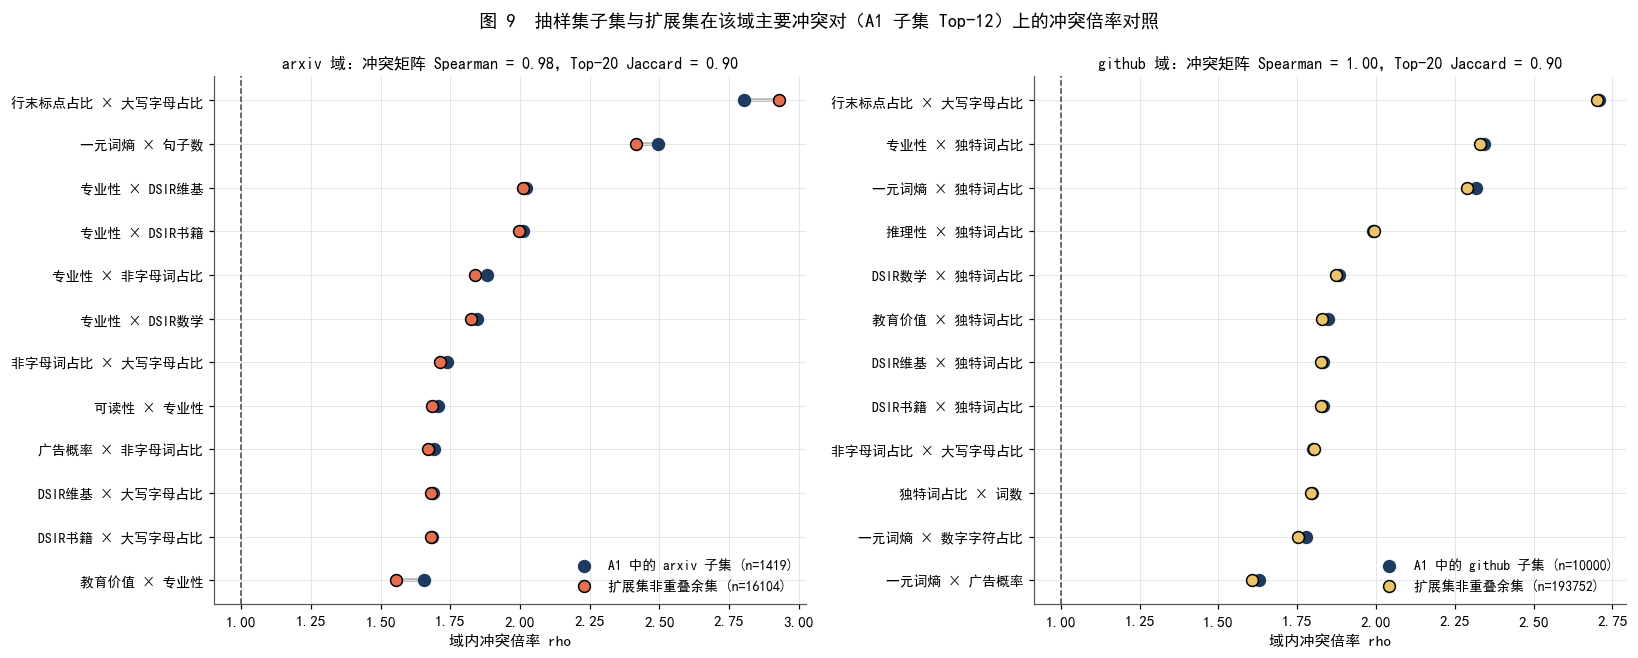

最终域级质量评分表（Q_res 为消解后综合分；已保存问题一_最终整合结果/tables/domain_Q.csv）:


,数据集,域,n,Q_res_doc均值,CI95低,CI95高,Q_res_语料(词数加权),Q_res_中位数,Q_lin_doc均值,Q_lin_语料(词数加权)
0,A1 抽样集,arxiv,1419,0.7961,0.7947,0.7975,0.7932,0.8003,0.8116,0.8101
1,A1 抽样集,book,171,0.6078,0.5972,0.6206,0.6198,0.6085,0.6271,0.6398
2,A1 抽样集,c4,10000,0.5903,0.5883,0.5922,0.6468,0.5821,0.6410,0.6840
3,A1 抽样集,commoncrawl,9640,0.6155,0.6133,0.6175,0.6471,0.6094,0.6440,0.6699
4,A1 抽样集,github,10000,0.5179,0.5162,0.5195,0.5576,0.5295,0.5355,0.5804
5,A1 抽样集,stackexchange,10000,0.6450,0.6435,0.6463,0.6680,0.6465,0.6540,0.6770
6,A1 抽样集,wikipedia,10000,0.5248,0.5233,0.5270,0.6099,0.5176,0.5486,0.6264
7,A2 扩展集,arxiv,17523,0.7953,0.7948,0.7958,0.7926,0.7994,0.8110,0.8096
8,A3 扩展集,github,203752,0.5171,0.5167,0.5175,0.5558,0.5268,0.5345,0.5782
9,抽样+扩展 合并全量(按ID去重),arxiv,17523,0.7953,0.7948,0.7958,0.7926,0.7994,0.8110,0.8096


In [71]:
# ============ 2.5 扩展集检验 ============
def upper(M):
    v = M.values; iu = np.triu_indices_from(v, 1); return v[iu]

ext_rows, ext_mats, ext_top = [], {}, {}
for d, Xe, Ae in (('arxiv', X2, A2), ('github', X3, A3)):
    m1 = A1['domain'] == d
    keep = ~Ae['id'].isin(A1.loc[m1, 'id'])
    Ae, Xe = Ae.loc[keep].copy(), Xe.loc[keep].copy()
    # 域内冲突结构：阈值取该域在 A1 中的 25% / 75% 分位数（A1 全体阈值会让整域落在同一侧，域内冲突退化）
    tlo, thi = X1.loc[m1].quantile(Q_LO), X1.loc[m1].quantile(Q_HI)
    Ca, Ea, Ra, Za = conflict_matrix(X1.loc[m1], tlo, thi); Cb, Eb, Rb, Zb = conflict_matrix(Xe, tlo, thi)
    ext_mats[d] = (Ra, Rb)
    ua, ub = upper(Ra), upper(Rb); ok = ~(np.isnan(ua) | np.isnan(ub))
    ra = pd.Series([Ra.loc[a, b] for a, b in zip(PAIRS['j'], PAIRS['k'])], index=PAIRS.index); rb = pd.Series([Rb.loc[a, b] for a, b in zip(PAIRS['j'], PAIRS['k'])], index=PAIRS.index)
    topa = set(ra.sort_values(ascending=False).head(20).index); topb = set(rb.sort_values(ascending=False).head(20).index)
    ext_top[d] = ra.sort_values(ascending=False).head(12).index
    sub = A1.loc[m1]
    ext_rows.append({'域': d, 'A1子集n': int(m1.sum()), '扩展集非重叠n': len(Ae),
                     '冲突矩阵Spearman': stats.spearmanr(ua[ok], ub[ok])[0], 'Top20冲突对Jaccard': len(topa & topb) / len(topa | topb),
                     '冲突样本占比_A1': sub['is_conflict'].mean(), '冲突样本占比_扩展': Ae['is_conflict'].mean(),
                     '平均CI_A1': sub['CI'].mean(), '平均CI_扩展': Ae['CI'].mean(),
                     '冲突样本下调_A1': (sub['Q_res'] - sub['Q_lin'])[sub['is_conflict']].mean(), '冲突样本下调_扩展': (Ae['Q_res'] - Ae['Q_lin'])[Ae['is_conflict']].mean(),
                     'Spearman(Qlin,Qres)_A1': stats.spearmanr(sub['Q_lin'], sub['Q_res'])[0], 'Spearman(Qlin,Qres)_扩展': stats.spearmanr(Ae['Q_lin'], Ae['Q_res'])[0]})
EXT = pd.DataFrame(ext_rows); print('抽样集子集 vs 扩展集：冲突结论的一致性（冲突矩阵按域内分位阈值计算）'); display(EXT.T)
EXT.to_csv(TAB / 'conflict_extended_check.csv', index=False, encoding='utf-8-sig')

# ---- 图 9：哑铃图（各域 A1 子集 Top-12 冲突对在扩展集上的复现） ----
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
for ax, (d, c) in zip(axes, (('arxiv', C_CORAL), ('github', C_GOLD))):
    Ra, Rb = ext_mats[d]; top12 = PAIRS.loc[ext_top[d]]
    va = np.array([Ra.loc[a, b] for a, b in zip(top12['j'], top12['k'])]); vb = np.array([Rb.loc[a, b] for a, b in zip(top12['j'], top12['k'])])
    y = np.arange(len(top12))[::-1]
    ax.hlines(y, va, vb, color='#BBBBBB', lw=2.5, zorder=1)
    ax.scatter(va, y, color=C_NAVY, s=60, zorder=3, label='A1 中的 %s 子集 (n=%d)' % (d, (A1['domain'] == d).sum()))
    ax.scatter(vb, y, color=c, s=60, zorder=3, label='扩展集非重叠余集 (n=%d)' % int(EXT.set_index('域').loc[d, '扩展集非重叠n']), edgecolor='black')
    ax.axvline(1, color='#444444', ls='--', lw=1)
    ax.set_yticks(y); ax.set_yticklabels([a + ' × ' + b for a, b in zip(top12['指标j'], top12['指标k'])], fontsize=9)
    r = EXT.set_index('域').loc[d]
    ax.set_title('%s 域：冲突矩阵 Spearman = %.2f，Top-20 Jaccard = %.2f' % (d, r['冲突矩阵Spearman'], r['Top20冲突对Jaccard']), fontsize=10.5)
    ax.set_xlabel('域内冲突倍率 rho'); ax.legend(frameon=False, loc='best', fontsize=9)
fig.suptitle('图 9  抽样集子集与扩展集在该域主要冲突对（A1 子集 Top-12）上的冲突倍率对照', fontsize=12, y=0.99)
plt.tight_layout(); savefig('fig09_extended_conflict_check.png'); plt.show()

# ---- 最终域级 Q 表（线性 + 消解后；A1、扩展集、以及 arxiv/github 的合并全量） ----
DT_res = domain_table([('A1 抽样集', A1), ('A2 扩展集', A2), ('A3 扩展集', A3)], 'Q_res')
pool = pd.concat([A1[A1['domain'].isin(['arxiv', 'github'])], A2, A3], ignore_index=True).drop_duplicates('id', keep='last')
assert len(pool) == len(A2) + len(A3), 'A1/A2/A3 ID 去重后数量不符'
DT_pool = domain_table([('抽样+扩展 合并全量(按ID去重)', pool)], 'Q_res')
DT_lin_pool = domain_table([('抽样+扩展 合并全量(按ID去重)', pool)], 'Q_lin')
DOMAIN_Q = pd.concat([DT_res, DT_pool], ignore_index=True)
DOMAIN_Q = DOMAIN_Q.merge(pd.concat([DT_lin, DT_lin_pool], ignore_index=True)[['数据集', '域', 'Q_lin_doc均值', 'Q_lin_语料(词数加权)']], on=['数据集', '域'], how='left')
DOMAIN_Q.to_csv(TAB / 'domain_Q.csv', index=False, encoding='utf-8-sig')
print('最终域级质量评分表（Q_res 为消解后综合分；已保存问题一_最终整合结果/tables/domain_Q.csv）:'); display(DOMAIN_Q)

# 样本级评分导出（供论文附录 / 问题二）
for A, name in ((A1, 'A1'), (A2, 'A2'), (A3, 'A3')):
    A[['id', 'domain', 'Q_lin', 'Q_res', 'CI', 'is_conflict']].to_csv(TAB / ('sample_Q_%s.csv' % name), index=False, encoding='utf-8-sig')

## 3. 领域配比建模

### 3.1 数据结构、模型形式与推导

A4–A15 来自 RegMix（Liu et al., ICLR 2025）：512 个 1M 参数小模型各用一个随机配比 $\mathbf p\in\Delta^{16}$（17 个 The Pile 子域，$p_i\ge0,\ \sum_i p_i=1$）训练，记录 13 个验证域上的交叉熵损失；检验集是 1M（256 组）、60M（256 组）、1B（64 组）三个尺度下 **新的配比**；外推表是训练配比中的 63 组在 10B / 70B 尺度下 **由 1M/60M/1B 三点幂律外推** 的损失（非实测）。17 个域中 `nih_exporter, enron_emails, europarl, philpapers` 没有验证损失，本文将其 **保留为输入变量**（它们仍占用配比份额），但不作为输出目标。

**因变量**。13 个验证域各有一个损失 $L_v(\mathbf p)$。本文以 13 域 **等权平均损失** $\bar L(\mathbf p)=\frac1{13}\sum_v L_v(\mathbf p)$ 作为主目标（衡量配比的综合效果），同时对每个 $L_v$ 单独建模，得到"配方域 → 验证域"的跨域迁移矩阵。

**模型形式的推导——对数线性混料模型**。总训练数据量为 $D$ 时，域 $i$ 的有效数据量是 $D_i=D\,p_i$。经典标度律告诉我们损失随数据量按幂律下降 $L\propto D^{-\beta}$；把 13 个验证域的损失看成各域数据"贡献"的叠加，并把每个域的幂律项 $A_i (D p_i)^{-\beta_i}$ 在训练配比的典型取值附近对 $\ln p_i$ 做一阶展开，得到

$$\bar L(\mathbf p)=c+\sum_{i=1}^{17} a_i\,\ln\!\big(p_i+\varepsilon\big),\qquad a_i=\frac{\partial \bar L}{\partial \ln(p_i+\varepsilon)} ,$$

其中 $\varepsilon=10^{-3}$ 是防止 $p_i=0$ 时对数发散的平滑常数（其敏感性仅在训练集内部交叉验证），$a_i$ 是对平滑对数份额的局部响应系数；当 $p_i\gg\varepsilon$ 时，份额相对增加 1% 对应的损失变化约为 $a_i/100$。它自然地刻画了 **边际收益递减**（$\partial \bar L/\partial p_i=a_i/(p_i+\varepsilon)$ 随份额增大而衰减），这正是线性模型 $\sum_i a_i p_i$ 做不到的——后者暗含"损失随份额线性变化"，与标度律矛盾。

沿单纯形方向（把一小部分数据按当前比例换成域 $i$ 的数据）的边际效应为
$$g_i(\mathbf p)=\nabla\bar L(\mathbf p)\cdot(\mathbf e_i-\mathbf p)=\frac{a_i}{p_i+\varepsilon}-\sum_{k}\frac{a_k\,p_k}{p_k+\varepsilon},$$
它满足 $\sum_i p_i g_i(\mathbf p)=0$（在单纯形上"所有方向的加权平均"必为零），因此 $g_i<0$ 的含义是"域 $i$ 比当前配比的平均域更值得增加"。

**四类模型并行比较**：

| 模型 | 形式 | 参数量 | 作用 |
|---|---|---|---|
| 线性混料（Scheffé 一阶） | $\sum_i a_i p_i$（无截距，$\sum p_i=1$ 吸收截距） | 17 | 基线，说明线性假设不成立 |
| 对数线性混料 | $c+\sum_i a_i\ln(p_i+\varepsilon)$ | 18 | 可解释、可解析求最优配比、跨尺度稳健 |
| 对数二阶 + 岭回归 | $c+\sum_i a_i z_i+\sum_{i\le k} b_{ik} z_i z_k,\ z_i=\ln(p_i+\varepsilon)$ | 171 | 刻画域间交互（互补 / 替代），$\alpha$ 由留一交叉验证选取 |
| 梯度提升树 GBM | $F_M(\mathbf p)=\sum_{m=1}^{M}\nu\,h_m(\mathbf p)$，深度 3 的回归树逐棵拟合残差 | — | 非参数预测基准（RegMix 原文采用 LightGBM） |

**评价指标**。60M、1B 检验集的损失 **绝对水平** 与 1M 训练集不同（模型越大损失越低），代理模型的任务是 **对配比排序**，因此以 Spearman 秩相关 $\rho$ 为主，辅以 $R^2$、RMSE；训练集内部用 5 折交叉验证。

**模型安排**：对数线性模型提供可解释的份额响应基准；第 3.1a 节在此基础上加入域内曲率，建立 SCM。线性混料、完整二阶岭回归与 GBM 用于比较。第 5 节筛选稳定交互构成 SCI；第 6 节学习保持均值的逐域残差，并在训练配比凸包内给出代理模型推荐。代理回归与混料函数的研究背景见 [3]、[4]。

训练集: 512 组配比 × 17 个域;  验证损失 13 个域;  无验证损失的域: ['enron_emails', 'europarl', 'nih_exporter', 'philpapers']
  1M 检验集 (A6/A7)         n=256  平均损失 5.282 ± 0.278
  60M 检验集 (A8/A9)        n=256  平均损失 3.823 ± 0.219
  1B 检验集 (A10/A11)       n= 64  平均损失 2.226 ± 0.052
  10B 外推表 (A12/A13)      n= 63  平均损失 1.797 ± 0.096
  70B 外推表 (A14/A15)      n= 63  平均损失 1.415 ± 0.104
训练集平均损失 5.345 ± 0.324，配比行和范围 [0.996, 1.003]
外推表配比与训练集重合: 63 / 63 行 index 相同


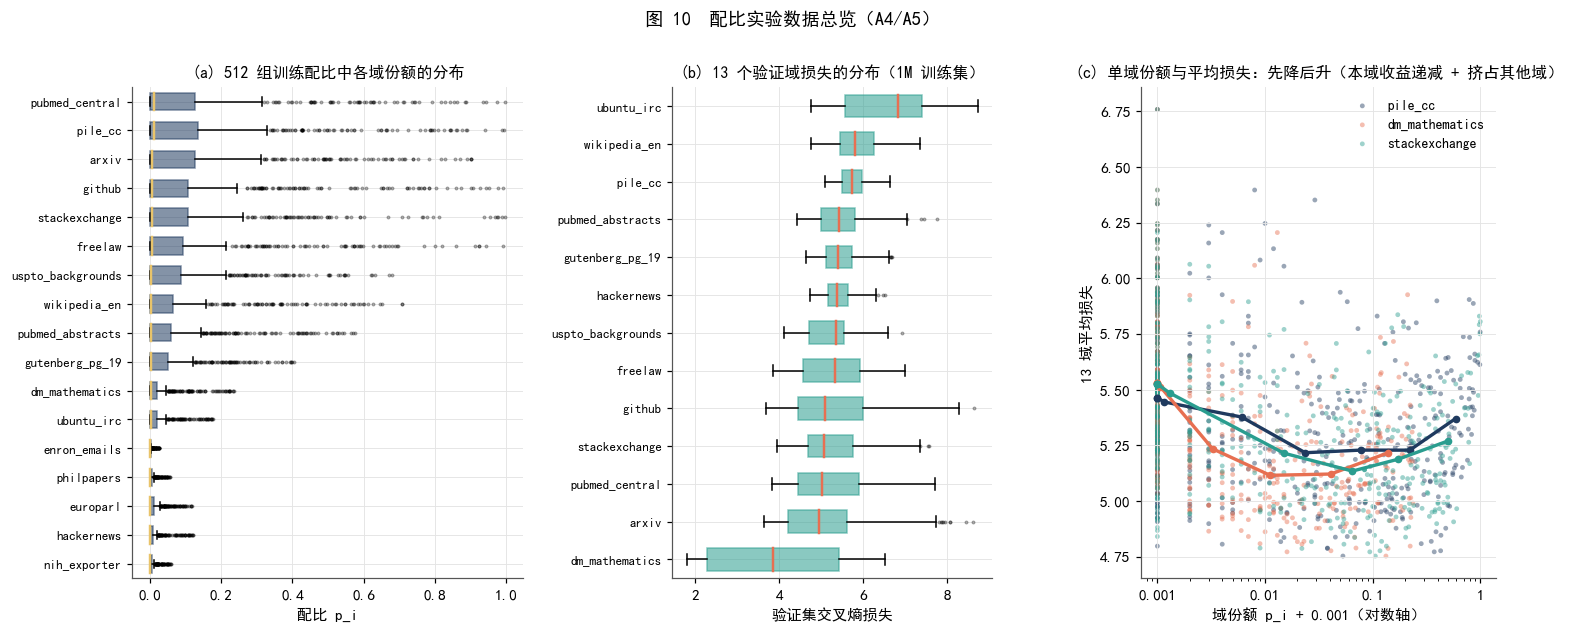

In [72]:
# ============ 3.1 读取配比实验数据 ============
def load_pair(mix_name, loss_name):
    mix = pd.read_csv(REG / mix_name); loss = pd.read_csv(REG / loss_name)
    mc = [c for c in mix.columns if c.startswith('train_')]; lc = [c for c in loss.columns if c.endswith('_val_loss')]
    df = mix[['index'] + mc].merge(loss[['index'] + lc], on='index')
    P = df[mc].values.astype(float); P = P / P.sum(axis=1, keepdims=True)   # 消除千分位舍入误差，严格落在单纯形上
    return df, P, df[lc].values.astype(float), mc, lc

TR, P_tr, Y_tr, MIX_COLS, LOSS_COLS = load_pair('train_mixture_1m.csv', 'train_pile_loss_1m.csv')
DOM17 = [c.replace('train_the_pile_', '') for c in MIX_COLS]
VAL13 = [c.replace('metric/the_pile_', '').replace('_val_loss', '') for c in LOSS_COLS]
TESTS = {'1M 检验集 (A6/A7)': load_pair('test_mixture_1m.csv', 'test_pile_loss_1m.csv'),
         '60M 检验集 (A8/A9)': load_pair('test_mixture_60m.csv', 'test_pile_loss_60m.csv'),
         '1B 检验集 (A10/A11)': load_pair('test_mixture_1B.csv', 'test_pile_loss_1B.csv')}
ESTS = {'10B 外推表 (A12/A13)': load_pair('est_mixture_10b.csv', 'est_pile_loss_10b.csv'),
        '70B 外推表 (A14/A15)': load_pair('est_mixture_70b.csv', 'est_pile_loss_70b.csv')}
y_tr = Y_tr.mean(axis=1)
print('训练集: %d 组配比 × %d 个域;  验证损失 %d 个域;  无验证损失的域: %s' % (len(TR), len(DOM17), len(VAL13), sorted(set(DOM17) - set(VAL13))))
for k, (df, P, Y, _, _) in list(TESTS.items()) + list(ESTS.items()):
    print('  %-22s n=%3d  平均损失 %.3f ± %.3f' % (k, len(df), Y.mean(), Y.mean(axis=1).std()))
print('训练集平均损失 %.3f ± %.3f，配比行和范围 [%.3f, %.3f]' % (y_tr.mean(), y_tr.std(), TR[MIX_COLS].sum(axis=1).min(), TR[MIX_COLS].sum(axis=1).max()))
print('外推表配比与训练集重合: %d / 63 行 index 相同' % len(set(ESTS['10B 外推表 (A12/A13)'][0]['index']) & set(TR['index'])))

# ---- 图 10：配比实验数据总览 ----
fig = plt.figure(figsize=(16, 5.8))
gs = gridspec.GridSpec(1, 3, width_ratios=[1.1, 0.9, 1], wspace=0.42)
ax = fig.add_subplot(gs[0])
Pdf = pd.DataFrame(P_tr, columns=DOM17); order_p = Pdf.median().sort_values().index
bp = ax.boxplot([Pdf[d] for d in order_p], vert=False, patch_artist=True, widths=0.6, showfliers=True, flierprops=dict(marker='.', markersize=3, alpha=0.4, color=C_GREY))
for patch in bp['boxes']: patch.set(facecolor=C_NAVY, alpha=0.55, edgecolor=C_NAVY)
for med in bp['medians']: med.set(color=C_GOLD, lw=1.6)
ax.set_yticks(np.arange(1, len(order_p) + 1)); ax.set_yticklabels(order_p, fontsize=8.5); ax.set_xlabel('配比 p_i'); ax.set_title('(a) 512 组训练配比中各域份额的分布', fontsize=10.5)
ax = fig.add_subplot(gs[1])
Ldf = pd.DataFrame(Y_tr, columns=VAL13); order_l = Ldf.median().sort_values().index
bp = ax.boxplot([Ldf[d] for d in order_l], vert=False, patch_artist=True, widths=0.6, flierprops=dict(marker='.', markersize=3, alpha=0.4, color=C_GREY))
for patch in bp['boxes']: patch.set(facecolor=C_TEAL, alpha=0.55, edgecolor=C_TEAL)
for med in bp['medians']: med.set(color=C_CORAL, lw=1.6)
ax.set_yticks(np.arange(1, len(order_l) + 1)); ax.set_yticklabels(order_l, fontsize=8.5); ax.set_xlabel('验证集交叉熵损失'); ax.set_title('(b) 13 个验证域损失的分布（1M 训练集）', fontsize=10.5)
ax = fig.add_subplot(gs[2])
# 单域"份额-损失"关系：以 pile_cc 与 dm_mathematics 为例展示边际收益递减（对数横轴）
for d, c in (('pile_cc', C_NAVY), ('dm_mathematics', C_CORAL), ('stackexchange', C_TEAL)):
    i = DOM17.index(d); ax.scatter(P_tr[:, i] + 1e-3, y_tr, s=10, color=c, alpha=0.45, edgecolor='none', label=d)
    bins = np.quantile(P_tr[:, i] + 1e-3, np.linspace(0, 1, 9)); ctr, mean_ = [], []
    for lo_, hi_ in zip(bins[:-1], bins[1:]):
        m_ = (P_tr[:, i] + 1e-3 >= lo_) & (P_tr[:, i] + 1e-3 <= hi_)
        if m_.sum() > 3: ctr.append(np.exp(np.log(P_tr[m_, i] + 1e-3).mean())); mean_.append(y_tr[m_].mean())
    ax.plot(ctr, mean_, color=c, lw=2.2, marker='o', ms=4)
ax.set_xscale('log'); ax.xaxis.set_major_formatter(mpl.ticker.FuncFormatter(lambda v, _: '%g' % v)); ax.xaxis.set_minor_formatter(mpl.ticker.NullFormatter())
ax.set_xlabel('域份额 p_i + 0.001（对数轴）'); ax.set_ylabel('13 域平均损失'); ax.legend(frameon=False, fontsize=9)
ax.set_title('(c) 单域份额与平均损失：先降后升（本域收益递减 + 挤占其他域）', fontsize=10.5)
fig.suptitle('图 10  配比实验数据总览（A4/A5）', fontsize=12, y=1.0)
savefig('fig10_regmix_overview.png'); plt.show()

对数平滑常数 epsilon 的训练集内部敏感性（原基线仍固定 1e-3）:


,epsilon,训练集R2,5折CV Spearman
0,0.0001,0.8535,0.9410
1,0.0010,0.8559,0.9432
2,0.0100,0.8227,0.9186
3,0.0300,0.7908,0.8925



四类代理模型的拟合与检验（目标 = 13 域平均损失；60M/1B 的 R2 因损失绝对水平不同而无意义，以 Spearman 为准）:


模型,线性混料 (Scheffe一阶),对数线性混料 (主模型),对数二阶 + 岭回归,梯度提升树 GBM
训练集 R2,0.2961,0.8559,0.9749,0.9918
5折CV Spearman,0.4935,0.9432,0.9688,0.9616
5折CV R2,0.2311,0.8491,0.9368,0.9112
1M 检验集 (A6/A7) Spearman,0.6245,0.9316,0.9751,0.9671
1M 检验集 (A6/A7) R2,0.3273,0.8514,0.9521,0.9252
60M 检验集 (A8/A9) Spearman,0.5584,0.9116,0.9498,0.9301
60M 检验集 (A8/A9) R2,-47.2602,-45.3041,-44.2179,-45.4825
1B 检验集 (A10/A11) Spearman,0.3685,0.7548,0.6039,0.7211
1B 检验集 (A10/A11) R2,-3781.2921,-2637.3115,-2886.5133,-2932.8268


对数二阶岭回归选定的正则系数 alpha = 1


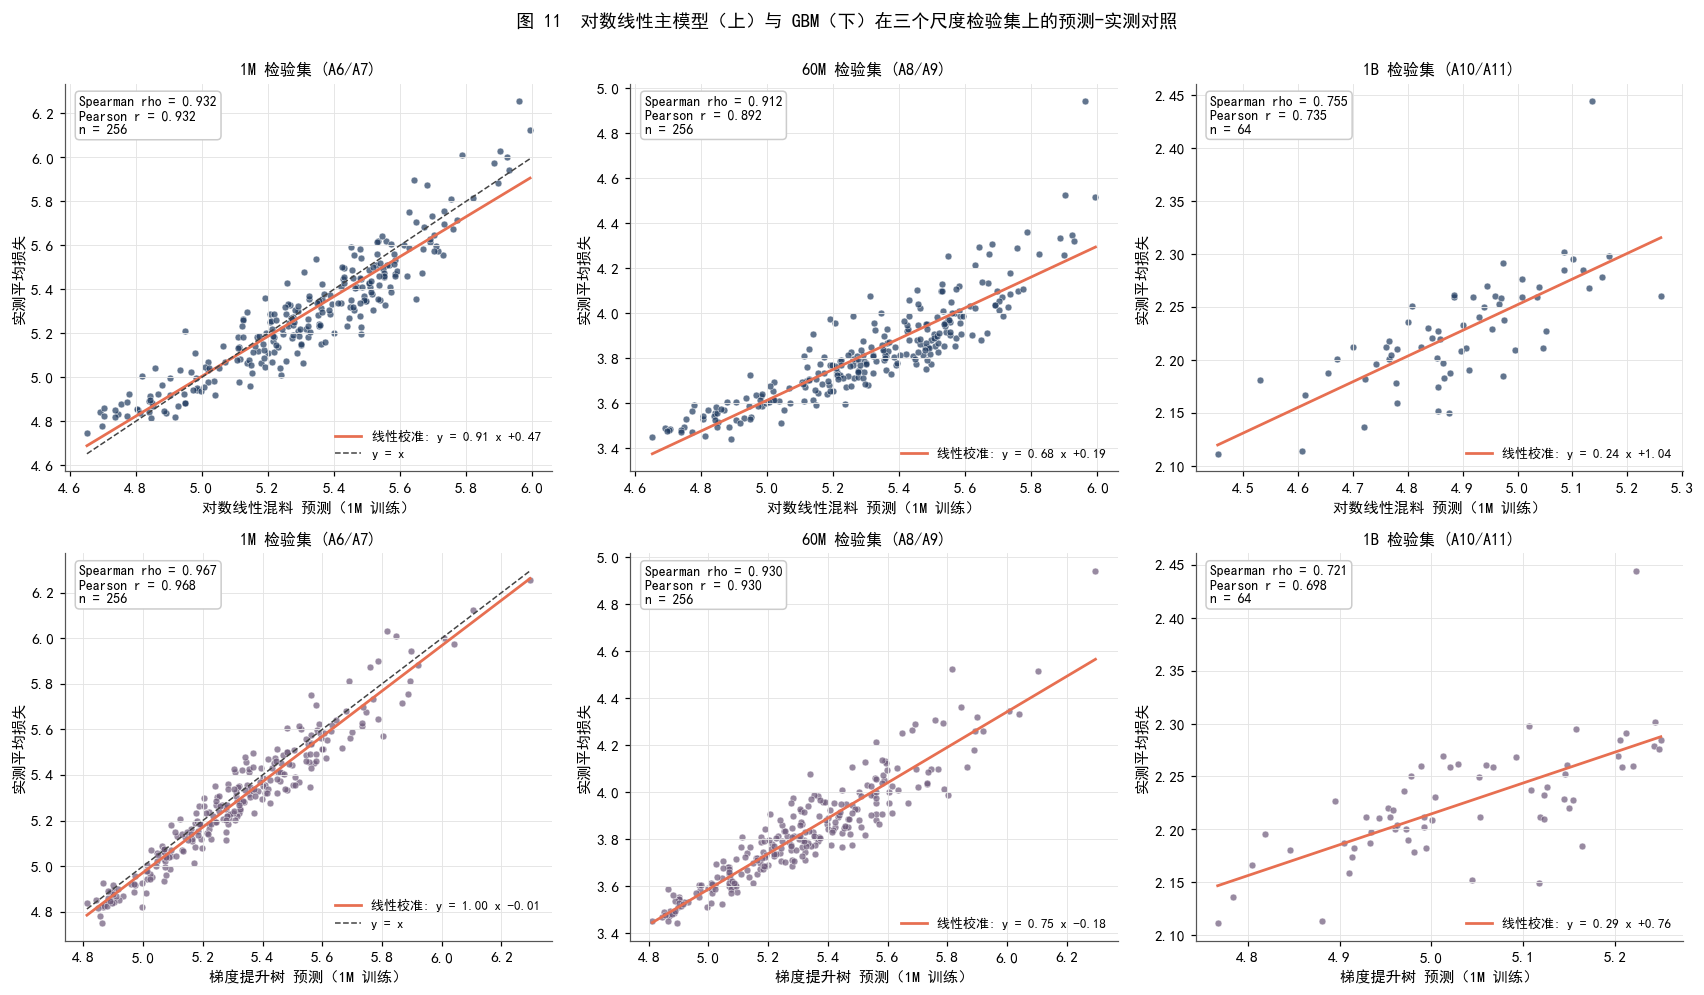

In [73]:
# ============ 3.1 四类代理模型：训练、交叉验证与检验集评估 ============
EPS_LOG = 1e-3
def zlog(P): return np.log(np.asarray(P, float) + EPS_LOG)
PF = PolynomialFeatures(degree=2, include_bias=False); PF.fit(zlog(P_tr))

def make_models():
    return {'线性混料 (Scheffe一阶)': ('lin', LinearRegression(fit_intercept=False)),
            '对数线性混料 (主模型)': ('log', LinearRegression()),
            '对数二阶 + 岭回归': ('logq', RidgeCV(alphas=np.logspace(-4, 3, 50))),
            '梯度提升树 GBM': ('gbm', GradientBoostingRegressor(n_estimators=500, learning_rate=0.03, max_depth=3, subsample=0.8, random_state=0))}

def feats(kind, P):
    if kind == 'log': return zlog(P)
    if kind == 'logq': return PF.transform(zlog(P))
    return np.asarray(P, float)

def metrics(y, yhat):
    return {'Spearman': stats.spearmanr(y, yhat)[0], 'Pearson': stats.pearsonr(y, yhat)[0],
            'R2': 1 - ((y - yhat) ** 2).sum() / ((y - y.mean()) ** 2).sum(), 'RMSE': np.sqrt(((y - yhat) ** 2).mean())}

# epsilon 敏感性（对数线性模型）
eps_rows = []
for e in [1e-4, 1e-3, 1e-2, 3e-2]:
    Z = np.log(P_tr + e); m = LinearRegression().fit(Z, y_tr)
    cv_hat = np.empty_like(y_tr)
    for tr_i, va_i in KFold(5, shuffle=True, random_state=0).split(Z):
        cv_m = LinearRegression().fit(Z[tr_i], y_tr[tr_i])
        cv_hat[va_i] = cv_m.predict(Z[va_i])
    eps_rows.append({'epsilon': e, '训练集R2': m.score(Z, y_tr),
                     '5折CV Spearman': stats.spearmanr(y_tr, cv_hat)[0]})
print('对数平滑常数 epsilon 的训练集内部敏感性（原基线仍固定 1e-3）:'); display(pd.DataFrame(eps_rows))

rows, FITTED, PRED = [], {}, {}
kf = KFold(5, shuffle=True, random_state=0)
for name, (kind, model) in make_models().items():
    Xtr = feats(kind, P_tr); cv_pred = np.zeros_like(y_tr)
    for tr_i, va_i in kf.split(Xtr):
        m = make_models()[name][1]; m.fit(Xtr[tr_i], y_tr[tr_i]); cv_pred[va_i] = m.predict(Xtr[va_i])
    model.fit(Xtr, y_tr); FITTED[name] = (kind, model)
    r = {'模型': name, '训练集 R2': metrics(y_tr, model.predict(Xtr))['R2'], '5折CV Spearman': metrics(y_tr, cv_pred)['Spearman'], '5折CV R2': metrics(y_tr, cv_pred)['R2']}
    for tn, (df, P, Y, _, _) in TESTS.items():
        yh = model.predict(feats(kind, P)); mt = metrics(Y.mean(axis=1), yh); PRED[(name, tn)] = yh
        r[tn + ' Spearman'] = mt['Spearman']; r[tn + ' R2'] = mt['R2']
    rows.append(r)
EVAL = pd.DataFrame(rows).set_index('模型')
print('\n四类代理模型的拟合与检验（目标 = 13 域平均损失；60M/1B 的 R2 因损失绝对水平不同而无意义，以 Spearman 为准）:')
display(EVAL.T)
EVAL.to_csv(TAB / 'mixture_model_eval.csv', encoding='utf-8-sig')
kind_l, model_l = FITTED['对数线性混料 (主模型)']
kind_q, model_q = FITTED['对数二阶 + 岭回归']
kind_g, model_g = FITTED['梯度提升树 GBM']
pred_log = lambda P: model_l.predict(zlog(P))
pred_gbm = lambda P: model_g.predict(np.asarray(P, float))
print('对数二阶岭回归选定的正则系数 alpha = %.3g' % model_q.alpha_)

# ---- 图 11：主模型与 GBM 在三个尺度检验集上的预测-实测 ----
fig, axes = plt.subplots(2, 3, figsize=(15.5, 9))
for row, name in enumerate(['对数线性混料 (主模型)', '梯度提升树 GBM']):
    for ax, (tn, (df, P, Y, _, _)) in zip(axes[row], TESTS.items()):
        y = Y.mean(axis=1); yh = PRED[(name, tn)]; mt = metrics(y, yh)
        ax.scatter(yh, y, s=20, color=C_NAVY if row == 0 else C_PLUM, alpha=0.7, edgecolor='white', linewidths=0.4)
        a_, b_ = np.polyfit(yh, y, 1); xs = np.linspace(yh.min(), yh.max(), 50)
        ax.plot(xs, a_ * xs + b_, color=C_CORAL, lw=1.8, label='线性校准: y = %.2f x %+.2f' % (a_, b_))
        if abs(y.mean() - yh.mean()) < 0.3: ax.plot(xs, xs, color='#444444', lw=1, ls='--', label='y = x')
        ax.text(0.03, 0.97, 'Spearman rho = %.3f\nPearson r = %.3f\nn = %d' % (mt['Spearman'], mt['Pearson'], len(y)), transform=ax.transAxes, va='top', fontsize=9, bbox=dict(boxstyle='round', fc='white', ec='#CCCCCC'))
        ax.set_xlabel('%s 预测（1M 训练）' % name.split(' ')[0]); ax.set_ylabel('实测平均损失'); ax.set_title(tn, fontsize=10.5); ax.legend(loc='lower right', frameon=False, fontsize=8.5)
fig.suptitle('图 11  对数线性主模型（上）与 GBM（下）在三个尺度检验集上的预测-实测对照', fontsize=12, y=1.0)
plt.tight_layout(); savefig('fig11_test_pred_vs_actual.png'); plt.show()

### 3.1a 结构化曲率模型 SCM

对数线性模型提供可解释的领域份额响应。为了提高**同一 13 域平均损失排序任务**的预测能力，在其上增加受正则化约束的域内曲率和原始份额项：

$$\widehat L(\mathbf p)=c+\sum_{i=1}^{17}\left[a_i\log(p_i+\varepsilon)+b_i\log^2(p_i+\varepsilon)+d_i p_i\right],\quad
\widehat\theta=\arg\min_\theta\sum_{r\in A4/A5}(L_r-\widehat L_r)^2+\alpha\|\theta\|_2^2.$$

此模型有 51 个显式特征（相对于完整二阶交互的 170 个），每个域的曲线仍可单独画出，边际效应为 $a_i/(p_i+\varepsilon)+2b_i\log(p_i+\varepsilon)/(p_i+\varepsilon)+d_i$。它是本项目提出的**结构化特征组合**，并非以下论文的原式。RegMix 的小模型代理回归思想、Data Mixing Laws 的函数化混料思想是动机；此处不把 DoReMi [5] 的对抗重加权直接移植为新任务。

只用 A4/A5 的同一 512 组配比做固定 5 折交叉验证，在固定网格 $\varepsilon\in\{10^{-4},10^{-3},10^{-2}\}$、$\alpha\in\{0.01,0.1,1,10,100\}$ 中选训练内部 Spearman 最高组合。A6/A7、A8/A9、A10/A11 完全保留为固定检验集。跨尺度损失绝对值不同，主指标仍为 Spearman；1B 样本只有 64 个，应同时给配对自助法区间。完整二阶模型保留为消融对照。本次 A4/A5 五折选择 $\varepsilon=10^{-4}$、$\alpha=1$，CV Spearman 为 0.9651；1M/60M/1B 固定检验 Spearman 为 0.9655/0.9408/0.7981。与对数线性模型的差值分别为 0.0339/0.0291/0.0434；1B 的配对 Bootstrap 区间为 $[-0.0270,0.1139]$，不能据此确认该尺度的提升。模型结构曾参考固定检验集探索性比较，因此这里报告回顾性对照。

In [74]:
# ============ 新增：结构化曲率代理模型；仅用 A4/A5 选参数 ============
def structured_features(P, epsilon):
    P = np.asarray(P, float)
    Z = np.log(P + epsilon)
    return np.column_stack([Z, Z * Z, P])

STRUCT_GRID = []
STRUCT_KF = list(KFold(5, shuffle=True, random_state=0).split(P_tr))
for eps in (1e-4, 1e-3, 1e-2):
    X = structured_features(P_tr, eps)
    for alpha in (0.01, 0.1, 1.0, 10.0, 100.0):
        oof = np.empty(len(y_tr))
        for tr_i, va_i in STRUCT_KF:
            fit = Ridge(alpha=alpha).fit(X[tr_i], y_tr[tr_i])
            oof[va_i] = fit.predict(X[va_i])
        STRUCT_GRID.append({'epsilon': eps, 'alpha': alpha,
                            '5折CV Spearman': stats.spearmanr(y_tr, oof)[0]})
STRUCT_GRID = pd.DataFrame(STRUCT_GRID).sort_values('5折CV Spearman', ascending=False)
best = STRUCT_GRID.iloc[0]
STRUCT_EPS, STRUCT_ALPHA = float(best['epsilon']), float(best['alpha'])
struct_model = Ridge(alpha=STRUCT_ALPHA).fit(structured_features(P_tr, STRUCT_EPS), y_tr)
pred_struct = lambda P: struct_model.predict(structured_features(P, STRUCT_EPS))
print('训练集内部选择 epsilon = %.0e, alpha = %.3g' % (STRUCT_EPS, STRUCT_ALPHA))
display(STRUCT_GRID)
STRUCT_GRID.to_csv(TAB / 'structured_cv_grid.csv', index=False, encoding='utf-8-sig')

def paired_rank_ci(y, old, new, seed=2026, B=1500):
    rng = np.random.default_rng(seed); n = len(y)
    diffs = []
    for _ in range(B):
        ind = rng.integers(0, n, n)
        if len(np.unique(y[ind])) < 3: continue
        diffs.append(stats.spearmanr(y[ind], new[ind])[0] - stats.spearmanr(y[ind], old[ind])[0])
    return np.percentile(diffs, [2.5, 97.5])

STRUCT_EVAL, STRUCT_RECOMMEND = [], []
for name, (df, P, Y, _, _) in TESTS.items():
    y = Y.mean(axis=1)
    old, new = pred_log(P), pred_struct(P)
    old_rho, new_rho = stats.spearmanr(y, old)[0], stats.spearmanr(y, new)[0]
    ci_lo, ci_hi = paired_rank_ci(y, old, new)
    STRUCT_EVAL.append({'检验集': name, 'n': len(y), '原对数模型Spearman': old_rho,
                        '结构化模型Spearman': new_rho, '提升': new_rho-old_rho,
                        '提升CI95低': ci_lo, '提升CI95高': ci_hi})
    for model_name, yh in [('原对数模型', old), ('结构化模型', new)]:
        j = int(np.argmin(yh))
        STRUCT_RECOMMEND.append({'检验集': name, '模型': model_name, '推荐候选index': df.iloc[j]['index'],
                                 '该候选实测平均损失': y[j], '实测名次': int(stats.rankdata(y)[j]),
                                 '候选数': len(y), '本集最小实测损失': y.min(), '本集平均损失': y.mean()})
STRUCT_EVAL = pd.DataFrame(STRUCT_EVAL)
STRUCT_RECOMMEND = pd.DataFrame(STRUCT_RECOMMEND)
print('固定检验集的配对评价（区间为测试集样本重抽样的描述性区间）:')
display(STRUCT_EVAL)
print('检验集现有配比中的推荐结果；模型选候选时不使用检验损失:')
display(STRUCT_RECOMMEND)
STRUCT_EVAL.to_csv(TAB / 'structured_vs_baseline.csv', index=False, encoding='utf-8-sig')
STRUCT_RECOMMEND.to_csv(TAB / 'heldout_recommendation.csv', index=False, encoding='utf-8-sig')

coef = struct_model.coef_
STRUCT_EFFECTS = pd.DataFrame({'域': DOM17, 'a_log': coef[:17], 'b_log2': coef[17:34],
                               'd_share': coef[34:51]})
STRUCT_EFFECTS.to_csv(TAB / 'structured_domain_effects.csv', index=False, encoding='utf-8-sig')


训练集内部选择 epsilon = 1e-04, alpha = 1


,epsilon,alpha,5折CV Spearman
2,0.0001,1.0000,0.9651
1,0.0001,0.1000,0.9641
3,0.0001,10.0000,0.9638
0,0.0001,0.0100,0.9638
8,0.0010,10.0000,0.9633
7,0.0010,1.0000,0.9631
5,0.0010,0.0100,0.9620
6,0.0010,0.1000,0.9616
9,0.0010,100.0000,0.9563
4,0.0001,100.0000,0.9534


固定检验集的配对评价（区间为测试集样本重抽样的描述性区间）:


,检验集,n,原对数模型Spearman,结构化模型Spearman,提升,提升CI95低,提升CI95高
0,1M 检验集 (A6/A7),256,0.9316,0.9655,0.0339,0.0206,0.0502
1,60M 检验集 (A8/A9),256,0.9116,0.9408,0.0291,0.0120,0.0490
2,1B 检验集 (A10/A11),64,0.7548,0.7981,0.0434,-0.0270,0.1139


检验集现有配比中的推荐结果；模型选候选时不使用检验损失:


,检验集,模型,推荐候选index,该候选实测平均损失,实测名次,候选数,本集最小实测损失,本集平均损失
0,1M 检验集 (A6/A7),原对数模型,239.0000,4.7488,1,256,4.7488,5.2823
1,1M 检验集 (A6/A7),结构化模型,239.0000,4.7488,1,256,4.7488,5.2823
2,60M 检验集 (A8/A9),原对数模型,239.0000,3.4506,2,256,3.4426,3.8229
3,60M 检验集 (A8/A9),结构化模型,239.0000,3.4506,2,256,3.4426,3.8229
4,1B 检验集 (A10/A11),原对数模型,45.0000,2.1113,1,64,2.1113,2.2256
5,1B 检验集 (A10/A11),结构化模型,45.0000,2.1113,1,64,2.1113,2.2256


### 3.2 各领域及其组合对性能的影响

**单域效应。**对数线性模型的 $a_i$ 是平滑对数份额 $\log(p_i+\varepsilon)$ 的响应系数；实际增减一个领域份额时，还需沿单纯形同时调整其他领域。因此同时报告 512 组训练配比上的系数 Bootstrap 95% 区间，以及训练均值配比、均匀配比处的单纯形方向边际效应 $g_i(\mathbf p)$。本次绝对值最大的负系数来自 stackexchange（−0.0562）、dm_mathematics（−0.0553）、pile_cc（−0.0483）和 ubuntu_irc（−0.0465）。系数描述代理模型在现有配比范围内的关联，不等同于单独增加该域的因果收益。

**领域组合。**完整对数二阶模型的交互系数刻画两项对数份额在拟合曲面上的共同变化；负系数对应联合变化时预测损失降低较多，正系数对应降低较少。由于配比和为 1，交互项的实际作用还取决于从哪些域转移份额，下文将系数作为组合效应的描述量。完整二阶模型中 github × stackexchange 的正交互系数约为 0.0111；第 5 节的稳定选择也保留了这对领域。

**跨域迁移。**对 13 个验证域分别拟合对数线性模型，组成 $17\times13$ 的配方域到验证域响应矩阵。列中心化后，负值表示该配方域相对其他域更有利于相应验证域。本次 13 个具有同名配方域的验证域，其同名项在该列均排第 1；非对角项用于观察跨域关联，见 `transfer_matrix.csv`。


Bootstrap 500 次耗时 0.5s
单域效应（负 = 增加该域可降低 13 域平均损失）:


,对数弹性 a_i,CI低,CI高,边际效应@训练均值配比,边际效应@均匀配比,有验证损失,训练集平均份额
stackexchange,-0.0562,-0.0614,-0.0516,-0.1074,-0.4808,True,0.0994
dm_mathematics,-0.0553,-0.0613,-0.0501,-1.6386,-0.4666,True,0.0255
pile_cc,-0.0483,-0.0531,-0.0433,0.0507,-0.3498,True,0.1195
ubuntu_irc,-0.0465,-0.0521,-0.0412,-1.8075,-0.3199,True,0.0196
pubmed_central,-0.0381,-0.0434,-0.0333,0.1201,-0.1783,True,0.1138
github,-0.0321,-0.0372,-0.0268,0.1645,-0.0785,True,0.1107
arxiv,-0.0301,-0.0344,-0.0250,0.1875,-0.0458,True,0.1130
wikipedia_en,-0.0297,-0.0346,-0.0248,0.0620,-0.0376,True,0.0751
freelaw,-0.0279,-0.0330,-0.0229,0.1669,-0.0079,True,0.0968
pubmed_abstracts,-0.0229,-0.0277,-0.0177,0.1114,0.0758,True,0.0662


检验：p 加权的边际效应之和 = -4.34e-17（理论值 0）

最强互补（b_ik 最负）6 对:


,域i,域k,b_ik
55,pubmed_central,hackernews,-0.0025
62,wikipedia_en,enron_emails,-0.0022
94,philpapers,pile_cc,-0.0021
128,ubuntu_irc,pubmed_abstracts,-0.0020
19,freelaw,dm_mathematics,-0.0019
35,nih_exporter,philpapers,-0.0017


最强替代（b_ik 最正）6 对:


,域i,域k,b_ik
82,github,stackexchange,0.0111
7,arxiv,stackexchange,0.0059
102,stackexchange,pile_cc,0.0058
109,enron_emails,pile_cc,0.0050
56,pubmed_central,pubmed_abstracts,0.0049
64,wikipedia_en,pile_cc,0.0047


逐验证域对数线性模型的训练集 R2: {'arxiv': 0.86, 'freelaw': 0.96, 'pubmed_central': 0.94, 'wikipedia_en': 0.92, 'dm_mathematics': 0.87, 'github': 0.87, 'stackexchange': 0.86, 'gutenberg_pg_19': 0.86, 'pile_cc': 0.87, 'ubuntu_irc': 0.93, 'hackernews': 0.87, 'pubmed_abstracts': 0.82, 'uspto_backgrounds': 0.94}
同名域在各验证域列中的名次（1 = 最有帮助）: {'arxiv': 1, 'freelaw': 1, 'pubmed_central': 1, 'wikipedia_en': 1, 'dm_mathematics': 1, 'github': 1, 'stackexchange': 1, 'gutenberg_pg_19': 1, 'pile_cc': 1, 'ubuntu_irc': 1, 'hackernews': 1, 'pubmed_abstracts': 1, 'uspto_backgrounds': 1}


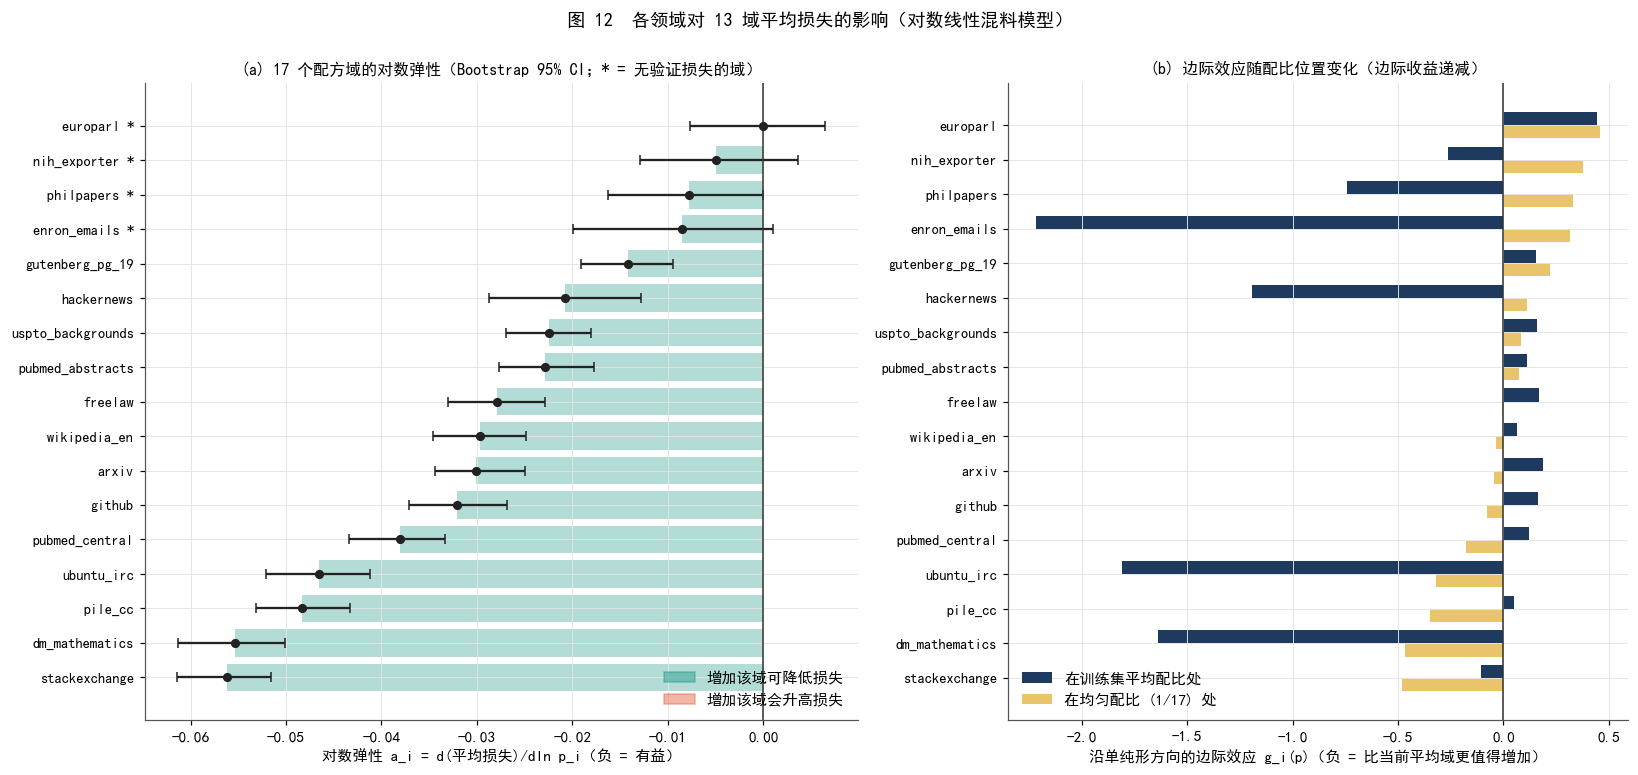

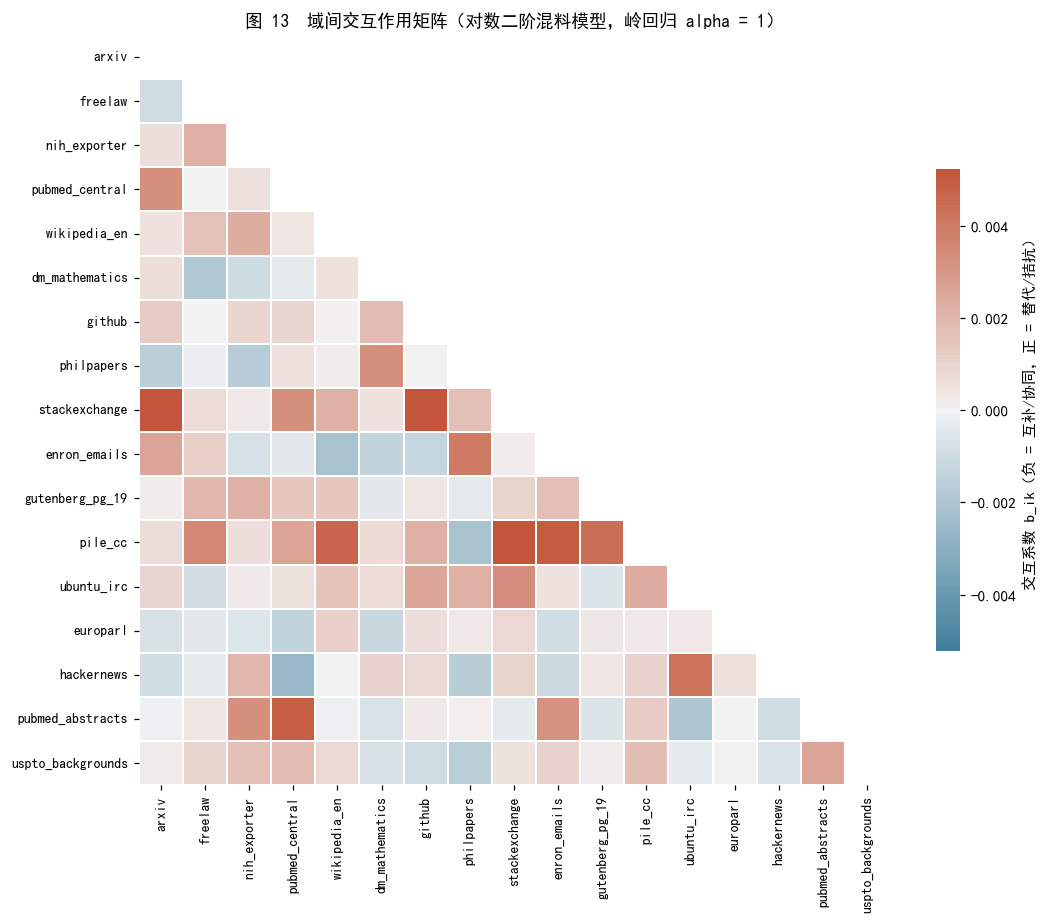

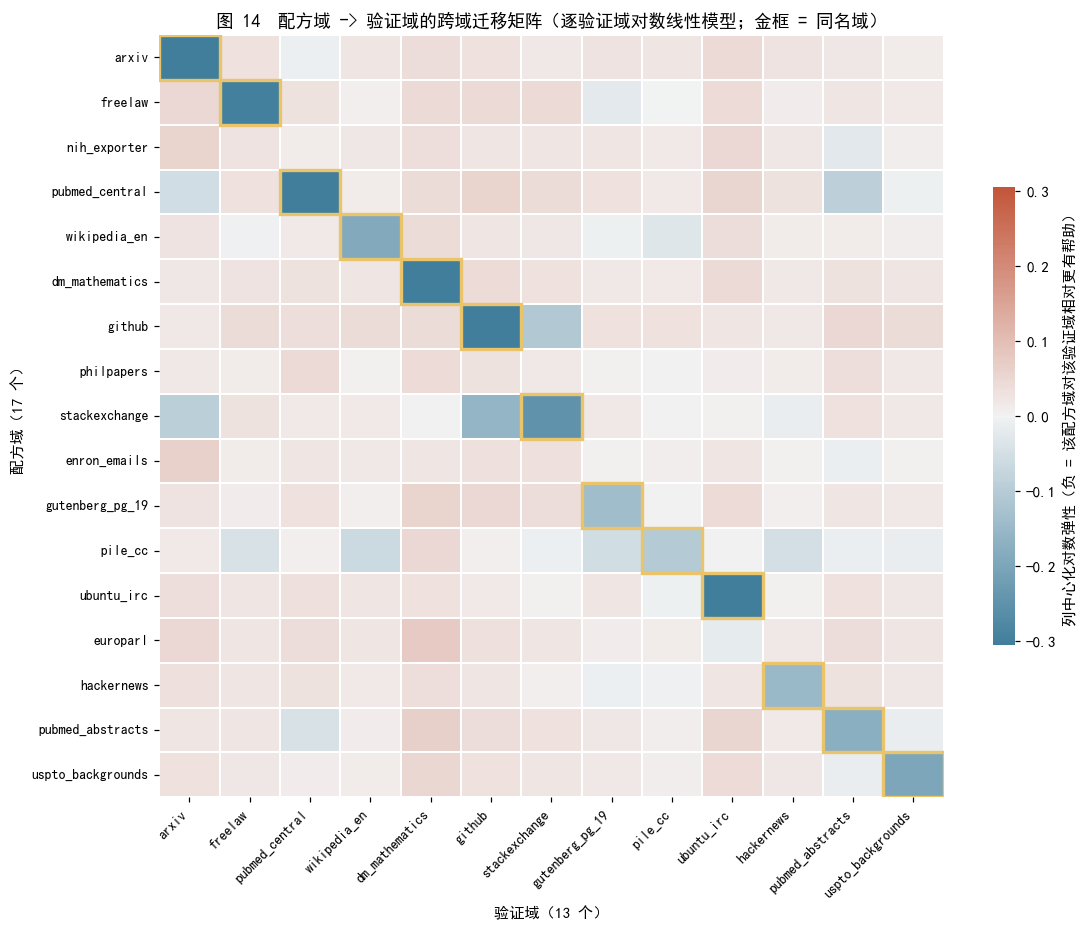

In [75]:
# ============ 3.2 对数弹性、边际效应、交互与迁移矩阵 ============
A_LOG = pd.Series(model_l.coef_, index=DOM17)
t0 = time.time(); B = 500; rng = np.random.default_rng(1); A_boot = np.zeros((B, 17))
Ztr = zlog(P_tr)
for b in range(B):
    idx = rng.integers(0, len(P_tr), len(P_tr)); A_boot[b] = LinearRegression().fit(Ztr[idx], y_tr[idx]).coef_
print('Bootstrap %d 次耗时 %.1fs' % (B, time.time() - t0))

def simplex_effect(a, p, eps=EPS_LOG):
    grad = a / (p + eps); return grad - (grad * p).sum()
p_mean = P_tr.mean(axis=0); uniform = np.ones(17) / 17
ME = pd.DataFrame({'对数弹性 a_i': A_LOG, 'CI低': np.percentile(A_boot, 2.5, axis=0), 'CI高': np.percentile(A_boot, 97.5, axis=0),
                   '边际效应@训练均值配比': simplex_effect(A_LOG.values, p_mean), '边际效应@均匀配比': simplex_effect(A_LOG.values, uniform),
                   '有验证损失': [d in VAL13 for d in DOM17], '训练集平均份额': p_mean}, index=DOM17).sort_values('对数弹性 a_i')
print('单域效应（负 = 增加该域可降低 13 域平均损失）:'); display(ME)
print('检验：p 加权的边际效应之和 = %.2e（理论值 0）' % (p_mean * ME.loc[DOM17, '边际效应@训练均值配比']).sum())
ME.to_csv(TAB / 'domain_marginal_effects.csv', encoding='utf-8-sig')

# 对数二阶模型的交互系数
coef = model_q.coef_
fn = PF.get_feature_names_out(DOM17) if hasattr(PF, 'get_feature_names_out') else PF.get_feature_names(DOM17)
B_INT = pd.DataFrame(0.0, index=DOM17, columns=DOM17)
for c, nm in zip(coef, fn):
    parts = nm.split(' ')
    if len(parts) == 2: B_INT.loc[parts[0], parts[1]] = c; B_INT.loc[parts[1], parts[0]] = c
pairs_int = pd.DataFrame([(a, b, B_INT.loc[a, b]) for a, b in itertools.combinations(DOM17, 2)], columns=['域i', '域k', 'b_ik']).sort_values('b_ik')
print('\n最强互补（b_ik 最负）6 对:'); display(pairs_int.head(6))
print('最强替代（b_ik 最正）6 对:'); display(pairs_int.tail(6).iloc[::-1])
pairs_int.to_csv(TAB / 'domain_interactions.csv', index=False, encoding='utf-8-sig')

# 跨域迁移矩阵（逐验证域对数线性模型）
T = np.zeros((17, 13)); R2v = {}
for v in range(13):
    m = LinearRegression().fit(Ztr, Y_tr[:, v]); T[:, v] = m.coef_; R2v[VAL13[v]] = m.score(Ztr, Y_tr[:, v])
TRANS = pd.DataFrame(T, index=DOM17, columns=VAL13); TRANS_C = TRANS - TRANS.mean(axis=0)
TRANS.to_csv(TAB / 'transfer_matrix.csv', encoding='utf-8-sig')
print('逐验证域对数线性模型的训练集 R2:', {k: round(v, 2) for k, v in R2v.items()})
diag_rank = {v: int(TRANS_C[v].rank().loc[v]) for v in VAL13 if v in DOM17}
print('同名域在各验证域列中的名次（1 = 最有帮助）:', diag_rank)

# ---- 图 12：对数弹性森林图 + 两种配比处的边际效应 ----
fig, axes = plt.subplots(1, 2, figsize=(15, 7), gridspec_kw={'width_ratios': [1.15, 1]})
ax = axes[0]; y = np.arange(len(ME))
cols = [C_TEAL if v < 0 else C_CORAL for v in ME['对数弹性 a_i']]
ax.barh(y, ME['对数弹性 a_i'], color=cols, alpha=0.35, edgecolor='none')
ax.errorbar(ME['对数弹性 a_i'], y, xerr=[ME['对数弹性 a_i'] - ME['CI低'], ME['CI高'] - ME['对数弹性 a_i']], fmt='o', color='#222222', ecolor='#222222', capsize=3, ms=5)
ax.axvline(0, color='#333333', lw=1)
ax.set_yticks(y); ax.set_yticklabels(['%s%s' % (d, '' if ok else ' *') for d, ok in zip(ME.index, ME['有验证损失'])], fontsize=9.5)
ax.set_xlabel('对数弹性 a_i = d(平均损失)/dln p_i（负 = 有益）'); ax.set_title('(a) 17 个配方域的对数弹性（Bootstrap 95% CI；* = 无验证损失的域）', fontsize=10.5)
ax.legend(handles=[Patch(color=C_TEAL, alpha=0.5, label='增加该域可降低损失'), Patch(color=C_CORAL, alpha=0.5, label='增加该域会升高损失')], frameon=False, loc='lower right')
ax = axes[1]; wbar = 0.38
ax.barh(y + wbar / 2, ME['边际效应@训练均值配比'], wbar, color=C_NAVY, label='在训练集平均配比处')
ax.barh(y - wbar / 2, ME['边际效应@均匀配比'], wbar, color=C_GOLD, label='在均匀配比 (1/17) 处')
ax.axvline(0, color='#333333', lw=1); ax.set_yticks(y); ax.set_yticklabels(ME.index, fontsize=9.5)
ax.set_xlabel('沿单纯形方向的边际效应 g_i(p)（负 = 比当前平均域更值得增加）'); ax.legend(frameon=False, loc='lower left'); ax.set_title('(b) 边际效应随配比位置变化（边际收益递减）', fontsize=10.5)
fig.suptitle('图 12  各领域对 13 域平均损失的影响（对数线性混料模型）', fontsize=12, y=1.0)
plt.tight_layout(); savefig('fig12_marginal_effects_forest.png'); plt.show()

# ---- 图 13：交互系数热力图 ----
mask = np.triu(np.ones_like(B_INT.values, dtype=bool))
vmax = np.nanpercentile(np.abs(B_INT.values[~mask]), 98)
fig, ax = plt.subplots(figsize=(11, 9.5))
sns.heatmap(B_INT, mask=mask, cmap=CMAP_DIV, center=0, vmin=-vmax, vmax=vmax, square=True, ax=ax, linewidths=0.3, linecolor='white', cbar_kws={'shrink': 0.6, 'label': '交互系数 b_ik（负 = 互补/协同，正 = 替代/拮抗）'})
ax.grid(False)
plt.setp(ax.get_xticklabels(), rotation=90, fontsize=9); plt.setp(ax.get_yticklabels(), fontsize=9)
ax.set_title('图 13  域间交互作用矩阵（对数二阶混料模型，岭回归 alpha = %.2g）' % model_q.alpha_, fontsize=11.5)
savefig('fig13_interaction_heatmap.png'); plt.show()

# ---- 图 14：跨域迁移矩阵 ----
fig, ax = plt.subplots(figsize=(11.5, 9))
vm = np.nanpercentile(np.abs(TRANS_C.values), 98)
sns.heatmap(TRANS_C, cmap=CMAP_DIV, center=0, vmin=-vm, vmax=vm, ax=ax, linewidths=0.3, linecolor='white', cbar_kws={'shrink': 0.6, 'label': '列中心化对数弹性（负 = 该配方域对该验证域相对更有帮助）'})
ax.grid(False)
for j, v in enumerate(VAL13):
    if v in DOM17:
        i = DOM17.index(v); ax.add_patch(Rectangle((j, i), 1, 1, fill=False, edgecolor=C_GOLD, lw=2.2))
ax.set_xlabel('验证域（13 个）'); ax.set_ylabel('配方域（17 个）'); plt.setp(ax.get_xticklabels(), rotation=45, ha='right', fontsize=9); plt.setp(ax.get_yticklabels(), fontsize=9)
ax.set_title('图 14  配方域 -> 验证域的跨域迁移矩阵（逐验证域对数线性模型；金框 = 同名域）', fontsize=11.5)
savefig('fig14_transfer_matrix.png'); plt.show()

### 3.3 外推表 A12–A15 上的稳健性讨论

A12–A15 给出训练集中 63 个配比在 10B/70B 尺度上依据 1M、60M、1B 数据拟合幂律 $L(N)=E+AN^{-\alpha}$ 后得到的损失，属于外推估计。跨尺度比较须先匹配相同配比：1M 与 60M 检验集有 256 个相同配比，平均损失排序 Spearman 为 0.9658；1B 检验配比与这两组均无相同向量，不能计算直接配对相关。

63 个相同训练配比的 1M 实测损失与 10B、70B 外推损失的平均排序相关分别为 −0.739、−0.814；10B 与 70B 外推表之间为 0.990。逐验证域比较的 1M–10B Spearman 中位数为 0.623，显示平均目标和各域目标的排序变化不同。SCM、SCI 等模型在 10B/70B 外推表上的负相关是对外推结果的检验，不代表真实大模型训练后的排序。外推表的损失标准差由 1M 的约 0.377 缩至 10B 的约 0.096，结论应作为尺度敏感性分析使用。


63 个配比的平均损失在不同尺度间的 Spearman 相关:
  1M实测 vs 10B外推 = -0.739   1M实测 vs 70B外推 = -0.814   10B vs 70B = 0.990
  1M实测 与 (10B外推 - 1M实测) 的 Spearman = -0.987  -> 1M 损失越高的配比被外推压得越低
  损失标准差: 1M 0.377 -> 10B 0.096 -> 70B 0.104


,数据集,n,性质,对数线性 Spearman,GBM Spearman
0,1M 检验集 (A6/A7),256,实测,0.9316,0.9671
1,60M 检验集 (A8/A9),256,实测,0.9116,0.9301
2,1B 检验集 (A10/A11),64,实测,0.7548,0.7211
3,10B 外推表 (A12/A13),63,幂律外推,-0.6870,-0.7285
4,70B 外推表 (A14/A15),63,幂律外推,-0.7613,-0.8038


逐验证域 1M 实测 vs 10B 外推的 Spearman（中位数 0.62）:
hackernews          0.0190
pile_cc             0.0960
wikipedia_en        0.3290
pubmed_abstracts    0.4100
gutenberg_pg_19     0.4220
uspto_backgrounds   0.4510
ubuntu_irc          0.6230
stackexchange       0.6380
freelaw             0.7530
pubmed_central      0.7610
github              0.8080
dm_mathematics      0.8290
arxiv               0.8670

固定 SCM 的局部边际效应排序与 1M 训练集的 Spearman:
1M 训练(512)   1.0000
1M           0.9630
60M          0.9630
1B           0.6760
10B          0.9240
70B          0.9240


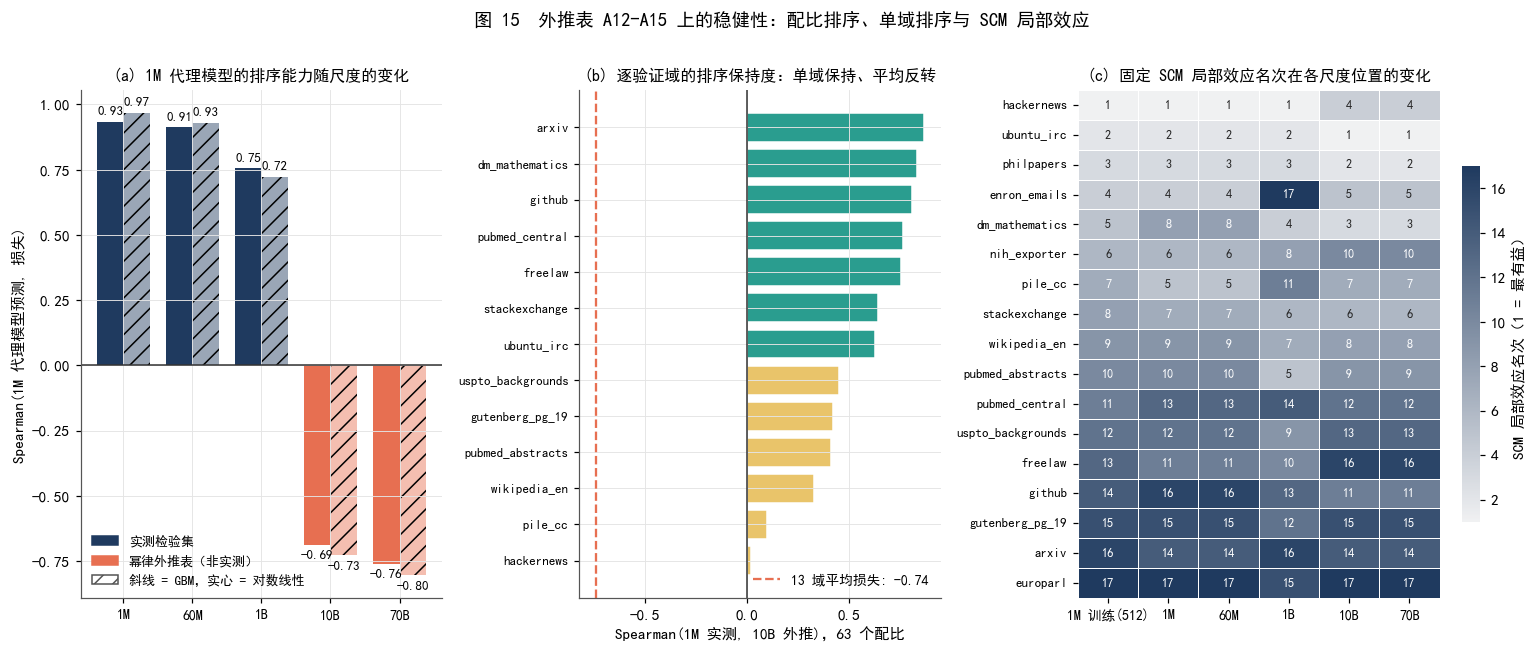

In [76]:
# ============ 3.3 外推稳健性 ============
TRi = TR.set_index('index'); e10 = ESTS['10B 外推表 (A12/A13)'][0].set_index('index'); e70 = ESTS['70B 外推表 (A14/A15)'][0].set_index('index')
idx63 = e10.index
L1 = TRi.loc[idx63, LOSS_COLS].mean(axis=1).values; L10 = e10[LOSS_COLS].mean(axis=1).values; L70 = e70[LOSS_COLS].mean(axis=1).values
print('63 个配比的平均损失在不同尺度间的 Spearman 相关:')
print('  1M实测 vs 10B外推 = %.3f   1M实测 vs 70B外推 = %.3f   10B vs 70B = %.3f' % (stats.spearmanr(L1, L10)[0], stats.spearmanr(L1, L70)[0], stats.spearmanr(L10, L70)[0]))
print('  1M实测 与 (10B外推 - 1M实测) 的 Spearman = %.3f  -> 1M 损失越高的配比被外推压得越低' % stats.spearmanr(L1, L10 - L1)[0])
print('  损失标准差: 1M %.3f -> 10B %.3f -> 70B %.3f' % (L1.std(), L10.std(), L70.std()))

scale_rows = []
for tn, (df, P, Y, _, _) in list(TESTS.items()) + list(ESTS.items()):
    scale_rows.append({'数据集': tn, 'n': len(df), '性质': '实测' if '检验' in tn else '幂律外推',
                       '对数线性 Spearman': stats.spearmanr(pred_log(P), Y.mean(axis=1))[0], 'GBM Spearman': stats.spearmanr(pred_gbm(P), Y.mean(axis=1))[0]})
SCALE = pd.DataFrame(scale_rows); display(SCALE)

per_dom = pd.Series({v: stats.spearmanr(TRi.loc[idx63, c], e10[c])[0] for v, c in zip(VAL13, LOSS_COLS)}).sort_values()
print('逐验证域 1M 实测 vs 10B 外推的 Spearman（中位数 %.2f）:' % per_dom.median()); print(per_dom.round(3).to_string())

def scm_gradient_at(p):
    """Evaluate fixed A4/A5 SCM gradient at one mixture without refitting."""
    z = np.log(p + STRUCT_EPS)
    b = struct_model.coef_
    return (b[:17] + 2 * b[17:34] * z) / (p + STRUCT_EPS) + b[34:51]
AV = pd.DataFrame({'1M 训练(512)': scm_gradient_at(P_tr.mean(axis=0))}, index=DOM17)
for tn, (df, P, Y, _, _) in list(TESTS.items()) + list(ESTS.items()):
    AV[tn.split(' ')[0]] = scm_gradient_at(P.mean(axis=0))
AV_rank = AV.rank()
print('\n固定 SCM 的局部边际效应排序与 1M 训练集的 Spearman:'); print(AV.corr(method='spearman').iloc[0].round(3).to_string())
AV.to_csv(TAB / 'scm_local_effect_by_scale.csv', encoding='utf-8-sig')

# ---- 图 15 ----
fig = plt.figure(figsize=(17, 6))
gs = gridspec.GridSpec(1, 3, width_ratios=[1, 1, 1.25], wspace=0.35)
ax = fig.add_subplot(gs[0]); xb = np.arange(len(SCALE)); wbar = 0.38
ax.bar(xb - wbar / 2, SCALE['对数线性 Spearman'], wbar, color=[C_NAVY if s == '实测' else C_CORAL for s in SCALE['性质']], label='对数线性主模型')
ax.bar(xb + wbar / 2, SCALE['GBM Spearman'], wbar, color=[C_NAVY if s == '实测' else C_CORAL for s in SCALE['性质']], alpha=0.45, hatch='//', label='GBM')
for i, (v1, v2) in enumerate(zip(SCALE['对数线性 Spearman'], SCALE['GBM Spearman'])):
    ax.text(i - wbar / 2, v1 + (0.02 if v1 >= 0 else -0.02), '%.2f' % v1, ha='center', va='bottom' if v1 >= 0 else 'top', fontsize=8.5)
    ax.text(i + wbar / 2, v2 + (0.02 if v2 >= 0 else -0.02), '%.2f' % v2, ha='center', va='bottom' if v2 >= 0 else 'top', fontsize=8.5)
ax.axhline(0, color='#333333', lw=1); ax.set_xticks(xb); ax.set_xticklabels([s.split(' ')[0] for s in SCALE['数据集']], fontsize=9)
ax.set_ylabel('Spearman(1M 代理模型预测, 损失)'); ax.set_title('(a) 1M 代理模型的排序能力随尺度的变化', fontsize=10.5)
ax.legend(handles=[Patch(color=C_NAVY, label='实测检验集'), Patch(color=C_CORAL, label='幂律外推表（非实测）'), Patch(facecolor='white', edgecolor='#555555', hatch='//', label='斜线 = GBM，实心 = 对数线性')], frameon=False, loc='lower left', fontsize=8.5)
ax = fig.add_subplot(gs[1])
ax.barh(per_dom.index, per_dom.values, color=[C_TEAL if v > 0.5 else (C_GOLD if v > 0 else C_CORAL) for v in per_dom.values], edgecolor='white')
ax.axvline(stats.spearmanr(L1, L10)[0], color=C_CORAL, ls='--', lw=1.5, label='13 域平均损失: %.2f' % stats.spearmanr(L1, L10)[0])
ax.axvline(0, color='#333333', lw=1); ax.set_xlabel('Spearman(1M 实测, 10B 外推)，63 个配比'); ax.tick_params(axis='y', labelsize=8.5); ax.legend(frameon=False, loc='lower right', fontsize=9)
ax.set_title('(b) 逐验证域的排序保持度：单域保持、平均反转', fontsize=10.5)
ax = fig.add_subplot(gs[2])
sns.heatmap(AV_rank.loc[AV_rank['1M 训练(512)'].sort_values().index], cmap=CMAP_SEQ, annot=True, fmt='.0f', ax=ax, cbar_kws={'shrink': 0.7, 'label': 'SCM 局部效应名次（1 = 最有益）'}, linewidths=0.4, linecolor='white', annot_kws={'size': 8})
ax.grid(False)
ax.set_title('(c) 固定 SCM 局部效应名次在各尺度位置的变化', fontsize=10.5); ax.set_xlabel(''); plt.setp(ax.get_xticklabels(), rotation=0, fontsize=9); plt.setp(ax.get_yticklabels(), fontsize=8.5)
fig.suptitle('图 15  外推表 A12-A15 上的稳健性：配比排序、单域排序与 SCM 局部效应', fontsize=12, y=1.0)
savefig('fig15_extrapolation_robustness.png'); plt.show()

### 3.4 是否以及如何将质量评分 $Q$ 引入配比模型

**可识别性论证。**在固定的 17 域集合上，每个领域的 $Q_i$ 不随配比实验变化。若只在对数线性模型中将 $D_i^{eff}=Dp_i\phi(Q_i)$ 代入 $\log D_i^{eff}$，质量项 $\log\phi(Q_i)$ 与常数项混合，无法从这组实验中单独估计质量的因果系数。不过，$\bar Q(\mathbf p)=\sum_i p_iQ_i$ 随配比变化，可以检验它是否提供额外的预测信息；这种检验仍不能将质量与领域身份、语料内容的作用分开。本文因而同时考察 $Q_i$ 与领域响应系数的关联、$\bar Q(\mathbf p)$ 的单变量解释力及加入代理模型后的增量表现。

**跨体系映射**（A16）。7 个质量域与 17 个配方域不一一对应。按映射置信度给配方域 $i$ 赋值：
$$Q_i=\kappa_{m(i)}\,Q_{d(i)}+\big(1-\kappa_{m(i)}\big)\,\bar Q,\qquad \kappa_{direct}=1,\ \kappa_{near\_direct}=0.8,\ \kappa_{inferred}=0.5,$$
其中 $d(i)$ 是 A16 给出的质量域，$\bar Q$ 是 7 个质量域 $Q^{res}$ 的均值（无信息先验），映射越不确定，$Q_i$ 越向均值收缩；A16 标为 `(none)` 的 11 个域没有对应质量域，取 $Q_i=\bar Q$。arxiv 与 github 采用 **抽样 + 扩展合并全量** 的 $Q^{res}$（题目要求的全量口径）。

**本次三项检验**：
1. **域效应 vs 质量**：在 6 个有映射的域上计算对数弹性 $a_i$ 与 $Q_i$ 的 Spearman / Pearson 相关，记录相关方向及其不确定性；
2. **配比级质量指数**：定义配比的加权平均质量 $\bar Q(\mathbf p)=\sum_i p_i Q_i$，用单变量模型 $\bar L=c_0+c_1\bar Q(\mathbf p)$ 在训练集和检验集上的 $R^2$ / Spearman 衡量"一个质量标量能解释多少配比效应"；
3. **增量信息**：把 $\bar Q(\mathbf p)$ 作为附加特征加入主模型，看检验集 Spearman 是否提升。A4/A5 上 $\bar Q(\mathbf p)$ 单变量训练 $R^2=0.0010$；有映射的 6 个域中，$Q_i$ 与对数线性模型系数的 Spearman 为 −0.314（$p=0.54$）。将 $\bar Q(\mathbf p)$ 加入对数线性代理模型后，三个固定检验集的 Spearman 增量仅为 0.0005/0.0006/0.0016。第 7 节再用训练集内部交叉验证选择质量调整份额指数 $\eta$。这些检验用于判断固定质量分是否改善预测，不能识别质量的独立因果效应。

**对数线性模型的解析最优配比**。对数线性模型下的约束最优配比 $\mathbf p^\star=\arg\min_{\mathbf p\in\Delta}\hat{\bar L}(\mathbf p)$ 有 KKT 解析解：令 $\lambda$ 为单纯形约束的乘子，$\partial/\partial p_i$ 得 $a_i/(p_i+\varepsilon)+\lambda=0$，故
$$p^\star_i=\max\Big(0,\ \frac{-a_i}{\lambda}-\varepsilon\Big),\qquad \lambda\ \text{由}\ \sum_i p^\star_i=1\ \text{确定},$$
即 **最优份额与对数弹性的绝对值近似成正比**。用 SLSQP 数值验证解析解，并用 GBM 独立评估 $\mathbf p^\star$ 的预测损失、与 GBM 随机搜索最优解对照。两个代理模型的最优解不一致，反映推荐对代理模型形式敏感；为此再给出 **模型平均稳健最优** $\mathbf p^{rob}$：在 $5\times10^4$ 个 Dirichlet 候选（含两个模型各自的最优解）中取两模型预测损失名次之和最小者（Borda 平均），作为传递给问题二、三的配比接口（$\mathbf p^{rob}$ 与 $\bar Q(\mathbf p^{rob})$）。

7 个质量域的 Q_res（arxiv/github 为合并全量）: {'arxiv': 0.7953, 'book': 0.6078, 'c4': 0.5903, 'commoncrawl': 0.6155, 'github': 0.5171, 'stackexchange': 0.645, 'wikipedia': 0.5248}  均值 0.6137


,quality_domain,mapping_type,kappa,Q_quality_domain,Q_i
mixture_domain,,,,,
arxiv,arxiv,direct,1.0000,0.7953,0.7953
github,github,direct,1.0000,0.5171,0.5171
stackexchange,stackexchange,direct,1.0000,0.6450,0.6450
wikipedia_en,wikipedia,near_direct,0.8000,0.5248,0.5426
gutenberg_pg_19,book,near_direct,0.8000,0.6078,0.6090
pile_cc,commoncrawl,near_direct,0.8000,0.6155,0.6151
dm_mathematics,(none),inferred,0.5000,NaN,0.6137
freelaw,(none),inferred,0.5000,NaN,0.6137
nih_exporter,(none),inferred,0.5000,NaN,0.6137



(1) 有映射的 6 个域：对数弹性 a_i vs Q_i 的 Spearman = -0.314 (p = 0.54), Pearson = -0.075
    对照：a_i 与同名域自迁移强度 TRANS_C[i,i] 的 Spearman = 0.505（13 个域）

(2) 单变量模型 L = c0 + c1 * Qbar(p) 的解释力（c1 = 0.223；60M/1B 因损失水平不同只看 Spearman）:


,数据集,n,R2(仅Qbar),"Spearman(Qbar, 损失)"
0,1M 训练集,512,0.0010,-0.0180
1,1M 检验集 (A6/A7),256,-0.0479,-0.0864
2,60M 检验集 (A8/A9),256,NaN,-0.0906
3,1B 检验集 (A10/A11),64,NaN,0.2936



(3) 把 Qbar(p) 加入主模型的增量信息（Qbar 系数 = 0.152）:


,检验集,对数线性(p) Spearman,对数线性(p)+Qbar Spearman,提升
0,1M 检验集 (A6/A7),0.9316,0.9321,0.0005
1,60M 检验集 (A8/A9),0.9116,0.9122,0.0006
2,1B 检验集 (A10/A11),0.7548,0.7563,0.0016



KKT 解析解与 SLSQP 数值解的最大差异 = 0.00e+00，目标值 4.3050 / 4.3050
各配比在两个代理模型下的预测损失（训练集实测最小损失 4.753）:


,配比,对数线性预测损失,GBM 预测损失,Qbar(p)
0,对数线性最优 p*,4.3050,4.7441,0.6181
1,GBM 随机搜索最优,4.5827,4.6906,0.6272
2,模型平均稳健最优 p_rob,4.3926,4.7167,0.6171
3,训练集最好配比,4.5932,4.7793,0.6058
4,训练集平均配比,4.4339,4.7638,0.6212
5,均匀配比 1/17,4.4069,4.7443,0.6162


对数线性最优 p* 与 GBM 最优配比的 Spearman = 0.292；p_rob 与二者的 Spearman = 0.642 / 0.306


,最优配比 p* (对数线性),GBM 搜索最优,模型平均稳健最优 p_rob,训练集平均配比,均匀配比,对数弹性 a_i,Q_i
pile_cc,0.1044,0.0218,0.1625,0.1195,0.0588,-0.0483,0.6151
stackexchange,0.1215,0.2445,0.1162,0.0994,0.0588,-0.0562,0.6450
freelaw,0.0598,0.0466,0.1136,0.0968,0.0588,-0.0279,0.6137
uspto_backgrounds,0.0480,0.0049,0.1068,0.0756,0.0588,-0.0225,0.6137
ubuntu_irc,0.1005,0.0164,0.0884,0.0196,0.0588,-0.0465,0.6137
pubmed_central,0.0820,0.1439,0.0618,0.1138,0.0588,-0.0381,0.6137
philpapers,0.0159,0.0590,0.0585,0.0055,0.0588,-0.0077,0.6137
wikipedia_en,0.0637,0.1068,0.0440,0.0751,0.0588,-0.0297,0.5426
dm_mathematics,0.1197,0.0253,0.0402,0.0255,0.0588,-0.0553,0.6137
hackernews,0.0444,0.0942,0.0366,0.0117,0.0588,-0.0208,0.6137


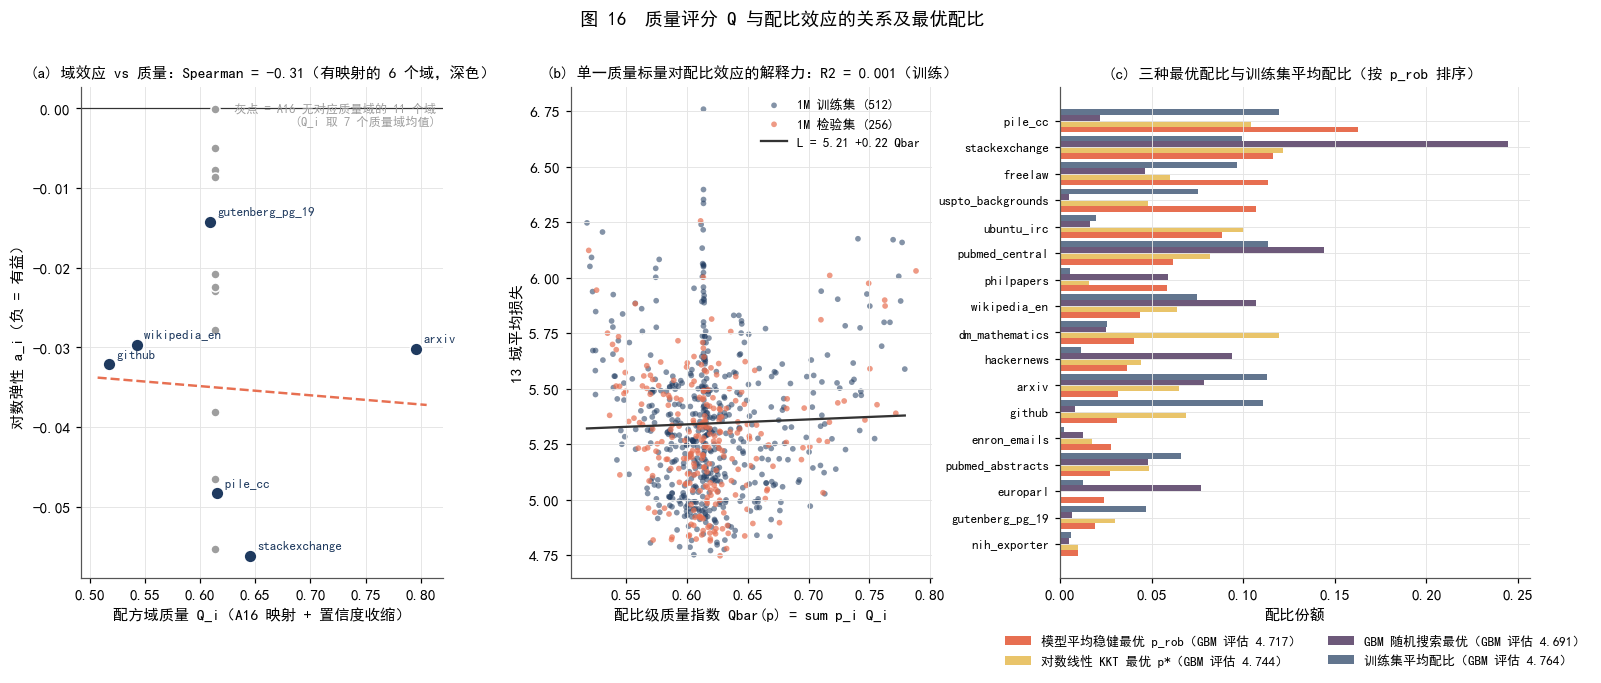


已保存问题二/三原版质量接口文件: D:\华为杯研究生建模资料\第二十三届中国研究生数学建模竞赛 - 中文题目\中文题目\F题\解题思路\问题一_最终整合结果\tables\q1_outputs_for_q2_q3.json


In [77]:
# ============ 3.4 引入 Q 的论证 + 最优配比 ============
MAP = pd.read_csv(DATA / 'domain_mapping_guide.csv')
Qd = DOMAIN_Q[DOMAIN_Q['数据集'] == 'A1 抽样集'].set_index('域')['Q_res_doc均值'].to_dict()
Qd.update(DOMAIN_Q[DOMAIN_Q['数据集'] == '抽样+扩展 合并全量(按ID去重)'].set_index('域')['Q_res_doc均值'].to_dict())   # arxiv/github 用全量
Q_BAR = float(np.mean(list(Qd.values())))
KAPPA = {'direct': 1.0, 'near_direct': 0.8, 'inferred': 0.5}
Qi = {}
for _, r in MAP.iterrows():
    qd = Qd.get(str(r['quality_domain']).strip()); k_ = KAPPA.get(r['mapping_type'], 0.5)
    Qi[r['mixture_domain']] = k_ * qd + (1 - k_) * Q_BAR if qd is not None else Q_BAR
Q17 = pd.Series([Qi.get(d, Q_BAR) for d in DOM17], index=DOM17)
QMAP = MAP.set_index('mixture_domain').assign(Q_quality_domain=[Qd.get(str(q).strip(), np.nan) for q in MAP['quality_domain']], kappa=[KAPPA.get(t, 0.5) for t in MAP['mapping_type']], Q_i=[Qi[m] for m in MAP['mixture_domain']])
print('7 个质量域的 Q_res（arxiv/github 为合并全量）:', {k: round(v, 4) for k, v in Qd.items()}, ' 均值 %.4f' % Q_BAR)
display(QMAP[['quality_domain', 'mapping_type', 'kappa', 'Q_quality_domain', 'Q_i']])

# (1) 域效应 vs 质量
mapped = [d for d in DOM17 if str(QMAP.loc[d, 'quality_domain']).strip() != '(none)']
a_m = A_LOG[mapped]; q_m = Q17[mapped]
print('\n(1) 有映射的 %d 个域：对数弹性 a_i vs Q_i 的 Spearman = %.3f (p = %.2f), Pearson = %.3f' % (len(mapped), stats.spearmanr(a_m, q_m)[0], stats.spearmanr(a_m, q_m)[1], stats.pearsonr(a_m, q_m)[0]))
# 对照：域效应能否被"与验证集的分布匹配"解释 —— 同名域自迁移强度
self_tr = pd.Series({d: TRANS_C.loc[d, d] for d in DOM17 if d in VAL13})
print('    对照：a_i 与同名域自迁移强度 TRANS_C[i,i] 的 Spearman = %.3f（%d 个域）' % (stats.spearmanr(A_LOG[self_tr.index], self_tr)[0], len(self_tr)))

# (2) 配比级质量指数
Qbar_tr = P_tr @ Q17.values
lin_q = LinearRegression().fit(Qbar_tr.reshape(-1, 1), y_tr)
r2_rows = [{'数据集': '1M 训练集', 'n': len(y_tr), 'R2(仅Qbar)': lin_q.score(Qbar_tr.reshape(-1, 1), y_tr), 'Spearman(Qbar, 损失)': stats.spearmanr(Qbar_tr, y_tr)[0]}]
for tn, (df, P, Y, _, _) in TESTS.items():
    qb = P @ Q17.values; r2_rows.append({'数据集': tn, 'n': len(df), 'R2(仅Qbar)': lin_q.score(qb.reshape(-1, 1), Y.mean(axis=1)) if '1M' in tn else np.nan, 'Spearman(Qbar, 损失)': stats.spearmanr(qb, Y.mean(axis=1))[0]})
R2Q = pd.DataFrame(r2_rows); print('\n(2) 单变量模型 L = c0 + c1 * Qbar(p) 的解释力（c1 = %.3f；60M/1B 因损失水平不同只看 Spearman）:' % lin_q.coef_[0]); display(R2Q)

# (3) 增量信息：主模型 + Qbar 特征
aug_rows = []
m_aug = LinearRegression().fit(np.column_stack([Ztr, Qbar_tr]), y_tr)
for tn, (df, P, Y, _, _) in TESTS.items():
    base_rho = stats.spearmanr(pred_log(P), Y.mean(axis=1))[0]
    aug_rho = stats.spearmanr(m_aug.predict(np.column_stack([zlog(P), P @ Q17.values])), Y.mean(axis=1))[0]
    aug_rows.append({'检验集': tn, '对数线性(p) Spearman': base_rho, '对数线性(p)+Qbar Spearman': aug_rho, '提升': aug_rho - base_rho})
AUG = pd.DataFrame(aug_rows); print('\n(3) 把 Qbar(p) 加入主模型的增量信息（Qbar 系数 = %.3f）:' % m_aug.coef_[-1]); display(AUG)

# ---- 最优配比：KKT 解析解 + SLSQP 验证 + GBM 交叉评估 ----
a = A_LOG.values
def p_closed(lam):
    return np.maximum(0.0, -a / lam - EPS_LOG)
lo_l, hi_l = 1e-6, 1e3
for _ in range(200):
    mid = np.sqrt(lo_l * hi_l)
    if p_closed(mid).sum() > 1: lo_l = mid
    else: hi_l = mid
p_kkt = p_closed(np.sqrt(lo_l * hi_l)); p_kkt = p_kkt / p_kkt.sum()
obj = lambda p: model_l.predict(zlog(p.reshape(1, -1)))[0]
res = minimize(obj, p_kkt, method='SLSQP', bounds=[(0, 1)] * 17, constraints=[{'type': 'eq', 'fun': lambda p: p.sum() - 1}], options={'maxiter': 500, 'ftol': 1e-12})
p_num = np.clip(res.x, 0, 1); p_num = p_num / p_num.sum()
print('\nKKT 解析解与 SLSQP 数值解的最大差异 = %.2e，目标值 %.4f / %.4f' % (np.abs(p_kkt - p_num).max(), obj(p_kkt), obj(p_num)))
p_star = p_kkt
# GBM 随机搜索最优（在训练配比范围内）
lo_b, hi_b = P_tr.min(axis=0), P_tr.max(axis=0)
cand = np.clip(RNG.dirichlet(np.ones(17) * 0.7, size=50000), lo_b, hi_b); cand = cand / cand.sum(axis=1, keepdims=True); cand = np.vstack([cand, P_tr, p_star.reshape(1, -1)])
Lc = pred_gbm(cand); p_gbm = cand[np.argmin(Lc)]
# 稳健最优：两个代理模型各自对候选排名，取平均名次最小的候选（Borda 模型平均，抑制单一代理模型的外推偏差）
Ll = model_l.predict(zlog(cand)); rk = stats.rankdata(Ll) + stats.rankdata(Lc)
p_rob = cand[np.argmin(rk)]
CANDS = [('对数线性最优 p*', p_star), ('GBM 随机搜索最优', p_gbm), ('模型平均稳健最优 p_rob', p_rob), ('训练集最好配比', P_tr[np.argmin(y_tr)]), ('训练集平均配比', p_mean), ('均匀配比 1/17', uniform)]
CMP = pd.DataFrame({'配比': [n for n, _ in CANDS], '对数线性预测损失': [obj(p) for _, p in CANDS],
                    'GBM 预测损失': [pred_gbm(p.reshape(1, -1))[0] for _, p in CANDS], 'Qbar(p)': [p @ Q17.values for _, p in CANDS]})
print('各配比在两个代理模型下的预测损失（训练集实测最小损失 %.3f）:' % y_tr.min()); display(CMP)
print('对数线性最优 p* 与 GBM 最优配比的 Spearman = %.3f；p_rob 与二者的 Spearman = %.3f / %.3f' % (stats.spearmanr(p_star, p_gbm)[0], stats.spearmanr(p_rob, p_star)[0], stats.spearmanr(p_rob, p_gbm)[0]))
OPT = pd.DataFrame({'最优配比 p* (对数线性)': p_star, 'GBM 搜索最优': p_gbm, '模型平均稳健最优 p_rob': p_rob, '训练集平均配比': p_mean, '均匀配比': uniform, '对数弹性 a_i': a, 'Q_i': Q17.values}, index=DOM17).sort_values('模型平均稳健最优 p_rob', ascending=False)
display(OPT)

# ---- 图 16 ----
fig = plt.figure(figsize=(17, 5.8))
gs = gridspec.GridSpec(1, 3, width_ratios=[1, 1, 1.3], wspace=0.32)
ax = fig.add_subplot(gs[0])
for d in DOM17:
    is_m = d in mapped
    ax.scatter(Q17[d], A_LOG[d], s=70 if is_m else 35, color=C_NAVY if is_m else C_GREY, edgecolor='white', zorder=3)
    if is_m: ax.annotate(d, (Q17[d], A_LOG[d]), xytext=(5, 4), textcoords='offset points', fontsize=8.5, color=C_NAVY)
ax.text(0.98, 0.97, '灰点 = A16 无对应质量域的 11 个域\n(Q_i 取 7 个质量域均值)', transform=ax.transAxes, fontsize=8, color=C_GREY, ha='right', va='top')
a_, b_ = np.polyfit(q_m, a_m, 1); xs = np.linspace(q_m.min() - 0.01, q_m.max() + 0.01, 20); ax.plot(xs, a_ * xs + b_, color=C_CORAL, lw=1.6, ls='--')
ax.axhline(0, color='#333333', lw=0.8); ax.set_xlabel('配方域质量 Q_i（A16 映射 + 置信度收缩）'); ax.set_ylabel('对数弹性 a_i（负 = 有益）')
ax.set_title('(a) 域效应 vs 质量：Spearman = %.2f（有映射的 %d 个域，深色）' % (stats.spearmanr(a_m, q_m)[0], len(mapped)), fontsize=10)
ax = fig.add_subplot(gs[1])
ax.scatter(Qbar_tr, y_tr, s=14, color=C_NAVY, alpha=0.55, edgecolor='none', label='1M 训练集 (512)')
P1m = TESTS['1M 检验集 (A6/A7)'][1]; Y1m = TESTS['1M 检验集 (A6/A7)'][2].mean(axis=1)
ax.scatter(P1m @ Q17.values, Y1m, s=14, color=C_CORAL, alpha=0.7, edgecolor='none', label='1M 检验集 (256)')
xs = np.linspace(Qbar_tr.min(), Qbar_tr.max(), 20); ax.plot(xs, lin_q.predict(xs.reshape(-1, 1)), color='#333333', lw=1.5, label='L = %.2f %+.2f Qbar' % (lin_q.intercept_, lin_q.coef_[0]))
ax.set_xlabel('配比级质量指数 Qbar(p) = sum p_i Q_i'); ax.set_ylabel('13 域平均损失'); ax.legend(frameon=False, fontsize=8.5)
ax.set_title('(b) 单一质量标量对配比效应的解释力：R2 = %.3f（训练）' % R2Q['R2(仅Qbar)'][0], fontsize=10)
ax = fig.add_subplot(gs[2])
y = np.arange(len(OPT)); wbar = 0.22
ax.barh(y + 1.5 * wbar, OPT['模型平均稳健最优 p_rob'], wbar, color=C_CORAL, label='模型平均稳健最优 p_rob（GBM 评估 %.3f）' % CMP['GBM 预测损失'][2])
ax.barh(y + 0.5 * wbar, OPT['最优配比 p* (对数线性)'], wbar, color=C_GOLD, label='对数线性 KKT 最优 p*（GBM 评估 %.3f）' % CMP['GBM 预测损失'][0])
ax.barh(y - 0.5 * wbar, OPT['GBM 搜索最优'], wbar, color=C_PLUM, label='GBM 随机搜索最优（GBM 评估 %.3f）' % CMP['GBM 预测损失'][1])
ax.barh(y - 1.5 * wbar, OPT['训练集平均配比'], wbar, color=C_NAVY, alpha=0.7, label='训练集平均配比（GBM 评估 %.3f）' % CMP['GBM 预测损失'][4])
ax.set_yticks(y); ax.set_yticklabels(OPT.index, fontsize=8.5); ax.invert_yaxis(); ax.set_xlabel('配比份额'); ax.legend(frameon=False, fontsize=8.5, loc='upper center', bbox_to_anchor=(0.5, -0.09), ncol=2)
ax.set_title('(c) 三种最优配比与训练集平均配比（按 p_rob 排序）', fontsize=10)
fig.suptitle('图 16  质量评分 Q 与配比效应的关系及最优配比', fontsize=12, y=1.0)
savefig('fig16_Q_and_optimal_mixture.png'); plt.show()

# ---- 保存给问题二 / 三的接口文件 ----
OPT.to_csv(TAB / 'optimal_mixture.csv', encoding='utf-8-sig')
Q17.rename('Q_i').to_csv(TAB / 'mixture_domain_Q.csv', encoding='utf-8-sig')
handoff = {'quality_domain_Q_res': {k: float(v) for k, v in Qd.items()}, 'Q_bar_global': Q_BAR, 'mixture_domain_Q': {d: float(Q17[d]) for d in DOM17},
           'kappa': KAPPA, 'dimension_weights': {d: float(W_DIM[d]) for d in DIMS}, 'indicator_weights': {j: float(W.loc[j, '组合权重']) for j in INDICATORS},
           'log_linear_model': {'intercept': float(model_l.intercept_), 'epsilon': EPS_LOG, 'a_i': {d: float(A_LOG[d]) for d in DOM17}},
           'p_star_loglinear': {d: float(v) for d, v in zip(DOM17, p_star)}, 'p_star_gbm': {d: float(v) for d, v in zip(DOM17, p_gbm)},
           'p_star': {d: float(v) for d, v in zip(DOM17, p_rob)}, 'p_star_note': 'p_star = 模型平均稳健最优 p_rob（对数线性与 GBM 预测损失名次之和最小）',
           'L_hat_p_star_loglinear': float(obj(p_rob)), 'L_hat_p_star_gbm': float(CMP['GBM 预测损失'][2]),
           'Qbar_p_star': float(p_rob @ Q17.values), 'train_mixture_Qbar': [float(v) for v in Qbar_tr],
           # 各尺度配比实验的 13 域平均损失统计（供问题二检验“配比效应随尺度的变化”假设；不需要再读附件 A）
           'regmix_scale_stats': dict([('1M 训练集', {'N_params': 1e6, 'n': int(len(y_tr)), 'mean': float(y_tr.mean()), 'std': float(y_tr.std()), 'min': float(y_tr.min()), 'max': float(y_tr.max())})] +
                                      [(tn.split(' ')[0], {'N_params': {'1M': 1e6, '60M': 6e7, '1B': 1e9}[tn.split(' ')[0]], 'n': int(len(df)), 'mean': float(Y.mean(axis=1).mean()), 'std': float(Y.mean(axis=1).std()), 'min': float(Y.mean(axis=1).min()), 'max': float(Y.mean(axis=1).max())}) for tn, (df, P, Y, _, _) in TESTS.items()]),
           'mixture_loss_loglinear': {'p_rob': float(obj(p_rob)), 'p_star_loglinear': float(obj(p_star)), 'uniform': float(obj(uniform)), 'train_mean_mixture': float(obj(p_mean)), 'train_min_observed': float(y_tr.min()), 'train_max_observed': float(y_tr.max())},
           'train_mixture_loss_hat': [float(v) for v in model_l.predict(Ztr)], 'domain_order': DOM17}
with open(TAB / 'q1_outputs_for_q2_q3.json', 'w', encoding='utf-8') as f:
    json.dump(handoff, f, ensure_ascii=False, indent=2)
print('\n已保存问题二/三原版质量接口文件: %s' % (TAB / 'q1_outputs_for_q2_q3.json'))

### 3.4a 训练配比支撑域内的保守推荐

为保证候选落在已有训练配比的支撑范围内，构造一个**可检验的推荐配比**：从训练集中损失最低的 64 个已有配比出发，加入它们的两两凸组合。所有候选非负、和为 1，并且落在训练配比的凸包中。对每个候选分别计算对数模型和结构化模型的预测损失，取两模型候选内损失百分位的较大值最小者，作为保守推荐。本次 $p_{safe}$ 的对数模型、SCM 代理预测损失分别为 4.3973、4.4200；模型平均推荐的 $p_{rob}$ 为 4.3926、4.4412。两种代理模型对候选的偏好并不相同，这些新配比均无实测损失。

In [78]:
# ============ 新增：只在训练配比凸包内优化，保留原 p_rob 供对照 ============
top = np.argsort(y_tr)[:64]
rg = np.random.default_rng(2026)
i1 = rg.choice(top, size=30000, replace=True)
i2 = rg.choice(top, size=30000, replace=True)
t = rg.beta(2, 2, size=(30000, 1))
SAFE_CANDS = np.vstack([P_tr, t * P_tr[i1] + (1-t) * P_tr[i2]])
assert np.all(SAFE_CANDS >= 0) and np.allclose(SAFE_CANDS.sum(axis=1), 1)
legacy_loss = pred_log(SAFE_CANDS)
structured_loss = pred_struct(SAFE_CANDS)
legacy_rank = stats.rankdata(legacy_loss) / len(SAFE_CANDS)
structured_rank = stats.rankdata(structured_loss) / len(SAFE_CANDS)
safe_index = int(np.argmin(np.maximum(legacy_rank, structured_rank)))
p_safe = SAFE_CANDS[safe_index]
SAFE_COMPARE = pd.DataFrame({
    '配比': ['原模型平均推荐 p_rob', '优化版保守推荐 p_safe', '训练集最好实测配比'],
    '对数模型预测损失': [float(pred_log(p.reshape(1,-1))[0]) for p in
                    [p_rob, p_safe, P_tr[np.argmin(y_tr)]]],
    '结构化模型预测损失': [float(pred_struct(p.reshape(1,-1))[0]) for p in
                       [p_rob, p_safe, P_tr[np.argmin(y_tr)]]],
    '新配比有实测损失': [False, False, True]
})
SAFE_MIX = pd.DataFrame({'域': DOM17, 'p_safe': p_safe, 'p_rob': p_rob})
print('保守推荐配比（代理预测；仅第三行为已有实测配比）:')
display(SAFE_COMPARE)
display(SAFE_MIX.sort_values('p_safe', ascending=False))
SAFE_COMPARE.to_csv(TAB / 'supported_recommendation_comparison.csv', index=False, encoding='utf-8-sig')
SAFE_MIX.to_csv(TAB / 'supported_recommendation.csv', index=False, encoding='utf-8-sig')


保守推荐配比（代理预测；仅第三行为已有实测配比）:


,配比,对数模型预测损失,结构化模型预测损失,新配比有实测损失
0,原模型平均推荐 p_rob,4.3926,4.4412,False
1,优化版保守推荐 p_safe,4.3973,4.4200,False
2,训练集最好实测配比,4.5932,4.6609,True


,域,p_safe,p_rob
8,stackexchange,0.1930,0.1162
11,pile_cc,0.1843,0.1625
4,wikipedia_en,0.1428,0.0440
3,pubmed_central,0.0722,0.0618
12,ubuntu_irc,0.0717,0.0884
15,pubmed_abstracts,0.0705,0.0273
0,arxiv,0.0610,0.0317
5,dm_mathematics,0.0475,0.0402
6,github,0.0378,0.0314
1,freelaw,0.0351,0.1136


## 4. 配比模型的训练与检验结果

质量评价采用第 1–2 节的 $Q^{res}$。配比模型沿用 A4/A5 的 512 组训练配方，在 A6/A7、A8/A9、A10/A11 三个固定检验尺度上比较平均损失排序；所有表中数值为 Spearman 相关系数。

| 模型 | 5 折 CV | 1M | 60M | 1B |
|---|---:|---:|---:|---:|
| 线性混料 | 0.4935 | 0.6245 | 0.5584 | 0.3685 |
| 对数线性 | 0.9432 | 0.9316 | 0.9116 | 0.7548 |
| 完整二阶岭回归 | 0.9688 | 0.9751 | 0.9498 | 0.6039 |
| GBM | 0.9616 | 0.9671 | 0.9301 | 0.7211 |
| SCM | 0.9651 | 0.9655 | 0.9408 | **0.7981** |
| SCI | **0.9737** | **0.9770** | 0.9483 | 0.7737 |

SCM 相对对数线性模型在三个尺度上的排序相关分别提高 0.0339、0.0291、0.0434。SCI 在训练集交叉验证及 1M 检验上最高，在 60M 略低于完整二阶模型，在 1B 则低于 SCM。由此采用 SCI 作为按 A4/A5 内部门控选出的均值预测模型，同时保留 SCM 作为跨尺度表现较均衡的对照。1B 仅含 64 个检验配比，SCM 相对对数线性模型的配对差值区间跨零；已有检验集也曾参与模型结构探索，以上比较应按回顾性结果表述。对数线性模型与 SCM 在三个现有检验候选集中选中了相同配比，不能把排序相关的提高写成已实现的选方收益。


## 5. 稳定稀疏交互 SCI

在 SCM 的 51 个结构化特征之外，对 136 个成对对数份额交互进行 bootstrap ElasticNet 稳定筛选。A4/A5 的 200 次重抽样只保留 github × stackexchange 一项，入选频率与入选时符号一致率均为 1.0；外层 5 折中每折重新选择交互，SCI 与 SCM 的折外 Spearman 分别为 0.9737、0.9651。该结果满足训练侧门控，最终均值预测采用 SCI。稳定筛选方法参考 Meinshausen–Bühlmann [7]，本题仅采用其重复抽样筛选思想。

固定检验集上，SCI 在 1M、60M 的 Spearman 为 0.9770、0.9483，比 SCM 分别高 0.0115、0.0075；1B 为 0.7737，比 SCM 低 0.0245。交互项对较小尺度的排序有帮助，但本次未显示三个尺度一致的提升。


In [79]:
# ============ 5. SCI：仅 A4/A5 训练侧稳定选择与嵌套评价 ============
from sklearn.linear_model import ElasticNet
from sklearn.preprocessing import StandardScaler

PAIR_INDEX = list(itertools.combinations(range(len(DOM17)),2))
PAIR_NAMES = ['%s × %s' % (DOM17[i],DOM17[j]) for i,j in PAIR_INDEX]
def interaction_features(P, epsilon):
    """Return 136 pairwise log-share interactions for fixed 17-domain order."""
    Z = np.log(np.asarray(P,float)+epsilon)
    return np.column_stack([Z[:,i]*Z[:,j] for i,j in PAIR_INDEX])

def sci_selection(P, y, B=200, seed=RANDOM_STATE):
    """Bootstrap ElasticNet selection of interactions after SCM residualization."""
    rng=np.random.default_rng(seed)
    X0=structured_features(P,STRUCT_EPS)
    XI=interaction_features(P,STRUCT_EPS)
    seen=np.zeros(XI.shape[1]); positive=np.zeros(XI.shape[1]); negative=np.zeros(XI.shape[1])
    for b in range(B):
        idx=rng.integers(0,len(P),len(P))
        main=Ridge(alpha=STRUCT_ALPHA).fit(X0[idx],y[idx])
        residual=y[idx]-main.predict(X0[idx])
        scaler=StandardScaler().fit(XI[idx])
        fit=ElasticNet(alpha=.01,l1_ratio=.8,max_iter=5000,random_state=seed+b)
        fit.fit(scaler.transform(XI[idx]),residual)
        coef=fit.coef_; nz=np.abs(coef)>1e-8
        seen+=nz; positive+=coef>1e-8; negative+=coef< -1e-8
    incl=seen/B
    sign=np.maximum(positive,negative)/np.maximum(seen,1)
    selected=np.flatnonzero((incl>=.7)&(sign>=.8))
    return selected,pd.DataFrame({'interaction':PAIR_NAMES,'inclusion_frequency':incl,
                                  'sign_consistency':sign,'selected':np.isin(np.arange(len(PAIR_NAMES)),selected)})

def sci_design(P, selected):
    """Combine the unchanged SCM features and selected sparse interactions."""
    X0=structured_features(P,STRUCT_EPS)
    if len(selected)==0:return X0
    return np.column_stack([X0,interaction_features(P,STRUCT_EPS)[:,selected]])

SCI_OOF=np.empty(len(y_tr)); SCM_OOF=np.empty(len(y_tr))
SCI_FOLD_META=[]
for fold,(tr_i,va_i) in enumerate(STRUCT_KF):
    selected_fold,_=sci_selection(P_tr[tr_i],y_tr[tr_i],B=40,seed=RANDOM_STATE+fold)
    fold_scm=Ridge(alpha=STRUCT_ALPHA).fit(structured_features(P_tr[tr_i],STRUCT_EPS),y_tr[tr_i])
    SCM_OOF[va_i]=fold_scm.predict(structured_features(P_tr[va_i],STRUCT_EPS))
    inner=list(KFold(4,shuffle=True,random_state=RANDOM_STATE+fold).split(tr_i))
    alpha_rows=[]
    for a in [.1,1,10,100]:
        pred=np.empty(len(tr_i))
        for ii,jj in inner:
            fit=Ridge(alpha=a).fit(sci_design(P_tr[tr_i[ii]],selected_fold),y_tr[tr_i[ii]])
            pred[jj]=fit.predict(sci_design(P_tr[tr_i[jj]],selected_fold))
        alpha_rows.append((stats.spearmanr(y_tr[tr_i],pred)[0],a))
    a=max(alpha_rows)[1]
    fit=Ridge(alpha=a).fit(sci_design(P_tr[tr_i],selected_fold),y_tr[tr_i])
    SCI_OOF[va_i]=fit.predict(sci_design(P_tr[va_i],selected_fold))
    SCI_FOLD_META.append({'fold':fold,'selected_n':len(selected_fold),'ridge_alpha':a})
SCM_CV_RHO=float(stats.spearmanr(y_tr,SCM_OOF)[0]); SCI_CV_RHO=float(stats.spearmanr(y_tr,SCI_OOF)[0])
SCI_ALLOWED=bool(SCI_CV_RHO>=SCM_CV_RHO-.001)
SCI_SELECTED,SCI_STABILITY=sci_selection(P_tr,y_tr,B=200)
SCI_ALLOWED=bool(SCI_ALLOWED and len(SCI_SELECTED)>0)
SCI_STABILITY.to_csv(TAB/'sci_stability_selection.csv',index=False,encoding='utf-8-sig')
pd.DataFrame(SCI_FOLD_META).to_csv(TAB/'sci_cv_folds.csv',index=False,encoding='utf-8-sig')
full_cv=[]
for a in [.1,1,10,100]:
    pred=np.empty(len(y_tr))
    for tr_i,va_i in STRUCT_KF:
        fit=Ridge(alpha=a).fit(sci_design(P_tr[tr_i],SCI_SELECTED),y_tr[tr_i])
        pred[va_i]=fit.predict(sci_design(P_tr[va_i],SCI_SELECTED))
    full_cv.append((stats.spearmanr(y_tr,pred)[0],a))
SCI_ALPHA=max(full_cv)[1]
SCI_MODEL=Ridge(alpha=SCI_ALPHA).fit(sci_design(P_tr,SCI_SELECTED),y_tr)
def pred_sci(P):
    """Predict mean loss using the frozen full-data SCI candidate."""
    return SCI_MODEL.predict(sci_design(P,SCI_SELECTED))

SCI_EVAL=[]
for tn,(df,P,Y,_,_) in TESTS.items():
    target=Y.mean(axis=1)
    s0=float(stats.spearmanr(target,pred_struct(P))[0]); s1=float(stats.spearmanr(target,pred_sci(P))[0])
    SCI_EVAL.append({'scale':tn,'SCM_Spearman':s0,'SCI_Spearman':s1,'delta':s1-s0,
                     'SCI_train_CV_passed':SCI_ALLOWED,'selected_interactions':len(SCI_SELECTED)})
SCI_EVAL=pd.DataFrame(SCI_EVAL)
SCI_EVAL.to_csv(TAB/'sci_vs_scm.csv',index=False,encoding='utf-8-sig')
print('SCM CV rho',SCM_CV_RHO,'SCI CV rho',SCI_CV_RHO,'SCI candidate gate',SCI_ALLOWED)
display(SCI_EVAL)
# The production mean-loss model remains SCM unless the training-side gate passes.
MEAN_MODEL_NAME='SCI' if SCI_ALLOWED else 'SCM'
def pred_mean(P):
    """Selected A4/A5 mean-loss predictor; never selected on A6-A11."""
    return pred_sci(P) if SCI_ALLOWED else pred_struct(P)

SCM CV rho 0.9650859096943272 SCI CV rho 0.9737425934985867 SCI candidate gate True


,scale,SCM_Spearman,SCI_Spearman,delta,SCI_train_CV_passed,selected_interactions
0,1M 检验集 (A6/A7),0.9655,0.9770,0.0115,True,1
1,60M 检验集 (A8/A9),0.9408,0.9483,0.0075,True,1
2,1B 检验集 (A10/A11),0.7981,0.7737,-0.0245,True,1


## 6. MPR-MTL：均值保持的逐域残差与风险推荐

以选定的 SCI 均值预测 $\hat\mu(\mathbf p)$ 为第一层，再用 Ridge 多输出模型学习 13 个验证域相对样本均值的残差 $R_{ij}=L_{ij}-\bar L_i$。预测残差逐行中心化后，$\hat L_{ij}=\hat\mu_i+\hat R_{ij}$ 满足 $13^{-1}\sum_j\hat L_{ij}=\hat\mu_i$。残差 Ridge 的正则系数由 A4/A5 五折选为 1。1M、60M、1B 检验集的逐域 Spearman 中位数分别为 0.9685、0.9697、0.9179；60M 与 1B 的 13 个逐域 $R^2$ 全部为负，说明跨尺度绝对损失水平尚未得到校准。逐域排序结果与绝对数值预测应分开使用。

风险推荐在训练配比凸包内生成候选，以 A4/A5 各域损失的中位数和 MAD 标准化，再最小化均值、$\operatorname{CVaR}_{0.8}$ 和 bootstrap 不确定性组成的目标 $J(\mathbf p)$。CVaR 参考 Rockafellar–Uryasev [6]。本次得到的 $p_{risk}$ 代理平均损失为 4.4579；$p_{safe}$ 为 4.4530。两者均是模型预测，没有新配比的实测训练损失，因此不比较真实收益。


In [80]:
# ============ 6. MPR-MTL 训练/逐域评价 ============
from sklearn.metrics import r2_score
R_TARGET=Y_tr-Y_tr.mean(axis=1,keepdims=True)
RESID_CV=[]
for alpha in [.1,1,10,100,1000]:
    oof=np.empty_like(R_TARGET)
    for tr_i,va_i in STRUCT_KF:
        m=Ridge(alpha=alpha).fit(structured_features(P_tr[tr_i],STRUCT_EPS),R_TARGET[tr_i])
        raw=m.predict(structured_features(P_tr[va_i],STRUCT_EPS))
        oof[va_i]=raw-raw.mean(axis=1,keepdims=True)
    rho=np.nanmedian([stats.spearmanr(R_TARGET[:,j],oof[:,j])[0] for j in range(len(VAL13))])
    RESID_CV.append({'alpha':alpha,'median_domain_residual_Spearman':rho})
RESID_CV=pd.DataFrame(RESID_CV)
RESID_ALPHA=float(RESID_CV.sort_values('median_domain_residual_Spearman',ascending=False).iloc[0]['alpha'])
RESID_MODEL=Ridge(alpha=RESID_ALPHA).fit(structured_features(P_tr,STRUCT_EPS),R_TARGET)
RESID_CV.to_csv(TAB/'mpr_residual_cv.csv',index=False,encoding='utf-8-sig')

def pred_mpr(P):
    """Predict 13 losses with exact row-mean equality to selected mean model."""
    mu=pred_mean(P)
    r=RESID_MODEL.predict(structured_features(P,STRUCT_EPS))
    r=r-r.mean(axis=1,keepdims=True)
    out=mu[:,None]+r
    assert np.allclose(out.mean(axis=1),mu,atol=1e-10)
    return out

MPR_ROWS=[]
for tn,(df,P,Y,_,_) in TESTS.items():
    yh=pred_mpr(P)
    for j,d in enumerate(VAL13):
        MPR_ROWS.append({'scale':tn,'domain':d,'n':len(P),
            'R2':r2_score(Y[:,j],yh[:,j]),
            'RMSE':np.sqrt(mean_squared_error(Y[:,j],yh[:,j])),
            'Spearman':stats.spearmanr(Y[:,j],yh[:,j])[0],
            'mean_loss_Spearman':stats.spearmanr(Y.mean(axis=1),yh.mean(axis=1))[0]})
MPR_EVAL=pd.DataFrame(MPR_ROWS)
MPR_EVAL.to_csv(TAB/'mpr_domain_metrics.csv',index=False,encoding='utf-8-sig')
print('逐域 Spearman 中位数：')
display(MPR_EVAL.groupby('scale')['Spearman'].median())

逐域 Spearman 中位数：


scale
1B 检验集 (A10/A11)   0.9179
1M 检验集 (A6/A7)     0.9685
60M 检验集 (A8/A9)    0.9697
Name: Spearman, dtype: float64

In [81]:
# ============ 6.2 凸包内均值+CVaR+bootstrap 不确定性 ============
RISK_RHO=.25; RISK_LAMBDA=.10; CVAR_Q=.8
RISK_CANDS=SAFE_CANDS
BOOT_PRED=[]
rg=np.random.default_rng(RANDOM_STATE)
for b in range(120):
    idx=rg.integers(0,len(P_tr),len(P_tr))
    if SCI_ALLOWED:
        fit=Ridge(alpha=SCI_ALPHA).fit(sci_design(P_tr[idx],SCI_SELECTED),y_tr[idx])
        BOOT_PRED.append(fit.predict(sci_design(RISK_CANDS,SCI_SELECTED)))
    else:
        fit=Ridge(alpha=STRUCT_ALPHA).fit(structured_features(P_tr[idx],STRUCT_EPS),y_tr[idx])
        BOOT_PRED.append(fit.predict(structured_features(RISK_CANDS,STRUCT_EPS)))
UNCERTAINTY=np.std(np.stack(BOOT_PRED),axis=0)
Y_CAND=pred_mpr(RISK_CANDS)
train_med=np.median(Y_tr,axis=0)
train_mad=np.maximum(1.4826*np.median(np.abs(Y_tr-train_med),axis=0),.01)
Z_CAND=(Y_CAND-train_med)/train_mad
sorted_z=np.sort(Z_CAND,axis=1)
tail=sorted_z[:,int(np.floor(CVAR_Q*len(VAL13))):].mean(axis=1)
J_RISK=Z_CAND.mean(axis=1)+RISK_RHO*tail+RISK_LAMBDA*UNCERTAINTY
p_risk=RISK_CANDS[int(np.argmin(J_RISK))]
RECIPES=[('旧版 p_rob',p_rob),('凸包保守 p_safe',p_safe),('MPR 风险 p_risk',p_risk),
         ('训练集实测最佳',P_tr[np.argmin(y_tr)])]
def risk_components(P):
    """Evaluate declared proxy risk terms for one or more recipes."""
    L=pred_mpr(P)
    Z=(L-train_med)/train_mad
    return Z.mean(axis=1),np.sort(Z,axis=1)[:,int(np.floor(CVAR_Q*len(VAL13))):].mean(axis=1)
rec_rows=[]
for name,p in RECIPES:
    mean_z,tail_z=risk_components(p.reshape(1,-1))
    rec_rows.append({'recipe':name,'proxy_mean_loss':float(pred_mean(p.reshape(1,-1))[0]),
        'standardized_mean':float(mean_z[0]),'CVaR_0.8':float(tail_z[0]),
        'has_new_training_observation':name=='训练集实测最佳'})
RECIPE_TABLE=pd.DataFrame(rec_rows)
RECIPE_TABLE.to_csv(TAB/'mpr_risk_recommendation.csv',index=False,encoding='utf-8-sig')
pd.DataFrame({name:p for name,p in RECIPES},index=DOM17).to_csv(TAB/'mpr_recipe_shares.csv',encoding='utf-8-sig')
display(RECIPE_TABLE)

,recipe,proxy_mean_loss,standardized_mean,CVaR_0.8,has_new_training_observation
0,旧版 p_rob,4.4718,-1.0768,-0.5945,False
1,凸包保守 p_safe,4.4530,-1.0688,-0.6989,False
2,MPR 风险 p_risk,4.4579,-1.1387,-0.6611,False
3,训练集实测最佳,4.6744,-0.8515,-0.0805,True


## 7. 质量评分 $Q$ 的配比增量与跨尺度排序

第 3.4 节由 $Q^{res}$ 计算七个质量域的 $Q_d$，其中 arxiv、github 使用去重后的 A2/A3 全量均值。A16 在 17 个配方域中为 6 个域给出直接或近似质量映射；余下 11 个域取七域均值 0.6137。对有映射的域按 A16 映射置信度向七域均值收缩，再计算 $p_i^{eff}\propto p_i Q_i^\eta$。

配比质量指数 $\bar Q(\mathbf p)=\sum_i p_iQ_i$ 单变量拟合的训练集 $R^2=0.0010$；加入对数线性代理模型后，1M/60M/1B 固定检验集的 Spearman 增量仅为 0.0005/0.0006/0.0016。进一步定义有效份额 $p_i^{eff}=p_iQ_i^{\eta}/\sum_jp_jQ_j^{\eta}$，仅用 A4/A5 五折在 $\eta\in\{0,0.25,0.5,0.75,1,1.5,2\}$ 中选择参数，最高相关系数为 $\eta=0$ 时的 0.9651；正指数从 0.25 到 2 的结果依次下降。因而本次未观察到由固定质量分调整份额带来的配比预测增量，三个固定检验集的有效份额模型结果与 SCM 完全一致。$Q_i$ 是领域固定量，不能从该实验中估计独立的质量因果效应；其域级评分和映射仍作为问题二的输入保留。

相同配比的 1M 与 60M 检验集排序 Spearman 为 0.9658；1B 与二者无相同配比，直接配对相关记为 NA。10B/70B 表格是幂律外推，相关系数只反映对外推估计的敏感性，不代表该规模的实测训练效果。


In [82]:
# ============ 7.1 复用原版 Q_res 域映射；eta 仅由 A4/A5 内部 CV 选择 ============
# Qd、Q17、Q_BAR、QMAP 均由第 3.4 节按原版质量评价规则生成。
QUALITY_MODEL_NAME = 'Q_res (entropy-CRITIC + geometric conflict resolution)'
q_domain = {d: float(v) for d, v in Qd.items()}
Q_GLOBAL = float(Q_BAR)
Q17_FINAL = Q17.loc[DOM17].to_numpy(dtype=float)
MAP_FINAL = MAP.set_index('mixture_domain')
mapped_flag = [str(MAP_FINAL.loc[d, 'quality_domain']).strip() in q_domain for d in DOM17]
assert set(q_domain) == set(DOMAINS), '原版 Q_res 应覆盖 A1 的七个质量域'
assert np.isfinite(Q17_FINAL).all() and ((Q17_FINAL > 0) & (Q17_FINAL <= 1)).all()
QUALITY_DOMAIN_MAP = pd.DataFrame({
    'mixture_domain': DOM17,
    'quality_domain': MAP_FINAL.loc[DOM17, 'quality_domain'].to_numpy(),
    'mapping_type': MAP_FINAL.loc[DOM17, 'mapping_type'].to_numpy(),
    'kappa': [KAPPA.get(MAP_FINAL.loc[d, 'mapping_type'], .5) if mapped else 0.0
              for d, mapped in zip(DOM17, mapped_flag)],
    'quality_score': Q17_FINAL,
    'is_mapped': mapped_flag,
    'quality_model': QUALITY_MODEL_NAME,
})
QUALITY_DOMAIN_MAP.to_csv(TAB / 'selected_quality_domain_mapping.csv', index=False, encoding='utf-8-sig')

def effective_mixture(P, eta):
    # Reweight the simplex by the frozen original Q_res; eta=0 is identity.
    P = np.asarray(P, float)
    if eta == 0:
        return P.copy()
    numerator = P * np.maximum(Q17_FINAL, 1e-6)[None, :] ** eta
    return numerator / np.maximum(numerator.sum(axis=1, keepdims=True), 1e-12)

ETA_ROWS = []
for eta in [0, .25, .5, .75, 1, 1.5, 2]:
    peff = effective_mixture(P_tr, eta)
    pred = np.empty(len(y_tr))
    for tr_i, va_i in STRUCT_KF:
        m = Ridge(alpha=STRUCT_ALPHA).fit(structured_features(peff[tr_i], STRUCT_EPS), y_tr[tr_i])
        pred[va_i] = m.predict(structured_features(peff[va_i], STRUCT_EPS))
    ETA_ROWS.append({'eta': eta, 'CV_Spearman': stats.spearmanr(y_tr, pred)[0]})
ETA_GRID = pd.DataFrame(ETA_ROWS).sort_values(['CV_Spearman', 'eta'], ascending=[False, True])
ETA_BEST = float(ETA_GRID.iloc[0]['eta'])
ETA_GRID.to_csv(TAB / 'quality_effective_share_cv.csv', index=False, encoding='utf-8-sig')
EFFECTIVE_MODEL = Ridge(alpha=STRUCT_ALPHA).fit(
    structured_features(effective_mixture(P_tr, ETA_BEST), STRUCT_EPS), y_tr)
EFFECTIVE_EVAL = []
for tn, (df, P, Y, _, _) in TESTS.items():
    rho = stats.spearmanr(Y.mean(axis=1), EFFECTIVE_MODEL.predict(
        structured_features(effective_mixture(P, ETA_BEST), STRUCT_EPS)))[0]
    EFFECTIVE_EVAL.append({'scale': tn, 'quality_model': QUALITY_MODEL_NAME,
                           'eta_selected_A4A5': ETA_BEST, 'effective_share_Spearman': rho,
                           'SCM_Spearman': stats.spearmanr(Y.mean(axis=1), pred_struct(P))[0]})
pd.DataFrame(EFFECTIVE_EVAL).to_csv(TAB / 'quality_effective_share_tests.csv', index=False, encoding='utf-8-sig')
display(ETA_GRID)


,eta,CV_Spearman
0,0.0000,0.9651
1,0.2500,0.9649
2,0.5000,0.9646
3,0.7500,0.9643
4,1.0000,0.9641
5,1.5000,0.9638
6,2.0000,0.9632


In [83]:
# ============ 7.2 只在相同配比上分析尺度排序；外推值明确标记 ============
def match_mixtures(left,right,tol=1e-7):
    """Return row indices whose full mixture vectors agree, irrespective of index labels."""
    a=left[1];b=right[1]
    key=lambda row:tuple(np.round(row,7))
    lookup={key(row):j for j,row in enumerate(b)}
    pairs=[(i,lookup[key(row)]) for i,row in enumerate(a) if key(row) in lookup and np.max(np.abs(row-b[lookup[key(row)]]))<=tol]
    return np.asarray(pairs,dtype=int).reshape(-1,2)

SCALE_ROWS=[]
scales=[('1M_test',TESTS['1M 检验集 (A6/A7)'],False),
        ('60M_test',TESTS['60M 检验集 (A8/A9)'],False),
        ('1B_test',TESTS['1B 检验集 (A10/A11)'],False),
        ('10B_est',ESTS['10B 外推表 (A12/A13)'],True),
        ('70B_est',ESTS['70B 外推表 (A14/A15)'],True)]
train_tuple=(TR,P_tr,Y_tr,MIX_COLS,LOSS_COLS)
for left_name,left,right_name,right in [
    ('1M_test',scales[0][1],'60M_test',scales[1][1]),
    ('1M_test',scales[0][1],'1B_test',scales[2][1]),
    ('60M_test',scales[1][1],'1B_test',scales[2][1]),
    ('1M_train',train_tuple,'10B_est',scales[3][1]),
    ('1M_train',train_tuple,'70B_est',scales[4][1]),
    ('10B_est',scales[3][1],'70B_est',scales[4][1])]:
    pairs=match_mixtures(left,right)
    rho=float(stats.spearmanr(left[2][pairs[:,0]].mean(axis=1),right[2][pairs[:,1]].mean(axis=1))[0]) if len(pairs)>=3 else np.nan
    SCALE_ROWS.append({'left':left_name,'right':right_name,'matched_n':len(pairs),
        'Spearman':rho,'right_is_extrapolated':right_name.endswith('_est'),
        'note':'same mixtures' if len(pairs)>=3 else 'NA: no common mixture vectors'})
SCALE_TRANSFER=pd.DataFrame(SCALE_ROWS)
SCALE_TRANSFER.to_csv(TAB/'scale_transfer_matched.csv',index=False,encoding='utf-8-sig')

MODEL_SCALE=[]
for tn,(df,P,Y,_,_) in TESTS.items():
    for name,predict in [('SCM',pred_struct),('SCI',pred_sci),('GBM',pred_gbm),
                         ('原完整二阶',lambda p:model_q.predict(feats('logq',p)))]:
        MODEL_SCALE.append({'scale':tn,'model':name,'measured':True,
                            'Spearman':stats.spearmanr(Y.mean(axis=1),predict(P))[0]})
for tn,(df,P,Y,_,_) in ESTS.items():
    for name,predict in [('SCM',pred_struct),('SCI',pred_sci),('GBM',pred_gbm),
                         ('原完整二阶',lambda p:model_q.predict(feats('logq',p)))]:
        MODEL_SCALE.append({'scale':tn,'model':name,'measured':False,
                            'Spearman':stats.spearmanr(Y.mean(axis=1),predict(P))[0]})
pd.DataFrame(MODEL_SCALE).to_csv(TAB/'scale_model_comparison.csv',index=False,encoding='utf-8-sig')
display(SCALE_TRANSFER)

,left,right,matched_n,Spearman,right_is_extrapolated,note
0,1M_test,60M_test,256,0.9658,False,same mixtures
1,1M_test,1B_test,0,NaN,False,NA: no common mixture vectors
2,60M_test,1B_test,0,NaN,False,NA: no common mixture vectors
3,1M_train,10B_est,63,-0.7392,True,same mixtures
4,1M_train,70B_est,63,-0.8139,True,same mixtures
5,10B_est,70B_est,63,0.9900,True,same mixtures


In [84]:
# ============ 7.3 最终交接：原版 Q_res + 创新配比结果 ============
FINAL_HANDOFF = {
    'selected_quality_model': QUALITY_MODEL_NAME,
    'quality_score_column': 'Q_res',
    'quality_model_selection_rule': '保留原版熵权-CRITIC及四维加权几何平均；ARLQ-CAC 不进入最终质量接口',
    'quality_domain_Q_res': q_domain,
    'quality_domain_Q': q_domain,
    'quality_domain_Q_global_mean': Q_GLOBAL,
    'mixture_domain_Q': {d: float(v) for d, v in zip(DOM17, Q17_FINAL)},
    'mixture_domain_Q_observed_mapping': {d: bool(v) for d, v in zip(DOM17, mapped_flag)},
    'quality_mapping_kappa': {k: float(v) for k, v in KAPPA.items()},
    'mean_loss_model': MEAN_MODEL_NAME,
    'SCM_epsilon': float(STRUCT_EPS),
    'SCM_alpha': float(STRUCT_ALPHA),
    'SCI_allowed_by_A4A5_CV': bool(SCI_ALLOWED),
    'residual_model': 'MPR-MTL Ridge',
    'residual_alpha': float(RESID_ALPHA),
    'quality_effective_share_eta': float(ETA_BEST),
    'risk_recipe_p': {d: float(v) for d, v in zip(DOM17, p_risk)},
    'risk_recipe_is_measured': False,
    'data_split': 'A1 quality fit; A2/A3 frozen original transform and full-domain aggregation; '
                  'A4/A5 mixture fit; A6-A11 fixed retrospective tests; A12-A15 extrapolated',
}
with open(TAB / 'q1_final_outputs_for_q2_q3.json', 'w', encoding='utf-8') as f:
    json.dump(FINAL_HANDOFF, f, ensure_ascii=False, indent=2)

PARAMETERS = {
    'RANDOM_STATE': RANDOM_STATE,
    'quality_model': QUALITY_MODEL_NAME,
    'quality_power_mean_p': 0.0,
    'quality_power_mean_epsilon': float(EPS),
    'quality_conflict_tau': float(TAU),
    'quality_mapping_kappa': {k: float(v) for k, v in KAPPA.items()},
    'SCM_epsilon': float(STRUCT_EPS), 'SCM_alpha': float(STRUCT_ALPHA),
    'SCI_bootstrap_B': 200, 'SCI_inclusion_cutoff': .7, 'SCI_sign_cutoff': .8,
    'SCI_selected_n': int(len(SCI_SELECTED)), 'SCI_Ridge_alpha': float(SCI_ALPHA),
    'MPR_residual_alpha': float(RESID_ALPHA), 'risk_rho': RISK_RHO,
    'risk_lambda_uncertainty': RISK_LAMBDA, 'risk_CVaR_quantile': CVAR_Q,
}
with open(TAB / 'final_run_parameters.json', 'w', encoding='utf-8') as f:
    json.dump(PARAMETERS, f, ensure_ascii=False, indent=2)
print('最终接口文件:', TAB / 'q1_final_outputs_for_q2_q3.json')


最终接口文件: D:\华为杯研究生建模资料\第二十三届中国研究生数学建模竞赛 - 中文题目\中文题目\F题\解题思路\问题一_最终整合结果\tables\q1_final_outputs_for_q2_q3.json


## 8. 问题一小结与输出清单

**(1) 数据质量评价**：对 A1–A3 全部质量记录的 22 个指标作列表压缩、DSIR 词长归一、方向统一（13 项正向、6 项负向、3 项区间型）和截尾 Min-Max 归一化；在 A1 上计算熵权与 CRITIC 权重，以几何组合赋权得到线性分 $Q^{lin}$，经第 (2) 项冲突消解得到最终质量分 $Q^{res}$。样本分按词数加权形成语料级评分，领域级同时报告文档均值、词数加权均值与 Bootstrap 区间。arxiv、github 使用 A2/A3 的去重全量结果，并与 A1 抽样估计对照；结果见图 4、`domain_Q.csv`。

**(2) 质量冲突消解**：用 A1 的 25%/75% 分位交叉定义指标对冲突率，以独立期望标准化为冲突倍率；样本级以四维分极差 $CI$ 度量冲突强度。跨评分器类型的指标对冲突更强，冲突比例也随领域变化。采用四维加权几何平均（幂平均指数 $p=0$）降低质量短板被其他高分完全补偿的程度，并在 arxiv、github 的非重叠扩展余集复核冲突结构及消解幅度。原始文本片段和未参与评分的内容侧统计量用于辅助检验评分；非 ASCII 占比、营销词命中率与评分方向相符，URL 密度并不全程单调，因此内容检验提供部分支持（图 8、图 9）。

**(3) 领域配比建模**：在同一 A4/A5 训练配比和 A6–A11 固定检验划分下，以 13 域平均交叉熵损失为主目标，比较线性混料、对数线性、完整二阶岭回归及 GBM；在对数份额上增加域内曲率建立 SCM，并由训练侧稳定筛选交互构成 SCI。给出 17 域单域响应系数及 Bootstrap 区间、单纯形方向边际效应、域间交互和 $17\times13$ 跨域迁移矩阵；用均值保持残差模型 MPR-MTL 描述逐验证域损失。A16 仅为 6/17 个配方域提供质量映射；$Q^{res}$ 对应的质量调整份额在 A4/A5 内部验证中选得 $\eta=0$，因此最终损失预测不额外调整质量份额，$Q_i$ 作为独立质量信息交给后续问题。相同配比的尺度比较与 A12–A15 外推表用于讨论结论的适用范围；新推荐配比没有实测训练损失。

**本次运行的关键数值结果**（来自本 notebook 的输出与 `问题一_最终整合结果/tables/`）：

* **领域质量**：$Q^{res}$ 文档均值依次为 arxiv 0.7953（A2 去重全量 17,523 条）> stackexchange 0.6450 > commoncrawl 0.6155 > book 0.6078 > c4 0.5903 > wikipedia 0.5248 > github 0.5171（A3 去重全量 203,752 条）。arxiv、github 的 A1 抽样均值分别为 0.7961、0.5179，与全量结果之差均小于 0.001。此处为文档均值；词数加权语料分及区间见 `domain_Q.csv`。
* **指标权重**：四维权重为语义价值 0.4065、干净度 0.2706、语言表达 0.2084、信息结构 0.1145；单指标中专业性权重最高，为 0.1371。三个高度相关的 DSIR 指标组合权重各约 0.026–0.027。
* **冲突及消解**：231 个指标对中有 63 对达到预设的冲突条件；一元词熵 × 独特词占比、推理性 × 独特词占比的冲突倍率分别为 2.387、2.119。跨评分器类型的冲突倍率高于同类型（单侧 Mann–Whitney $p=0.00246$）。$CI\ge0.5$ 的样本占 A1 的 19.77%，c4 为 63.25%，stackexchange 为 1.79%；几何平均使冲突样本平均下调 0.0608，非冲突样本下调 0.0169，下调幅度与 $CI$ 的 Spearman 为 0.935。扩展余集冲突矩阵与 A1 域内子集的 Spearman 为 0.9798（arxiv）和 0.9985（github）。
* **内容核验**：最低质量五分位的非 ASCII 占比、营销词命中率分别为 5.88%、0.93%，最高五分位为 0.41%、0.43%。URL 密度虽然在最高五分位低于最低五分位，但样本级与 $Q^{res}$ 的 Spearman 为 0.051，不能作为单调一致的证据。
* **平均损失排序**：对数线性模型的 5 折 CV Spearman 为 0.9432，1M/60M/1B 检验为 0.9316/0.9116/0.7548；SCM 为 0.9651 与 0.9655/0.9408/0.7981；SCI 为 0.9737 与 0.9770/0.9483/0.7737。SCM 相对对数线性模型的三尺度增量为 0.0339/0.0291/0.0434，其中 1B 增量的配对 Bootstrap 区间跨零。SCI 在 1M 最好，但在 60M 略低于完整二阶岭回归的 0.9498，在 1B 低于 SCM；最终接口按 A4/A5 门控采用 SCI。
* **单域、组合与逐域预测**：对数线性模型负响应系数最大的四个域为 stackexchange −0.0562、dm_mathematics −0.0553、pile_cc −0.0483、ubuntu_irc −0.0465；SCI 稳定入选 github × stackexchange 一项交互，200 次重抽样入选频率与符号一致率均为 1.0。MPR-MTL 在 1M/60M/1B 的逐域 Spearman 中位数为 0.9685/0.9697/0.9179；60M、1B 的 13 个逐域 $R^2$ 均为负，故这些尺度只支持逐域排序解释，不支持绝对损失校准结论。
* **引入 $Q$**：先由样本质量分 $Q^{res}$ 聚合七个质量域的 $Q_d$，再依据 A16 的映射类别计算 17 个配方域的 $Q_i$。其中 6 个域可直接或近似映射，近似映射按置信系数 0.8 向七域均值收缩；其余 11 个无映射域取均值 0.6137，不能解释为该域的实测质量。在有映射的 6 个域上，$Q_i$ 与对数线性响应系数的 Spearman 为 −0.314（$p=0.54$）；配比质量指数 $\bar Q(\mathbf p)=\sum_i p_iQ_i$ 单变量训练 $R^2=0.0010$，加入对数线性代理模型后，1M/60M/1B 检验 Spearman 仅提高 0.0005/0.0006/0.0016。进一步以 $p_i^{eff}=p_iQ_i^{\eta}/\sum_jp_jQ_j^{\eta}$ 调整 SCM 输入，A4/A5 五折在候选指数中选择 $\eta=0$（Spearman 0.9651），因此有效份额退化为原份额，三个固定检验集的预测与 SCM 相同。固定域实验不能独立识别质量的因果效应，当前证据也未显示质量调整的预测增益；$Q_d$、$Q_i$ 与配比结果分别保留，供问题二、三使用。
* **尺度与推荐**：256 个相同检验配比在 1M 与 60M 间的平均损失 Spearman 为 0.9658；1B 与二者没有相同配比，不能直接计算配对相关。63 个相同训练配比的 1M 实测与 10B/70B 外推均值排序相关为 −0.739/−0.814，属于对幂律外推表的敏感性观察。凸包内推荐的 $p_{safe}$ 和 $p_{risk}$ 仅有代理预测；现有检验候选集中，对数线性模型与 SCM 选中同一候选，尚无新推荐配比的实测收益。

**输出文件**（`问题一_最终整合结果/`）：

| 文件 | 内容 |
|---|---|
| `figures/fig01–fig16*.png` | 指标、质量、冲突、配比、迁移与外推图 |
| `tables/indicator_weights.csv`、`domain_Q.csv` | 22 项指标权重；A1/A2/A3 及去重全量的领域质量评分、语料加权分和 Bootstrap 区间 |
| `tables/sample_Q_A1.csv`、`sample_Q_A2.csv`、`sample_Q_A3.csv` | 样本级 $Q^{lin}$、$Q^{res}$、冲突强度及标记 |
| `tables/conflict_pairs_A1.csv`、`conflict_extended_check.csv` | 指标对冲突、扩展余集检验 |
| `tables/mixture_model_eval.csv`、`structured_cv_grid.csv`、`structured_vs_baseline.csv`、`heldout_recommendation.csv` | 对数线性等基准模型与 SCM 的训练内选择、固定检验及候选推荐 |
| `tables/domain_marginal_effects.csv`、`domain_interactions.csv`、`transfer_matrix.csv`、`optimal_mixture.csv` | 单域、组合、跨域迁移和配比结果 |
| `tables/sci_stability_selection.csv`、`sci_cv_folds.csv`、`sci_vs_scm.csv` | SCI 交互筛选、训练侧门控与三尺度评价 |
| `tables/mpr_residual_cv.csv`、`mpr_domain_metrics.csv`、`mpr_risk_recommendation.csv`、`mpr_recipe_shares.csv` | 逐域残差、排序和代理风险推荐 |
| `tables/selected_quality_domain_mapping.csv`、`quality_effective_share_cv.csv`、`quality_effective_share_tests.csv` | A16 映射及质量份额增量实验 |
| `tables/scale_transfer_matched.csv`、`scale_model_comparison.csv` | 相同配比尺度匹配；实测与外推结果区分 |
| `tables/q1_outputs_for_q2_q3.json`、`q1_final_outputs_for_q2_q3.json`、`final_run_parameters.json` | 质量与配比的衔接接口及复现参数；最终接口包含 $Q^{res}$、SCI、MPR-MTL 和 $\eta=0$ |

固定检验集曾用于模型结构探索，表中成绩应作为回顾性比较；A12–A15 是幂律外推值，新推荐配比没有训练实测损失。论文中以本次运行表格为准区分排序能力、绝对损失校准与代理预测。


## 参考文献

[1] Diakoulaki, D., Mavrotas, G., & Papayannakis, L. (1995). Determining objective weights in multiple criteria problems: The CRITIC method. *Computers & Operations Research*, 22(7), 763–770. https://doi.org/10.1016/0305-0548(94)00059-H

[2] Rae, J. W., et al. (2021). Scaling Language Models: Methods, Analysis & Insights from Training Gopher. *arXiv:2112.11446*. https://arxiv.org/abs/2112.11446

[3] Liu, Q., et al. (2025). RegMix: Data Mixture as Regression for Language Model Pre-training. *ICLR 2025*. https://proceedings.iclr.cc/paper_files/paper/2025/hash/5f67d864aae6115374fed7beddd119e0-Abstract-Conference.html

[4] Ye, J., et al. (2025). Data Mixing Laws: Optimizing Data Mixtures by Predicting Language Modeling Performance. *ICLR 2025*. https://proceedings.iclr.cc/paper_files/paper/2025/hash/cc84bfabe6389d8883fc2071c848f62a-Abstract-Conference.html

[5] Xie, S. M., et al. (2023). DoReMi: Optimizing Data Mixtures Speeds Up Language Model Pretraining. *NeurIPS 36*. https://papers.neurips.cc/paper_files/paper/2023/hash/dcba6be91359358c2355cd920da3fcbd-Abstract-Conference.html

[6] Rockafellar, R. T., & Uryasev, S. (2000). Optimization of conditional value-at-risk. *The Journal of Risk*, 2(3), 21–41. https://doi.org/10.21314/JOR.2000.038

[7] Meinshausen, N., & Bühlmann, P. (2010). Stability selection. *Journal of the Royal Statistical Society: Series B*, 72(4), 417–473. https://doi.org/10.1111/j.1467-9868.2010.00740.x
